In [1]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

AUDIO_DATA_DIR = PROJECT_ROOT / "data" / "audio_dev"
AUDIO_RAW_DIR = AUDIO_DATA_DIR / "raw"
AUDIO_PROCESSED_DIR = AUDIO_DATA_DIR / "processed"
AUDIO_RESULTS_DIR = PROJECT_ROOT / "results" / "audio"

for directory in [
    AUDIO_RAW_DIR,
    AUDIO_PROCESSED_DIR,
    AUDIO_RESULTS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("AEGIS Audio Development Structure")
print("=" * 50)

print("Raw audio:       ", AUDIO_RAW_DIR)
print("Processed audio: ", AUDIO_PROCESSED_DIR)
print("Results:         ", AUDIO_RESULTS_DIR)

print("\nVerification:")
print("Raw exists:       ", AUDIO_RAW_DIR.exists())
print("Processed exists: ", AUDIO_PROCESSED_DIR.exists())
print("Results exists:   ", AUDIO_RESULTS_DIR.exists())

AEGIS Audio Development Structure
Raw audio:        d:\Projects\AEGIS\data\audio_dev\raw
Processed audio:  d:\Projects\AEGIS\data\audio_dev\processed
Results:          d:\Projects\AEGIS\results\audio

Verification:
Raw exists:        True
Processed exists:  True
Results exists:    True


In [2]:
import librosa
import soundfile as sf
import torch
import torchaudio

print("Audio stack verification")
print("=" * 40)

print("Librosa:", librosa.__version__)
print("SoundFile:", sf.__version__)
print("PyTorch:", torch.__version__)
print("TorchAudio:", torchaudio.__version__)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")

Audio stack verification
Librosa: 0.11.0
SoundFile: 0.14.0
PyTorch: 2.14.1+cpu
TorchAudio: 2.11.0+cpu
Device: CPU


In [3]:
import numpy as np
import soundfile as sf

# Audio configuration
sample_rate = 16_000
duration = 2.0

# Time axis
t = np.linspace(
    0,
    duration,
    int(sample_rate * duration),
    endpoint=False
)

# Simple test signal: two sine-wave components
signal = (
    0.6 * np.sin(2 * np.pi * 440 * t) +
    0.3 * np.sin(2 * np.pi * 880 * t)
)

# Normalize safely
signal = signal / np.max(np.abs(signal))

# Save test audio
TEST_AUDIO_PATH = AUDIO_RAW_DIR / "aegis_test_signal.wav"

sf.write(
    TEST_AUDIO_PATH,
    signal,
    sample_rate
)

print("Test audio created successfully")
print("=" * 40)
print("Path:", TEST_AUDIO_PATH)
print("Sample rate:", sample_rate, "Hz")
print("Duration:", duration, "seconds")
print("Samples:", len(signal))
print("Min amplitude:", signal.min())
print("Max amplitude:", signal.max())

Test audio created successfully
Path: d:\Projects\AEGIS\data\audio_dev\raw\aegis_test_signal.wav
Sample rate: 16000 Hz
Duration: 2.0 seconds
Samples: 32000
Min amplitude: -1.0
Max amplitude: 0.9999999999999959


In [4]:
# Load the test audio using Librosa

audio, loaded_sr = librosa.load(
    TEST_AUDIO_PATH,
    sr=None,
    mono=True
)

print("Audio loaded successfully")
print("=" * 40)
print("Shape:", audio.shape)
print("Sample rate:", loaded_sr)
print("Duration:", len(audio) / loaded_sr, "seconds")
print("Minimum:", audio.min())
print("Maximum:", audio.max())
print("Data type:", audio.dtype)

Audio loaded successfully
Shape: (32000,)
Sample rate: 16000
Duration: 2.0 seconds
Minimum: -1.0
Maximum: 0.9999695
Data type: float32


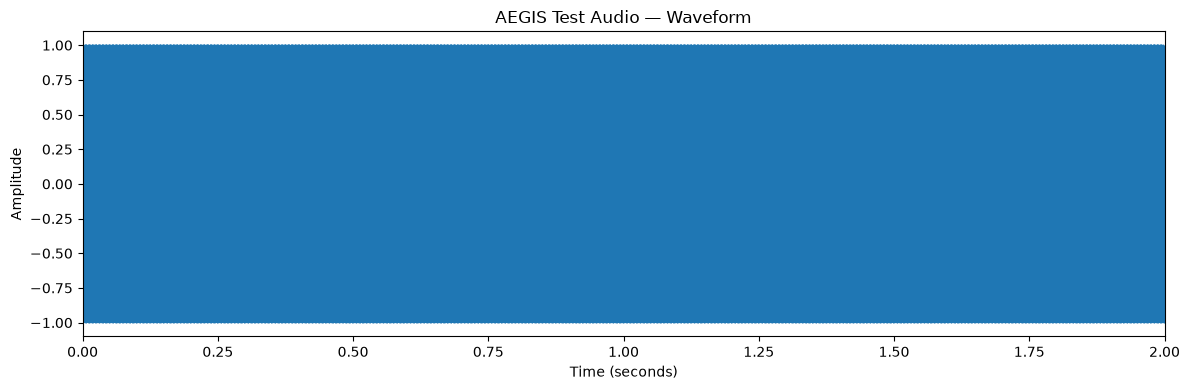

In [5]:
import matplotlib.pyplot as plt

# Create time axis
time_axis = np.arange(len(audio)) / loaded_sr

plt.figure(figsize=(12, 4))
plt.plot(time_axis, audio)

plt.title("AEGIS Test Audio — Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.xlim(0, duration)

plt.tight_layout()
plt.show()

In [6]:
# Generate Log-Mel Spectrogram

mel_spectrogram = librosa.feature.melspectrogram(
    y=audio,
    sr=loaded_sr,
    n_fft=1024,
    hop_length=160,
    n_mels=128,
    fmin=20,
    fmax=8000
)

log_mel = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)

print("Log-Mel spectrogram generated")
print("=" * 40)
print("Shape:", log_mel.shape)
print("Frequency range:", "20 Hz - 8000 Hz")
print("Mel bins:", log_mel.shape[0])
print("Time frames:", log_mel.shape[1])
print("Minimum dB:", log_mel.min())
print("Maximum dB:", log_mel.max())

Log-Mel spectrogram generated
Shape: (128, 201)
Frequency range: 20 Hz - 8000 Hz
Mel bins: 128
Time frames: 201
Minimum dB: -80.0
Maximum dB: 0.0


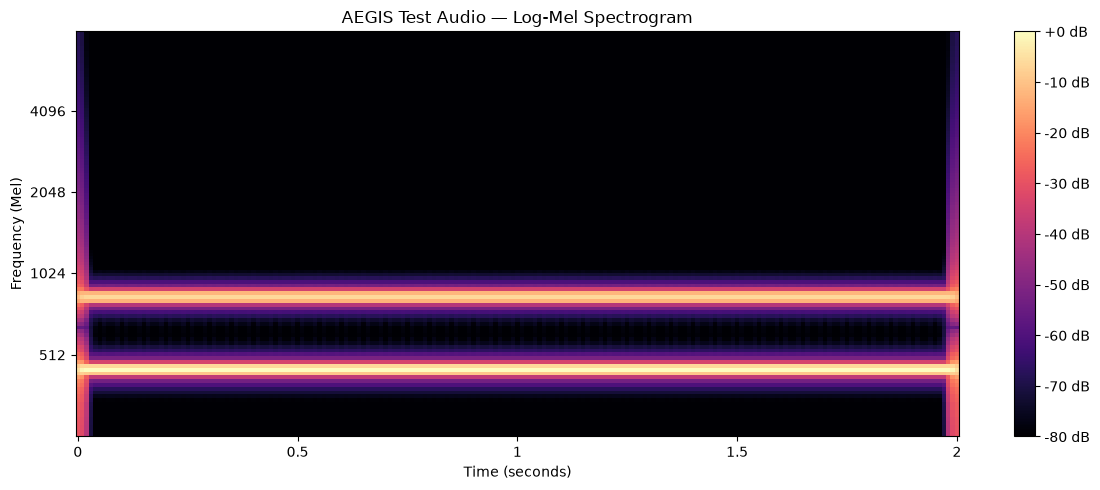

In [7]:
import matplotlib.pyplot as plt
import librosa.display

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    log_mel,
    sr=loaded_sr,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
    fmin=20,
    fmax=8000
)

plt.colorbar(format="%+2.0f dB")
plt.title("AEGIS Test Audio — Log-Mel Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Mel)")

plt.tight_layout()
plt.show()

In [8]:
# Save the Log-Mel spectrogram visualization

SPECTROGRAM_PATH = AUDIO_RESULTS_DIR / "aegis_test_log_mel.png"

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    log_mel,
    sr=loaded_sr,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
    fmin=20,
    fmax=8000
)

plt.colorbar(format="%+2.0f dB")
plt.title("AEGIS Test Audio — Log-Mel Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Mel)")

plt.tight_layout()
plt.savefig(SPECTROGRAM_PATH, dpi=200, bbox_inches="tight")
plt.close()

print("Spectrogram saved successfully")
print("=" * 40)
print("Path:", SPECTROGRAM_PATH)
print("File exists:", SPECTROGRAM_PATH.exists())

Spectrogram saved successfully
Path: d:\Projects\AEGIS\results\audio\aegis_test_log_mel.png
File exists: True


In [9]:
# Convert Log-Mel spectrogram to a PyTorch tensor

import torch

mel_tensor = torch.tensor(
    log_mel,
    dtype=torch.float32
)

print("PyTorch tensor created")
print("=" * 40)
print("Shape:", mel_tensor.shape)
print("Data type:", mel_tensor.dtype)
print("Minimum:", mel_tensor.min().item())
print("Maximum:", mel_tensor.max().item())

PyTorch tensor created
Shape: torch.Size([128, 201])
Data type: torch.float32
Minimum: -80.0
Maximum: 0.0


In [10]:
# Add channel dimension for neural-network input

mel_tensor = mel_tensor.unsqueeze(0)

print("Audio model input tensor")
print("=" * 40)
print("Shape:", mel_tensor.shape)
print("Channels:", mel_tensor.shape[0])
print("Mel bins:", mel_tensor.shape[1])
print("Time frames:", mel_tensor.shape[2])
print("Data type:", mel_tensor.dtype)

Audio model input tensor
Shape: torch.Size([1, 128, 201])
Channels: 1
Mel bins: 128
Time frames: 201
Data type: torch.float32


In [11]:
# AEGIS audio window configuration

TARGET_SAMPLE_RATE = 16_000
WINDOW_SECONDS = 2.56
HOP_LENGTH = 160
N_MELS = 128
N_FFT = 1024
FMIN = 20
FMAX = 8_000

TARGET_SAMPLES = int(TARGET_SAMPLE_RATE * WINDOW_SECONDS)

print("AEGIS Audio Window Configuration")
print("=" * 45)
print("Sample rate:", TARGET_SAMPLE_RATE, "Hz")
print("Window duration:", WINDOW_SECONDS, "seconds")
print("Target samples:", TARGET_SAMPLES)
print("Hop length:", HOP_LENGTH, "samples")
print("Mel bins:", N_MELS)
print("FFT size:", N_FFT)
print("Frequency range:", f"{FMIN} - {FMAX} Hz")

AEGIS Audio Window Configuration
Sample rate: 16000 Hz
Window duration: 2.56 seconds
Target samples: 40960
Hop length: 160 samples
Mel bins: 128
FFT size: 1024
Frequency range: 20 - 8000 Hz


In [12]:
# Create a fixed-length 2.56-second audio window

def make_fixed_audio_window(
    audio,
    target_samples,
    pad_value=0.0
):
    """Pad or crop audio to exactly target_samples."""
    
    if len(audio) >= target_samples:
        return audio[:target_samples]
    
    padded_audio = np.full(
        target_samples,
        pad_value,
        dtype=audio.dtype
    )
    
    padded_audio[:len(audio)] = audio
    
    return padded_audio


fixed_audio = make_fixed_audio_window(
    audio,
    TARGET_SAMPLES
)

print("Fixed-length audio window")
print("=" * 40)
print("Original samples:", len(audio))
print("Target samples:", TARGET_SAMPLES)
print("Final samples:", len(fixed_audio))
print("Final duration:", len(fixed_audio) / TARGET_SAMPLE_RATE, "seconds")
print("Padded samples:", TARGET_SAMPLES - len(audio))

Fixed-length audio window
Original samples: 32000
Target samples: 40960
Final samples: 40960
Final duration: 2.56 seconds
Padded samples: 8960


In [13]:
# ========================================
# Generate Log-Mel Spectrogram
# ========================================

mel_spectrogram = librosa.feature.melspectrogram(
    y=fixed_audio,
    sr=TARGET_SAMPLE_RATE,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    fmin=FMIN,
    fmax=FMAX
)

log_mel = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)

print("Log-Mel Spectrogram")
print("=" * 40)
print("Shape:", log_mel.shape)
print("Minimum dB:", log_mel.min())
print("Maximum dB:", log_mel.max())

Log-Mel Spectrogram
Shape: (128, 257)
Minimum dB: -80.0
Maximum dB: 0.0


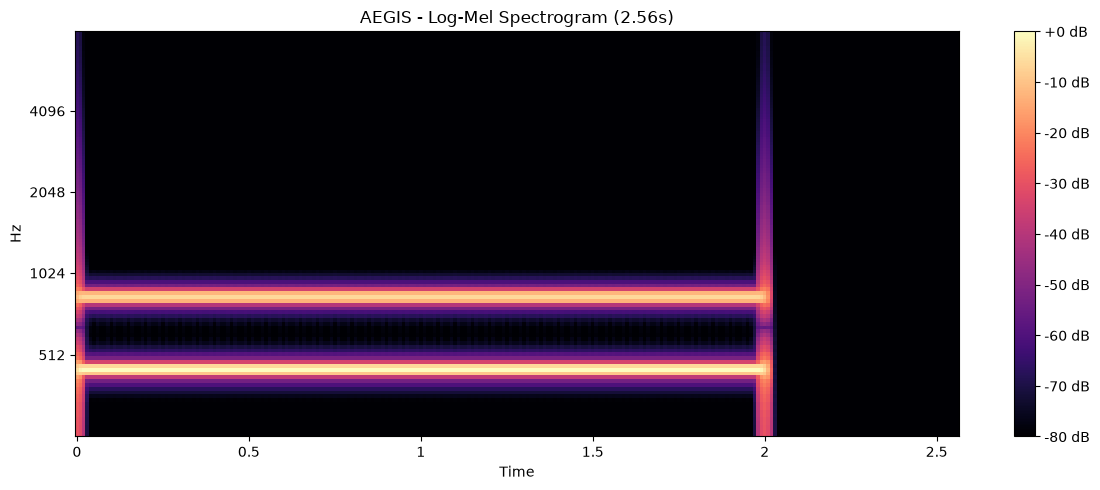

In [14]:
# ========================================
# Visualize Final Log-Mel Spectrogram
# ========================================

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    log_mel,
    sr=TARGET_SAMPLE_RATE,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    fmin=FMIN,
    fmax=FMAX
)

plt.colorbar(format="%+2.0f dB")
plt.title("AEGIS - Log-Mel Spectrogram (2.56s)")
plt.tight_layout()

plt.show()

In [15]:
# ========================================
# Generate CQT Spectrogram
# ========================================

CQT_FMIN = 65.4
CQT_BINS = 128
CQT_BINS_PER_OCTAVE = 24

cqt = librosa.cqt(
    fixed_audio,
    sr=TARGET_SAMPLE_RATE,
    fmin=CQT_FMIN,
    n_bins=CQT_BINS,
    bins_per_octave=CQT_BINS_PER_OCTAVE
)

cqt_db = librosa.amplitude_to_db(
    np.abs(cqt),
    ref=np.max
)

print("CQT Spectrogram")
print("=" * 40)
print("Shape:", cqt_db.shape)
print("Minimum dB:", cqt_db.min())
print("Maximum dB:", cqt_db.max())

CQT Spectrogram
Shape: (128, 81)
Minimum dB: -80.0
Maximum dB: 0.0


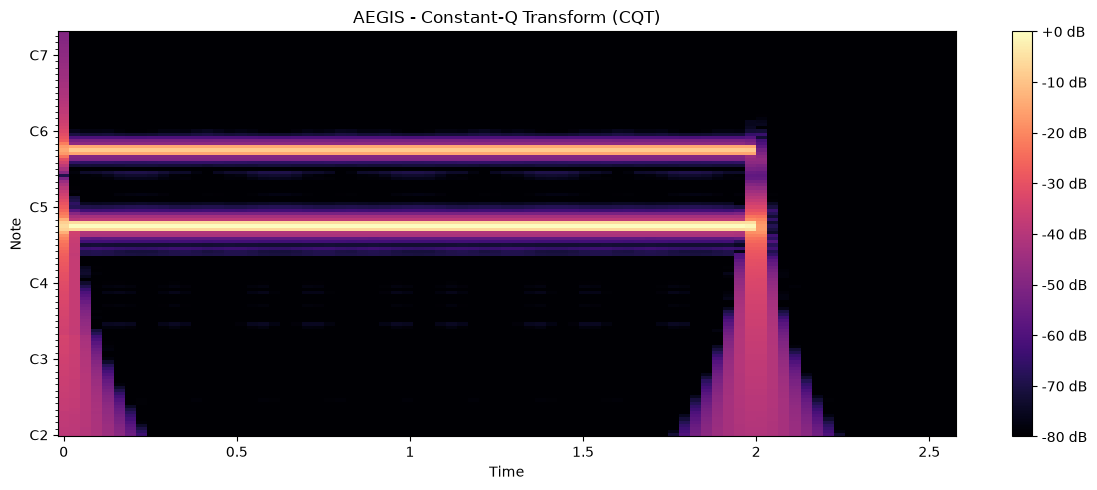

In [16]:
# ========================================
# Visualize CQT Spectrogram
# ========================================

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    cqt_db,
    sr=TARGET_SAMPLE_RATE,
    x_axis="time",
    y_axis="cqt_note",
    bins_per_octave=CQT_BINS_PER_OCTAVE,
    fmin=CQT_FMIN
)

plt.colorbar(format="%+2.0f dB")
plt.title("AEGIS - Constant-Q Transform (CQT)")
plt.tight_layout()

plt.show()

In [ ]:
# ========================================
# Correct CQT Alignment
# Resample Magnitude -> Convert to dB
# ========================================

cqt_magnitude = np.abs(cqt)

cqt_magnitude_aligned = resample(
    cqt_magnitude,
    target_time_frames,
    axis=1
)

cqt_aligned = librosa.amplitude_to_db(
    np.maximum(cqt_magnitude_aligned, 1e-10),
    ref=np.max
)

print("Corrected CQT Alignment")
print("=" * 40)
print("Original CQT shape:", cqt.shape)
print("Aligned CQT shape:", cqt_aligned.shape)
print("Minimum dB:", cqt_aligned.min())
print("Maximum dB:", cqt_aligned.max())

Proper CQT Alignment
Original CQT shape: (128, 81)
Target time frames: 257
Aligned CQT shape: (128, 257)
Aligned minimum dB: -90.07225
Aligned maximum dB: 6.5226164


In [20]:
# ========================================
# Correct CQT Alignment
# Resample Magnitude -> Convert to dB
# ========================================

cqt_magnitude = np.abs(cqt)

cqt_magnitude_aligned = resample(
    cqt_magnitude,
    target_time_frames,
    axis=1
)

cqt_aligned = librosa.amplitude_to_db(
    np.maximum(cqt_magnitude_aligned, 1e-10),
    ref=np.max
)

print("Corrected CQT Alignment")
print("=" * 40)
print("Original CQT shape:", cqt.shape)
print("Aligned CQT shape:", cqt_aligned.shape)
print("Minimum dB:", cqt_aligned.min())
print("Maximum dB:", cqt_aligned.max())

Corrected CQT Alignment
Original CQT shape: (128, 81)
Aligned CQT shape: (128, 257)
Minimum dB: -80.0
Maximum dB: 0.0


In [21]:
# ========================================
# Create 2-Channel Audio Representation
# ========================================

audio_features = np.stack(
    [log_mel, cqt_aligned],
    axis=0
)

print("AEGIS Audio Feature Tensor")
print("=" * 40)
print("Shape:", audio_features.shape)
print("Channel 0 (Log-Mel):", audio_features[0].shape)
print("Channel 1 (CQT):", audio_features[1].shape)
print("Data type:", audio_features.dtype)

AEGIS Audio Feature Tensor
Shape: (2, 128, 257)
Channel 0 (Log-Mel): (128, 257)
Channel 1 (CQT): (128, 257)
Data type: float32


In [22]:
# ========================================
# Save AEGIS Audio Feature Tensor
# ========================================

audio_features_tensor = torch.tensor(
    audio_features,
    dtype=torch.float32
)

output_path = "../data/audio_dev/processed/aegis_test_audio_features.pt"

torch.save(
    audio_features_tensor,
    output_path
)

print("Saved Audio Feature Tensor")
print("=" * 40)
print("Path:", output_path)
print("Shape:", audio_features_tensor.shape)
print("Data type:", audio_features_tensor.dtype)

Saved Audio Feature Tensor
Path: ../data/audio_dev/processed/aegis_test_audio_features.pt
Shape: torch.Size([2, 128, 257])
Data type: torch.float32


In [23]:
# ========================================
# Verify Saved Audio Feature Tensor
# ========================================

loaded_features = torch.load(
    "../data/audio_dev/processed/aegis_test_audio_features.pt",
    weights_only=True
)

print("Loaded Audio Feature Tensor")
print("=" * 40)
print("Shape:", loaded_features.shape)
print("Data type:", loaded_features.dtype)
print("Same shape:", loaded_features.shape == audio_features_tensor.shape)
print(
    "Same values:",
    torch.allclose(loaded_features, audio_features_tensor)
)

Loaded Audio Feature Tensor
Shape: torch.Size([2, 128, 257])
Data type: torch.float32
Same shape: True
Same values: True


In [24]:
# ========================================
# Create Audio Model Input Batch
# ========================================

audio_batch = loaded_features.unsqueeze(0)

print("AEGIS Audio Model Input")
print("=" * 40)
print("Shape:", audio_batch.shape)
print("Batch size:", audio_batch.shape[0])
print("Channels:", audio_batch.shape[1])
print("Frequency bins:", audio_batch.shape[2])
print("Time frames:", audio_batch.shape[3])

AEGIS Audio Model Input
Shape: torch.Size([1, 2, 128, 257])
Batch size: 1
Channels: 2
Frequency bins: 128
Time frames: 257


In [27]:
# ========================================
# AEGIS Audio Classifier
# ========================================

class AEGISAudioClassifier(nn.Module):

    def __init__(self, num_classes=2):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(2, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)


audio_model = AEGISAudioClassifier()

print(audio_model)

AEGISAudioClassifier(
  (features): Sequential(
    (0): Conv2d(2, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)


In [26]:
# ========================================
# Convert Audio Model Logits to Probabilities
# ========================================

probabilities = torch.softmax(test_output, dim=1)

authentic_probability = probabilities[0, 0].item()
manipulated_probability = probabilities[0, 1].item()

print("AEGIS Audio Prediction")
print("=" * 40)
print(f"Authentic probability:    {authentic_probability:.4f}")
print(f"Manipulated probability:  {manipulated_probability:.4f}")
print(f"Probability sum:          {probabilities.sum().item():.4f}")

AEGIS Audio Prediction
Authentic probability:    0.7757
Manipulated probability:  0.2243
Probability sum:          1.0000


In [28]:
# ========================================
# Verify AEGIS Audio Classifier
# ========================================

audio_model.eval()

with torch.no_grad():
    model_output = audio_model(audio_batch)

print("AEGIS Audio Classifier Test")
print("=" * 40)
print("Input shape:", audio_batch.shape)
print("Output shape:", model_output.shape)
print("Output logits:", model_output)

AEGIS Audio Classifier Test
Input shape: torch.Size([1, 2, 128, 257])
Output shape: torch.Size([1, 2])
Output logits: tensor([[-1.1357, -3.8028]])


In [29]:
# ========================================
# Count AEGIS Audio Model Parameters
# ========================================

total_params = sum(
    parameter.numel()
    for parameter in audio_model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in audio_model.parameters()
    if parameter.requires_grad
)

print("AEGIS Audio Model Parameters")
print("=" * 40)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

AEGIS Audio Model Parameters
Total parameters: 23794
Trainable parameters: 23794


In [32]:
# ========================================
# AEGIS Audio Dataset Metadata Template
# ========================================

import pandas as pd

audio_metadata_columns = [
    "sample_id",
    "file_path",
    "label",
    "source_dataset",
    "duration_sec",
    "sample_rate",
    "manipulation_type",
    "speaker_id",
    "split"
]

audio_metadata = pd.DataFrame(
    columns=audio_metadata_columns
)

metadata_path = "../data/audio_dev/processed/audio_metadata.csv"

audio_metadata.to_csv(
    metadata_path,
    index=False
)

print("Audio Metadata Template")
print("=" * 40)
print("Shape:", audio_metadata.shape)
print("Columns:", list(audio_metadata.columns))
print("Saved to:", metadata_path)

Audio Metadata Template
Shape: (0, 9)
Columns: ['sample_id', 'file_path', 'label', 'source_dataset', 'duration_sec', 'sample_rate', 'manipulation_type', 'speaker_id', 'split']
Saved to: ../data/audio_dev/processed/audio_metadata.csv


In [34]:
import os

# ========================================
# Verify Audio Metadata CSV
# ========================================

verified_metadata = pd.read_csv(metadata_path)

print("Verified Audio Metadata")
print("=" * 40)
print("Shape:", verified_metadata.shape)
print("Columns:", list(verified_metadata.columns))
print("File exists:", os.path.exists(metadata_path))

Verified Audio Metadata
Shape: (0, 9)
Columns: ['sample_id', 'file_path', 'label', 'source_dataset', 'duration_sec', 'sample_rate', 'manipulation_type', 'speaker_id', 'split']
File exists: True


In [35]:
# ========================================
# Add Synthetic Audio Sample Metadata
# ========================================

test_audio_path = "../data/audio_dev/raw/aegis_test_signal.wav"

test_record = {
    "sample_id": "aegis_test_001",
    "file_path": test_audio_path,
    "label": "authentic",
    "source_dataset": "synthetic_test",
    "duration_sec": 2.56,
    "sample_rate": 16000,
    "manipulation_type": "none",
    "speaker_id": "synthetic",
    "split": "dev"
}

audio_metadata = pd.DataFrame([test_record])

audio_metadata.to_csv(metadata_path, index=False)

print("Audio Metadata Record Created")
print("=" * 40)
print(audio_metadata)
print("\nSaved to:", metadata_path)

Audio Metadata Record Created
        sample_id                                    file_path      label  \
0  aegis_test_001  ../data/audio_dev/raw/aegis_test_signal.wav  authentic   

   source_dataset  duration_sec  sample_rate manipulation_type speaker_id  \
0  synthetic_test          2.56        16000              none  synthetic   

  split  
0   dev  

Saved to: ../data/audio_dev/processed/audio_metadata.csv


In [36]:
# ========================================
# Verify Audio File Referenced by Metadata
# ========================================

import os

metadata_check = pd.read_csv(metadata_path)

file_path = metadata_check.loc[0, "file_path"]

print("Sample ID:", metadata_check.loc[0, "sample_id"])
print("File Path:", file_path)
print("File Exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("Status: Audio file successfully linked to metadata.")
else:
    print("Status: Audio file NOT found.")

Sample ID: aegis_test_001
File Path: ../data/audio_dev/raw/aegis_test_signal.wav
File Exists: True
Status: Audio file successfully linked to metadata.


In [21]:
def preprocess_audio(
    audio_path,
    start_sec=0.0,
    window_seconds=2.56,
    target_sr=16000
):
    """
    Load one temporal audio window from an audio file.

    Parameters
    ----------
    audio_path : str or Path
        Path to the audio file.
    start_sec : float
        Start time of the window in seconds.
    window_seconds : float
        Required window duration.
    target_sr : int
        Target sampling rate.

    Returns
    -------
    waveform : np.ndarray
        Fixed-length float32 waveform.
    sample_rate : int
        Sampling rate of the returned waveform.
    """

    # Load the requested temporal window
    waveform, sample_rate = librosa.load(
        audio_path,
        sr=target_sr,
        mono=True,
        offset=float(start_sec),
        duration=float(window_seconds)
    )

    # Required number of samples
    target_samples = int(target_sr * window_seconds)

    # Pad short windows
    if len(waveform) < target_samples:
        waveform = np.pad(
            waveform,
            (0, target_samples - len(waveform)),
            mode="constant"
        )

    # Trim any possible excess samples
    elif len(waveform) > target_samples:
        waveform = waveform[:target_samples]

    # Safety checks
    waveform = waveform.astype(np.float32)

    if not np.isfinite(waveform).all():
        raise ValueError(
            f"Non-finite audio values detected: {audio_path}"
        )

    return waveform, sample_rate

In [22]:
test_row = window_index.iloc[1]

waveform, sr = preprocess_audio(
    test_row["file_path"],
    start_sec=test_row["start_sec"]
)

print("Window ID:", test_row["window_id"])
print("Sample rate:", sr)
print("Waveform shape:", waveform.shape)
print("Expected samples:", int(16000 * WINDOW_SEC))
print("Duration:", len(waveform) / sr)
print("Min:", waveform.min())
print("Max:", waveform.max())
print("Contains NaN:", np.isnan(waveform).any())
print("Contains Inf:", np.isinf(waveform).any())

Window ID: LA_T_1138215_w01
Sample rate: 16000
Waveform shape: (40960,)
Expected samples: 40960
Duration: 2.56
Min: -0.7444763
Max: 0.66293335
Contains NaN: False
Contains Inf: False


In [25]:
# ========================================
# Reusable Audio Feature Extraction
# ========================================

from scipy.signal import resample

def extract_audio_features(
    waveform,
    sr=16000,
    n_fft=1024,
    hop_length=160,
    n_mels=128,
    fmin=20,
    fmax=8000,
    cqt_fmin=65.4,
    cqt_bins=128,
    cqt_bins_per_octave=24,
    target_time_frames=257
):
    """
    Convert a fixed-length waveform into:
    [Log-Mel Spectrogram, CQT]

    Output shape: (2, 128, 257)
    """

    # -----------------------------
    # 1. Log-Mel Spectrogram
    # -----------------------------
    mel = librosa.feature.melspectrogram(
        y=waveform,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        fmin=fmin,
        fmax=fmax
    )

    log_mel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    # -----------------------------
    # 2. CQT
    # -----------------------------
    cqt = librosa.cqt(
        waveform,
        sr=sr,
        hop_length=hop_length,
        fmin=cqt_fmin,
        n_bins=cqt_bins,
        bins_per_octave=cqt_bins_per_octave
    )

    cqt_magnitude = np.abs(cqt)

    # Align CQT time dimension with Log-Mel
    cqt_aligned = resample(
        cqt_magnitude,
        target_time_frames,
        axis=1
    )

    cqt_aligned = librosa.amplitude_to_db(
        np.maximum(cqt_aligned, 1e-10),
        ref=np.max
    )

    # -----------------------------
    # 3. Stack Features
    # -----------------------------
    audio_features = np.stack(
        [log_mel, cqt_aligned],
        axis=0
    ).astype(np.float32)

    return audio_features


# Test feature extraction on the real ASVspoof window
test_features = extract_audio_features(
    waveform,
    sr=sr
)

print("Audio Feature Extraction Test")
print("=" * 40)
print("Feature shape:", test_features.shape)
print("Data type:", test_features.dtype)
print("Minimum:", test_features.min())
print("Maximum:", test_features.max())
print("Contains NaN:", np.isnan(test_features).any())
print("Contains Inf:", np.isinf(test_features).any())

Audio Feature Extraction Test
Feature shape: (2, 128, 257)
Data type: float32
Minimum: -80.0
Maximum: 0.0
Contains NaN: False
Contains Inf: False


In [27]:
# ========================================
# End-to-End Audio Window Test
# ========================================

test_row = window_index.iloc[1]

# 1. Load temporal window
window_waveform, window_sr = preprocess_audio(
    test_row["file_path"],
    start_sec=test_row["start_sec"],
    window_seconds=WINDOW_SEC,
    target_sr=16000
)

# 2. Extract features
window_features = extract_audio_features(
    window_waveform,
    sr=window_sr
)

print("=== AEGIS Audio Window Pipeline Test ===")
print("Window ID:", test_row["window_id"])
print("Label:", test_row["label"])
print("Start:", test_row["start_sec"])
print("End:", test_row["end_sec"])

print("\n--- Waveform ---")
print("Shape:", window_waveform.shape)
print("Sample rate:", window_sr)
print("Duration:", len(window_waveform) / window_sr)

print("\n--- Features ---")
print("Shape:", window_features.shape)
print("Dtype:", window_features.dtype)

print("\n--- Safety ---")
print("Waveform NaN:", np.isnan(window_waveform).any())
print("Waveform Inf:", np.isinf(window_waveform).any())
print("Feature NaN:", np.isnan(window_features).any())
print("Feature Inf:", np.isinf(window_features).any())

=== AEGIS Audio Window Pipeline Test ===
Window ID: LA_T_1138215_w01
Label: bonafide
Start: 1.28
End: 3.84

--- Waveform ---
Shape: (40960,)
Sample rate: 16000
Duration: 2.56

--- Features ---
Shape: (2, 128, 257)
Dtype: float32

--- Safety ---
Waveform NaN: False
Waveform Inf: False
Feature NaN: False
Feature Inf: False


In [29]:
# ========================================
# AEGIS Audio Dataset
# ========================================

import torch
from torch.utils.data import Dataset


class AEGISAudioDataset(Dataset):

    def __init__(
        self,
        window_index,
        target_sr=16000,
        window_seconds=2.56
    ):
        self.window_index = window_index.reset_index(drop=True)
        self.target_sr = target_sr
        self.window_seconds = window_seconds

    def __len__(self):
        return len(self.window_index)

    def __getitem__(self, idx):

        row = self.window_index.iloc[idx]

        # 1. Load temporal audio window
        waveform, sr = preprocess_audio(
            row["file_path"],
            start_sec=row["start_sec"],
            window_seconds=self.window_seconds,
            target_sr=self.target_sr
        )

        # 2. Extract Log-Mel + CQT features
        features = extract_audio_features(
            waveform,
            sr=sr
        )

        # 3. Convert to PyTorch tensor
        features = torch.from_numpy(features)

        # 4. Convert label
        label = 1 if row["label"] == "spoof" else 0

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return {
            "features": features,
            "label": label,
            "window_id": row["window_id"],
            "sample_id": row["sample_id"],
            "start_sec": row["start_sec"],
            "end_sec": row["end_sec"]
        }

In [30]:
# ========================================
# Test AEGIS Audio Dataset
# ========================================

test_dataset = AEGISAudioDataset(
    window_index=window_index
)

sample = test_dataset[0]

print("=== AEGIS Dataset Test ===")
print("Dataset length:", len(test_dataset))

print("\n--- Sample ---")
print("Window ID:", sample["window_id"])
print("Sample ID:", sample["sample_id"])
print("Start:", sample["start_sec"])
print("End:", sample["end_sec"])

print("\n--- Features ---")
print("Shape:", sample["features"].shape)
print("Dtype:", sample["features"].dtype)

print("\n--- Label ---")
print("Label:", sample["label"].item())

print("\n--- Safety ---")
print("Contains NaN:", torch.isnan(sample["features"]).any().item())
print("Contains Inf:", torch.isinf(sample["features"]).any().item())

=== AEGIS Dataset Test ===
Dataset length: 111236

--- Sample ---
Window ID: LA_T_1138215_w00
Sample ID: LA_T_1138215
Start: 0.0
End: 2.56

--- Features ---
Shape: torch.Size([2, 128, 257])
Dtype: torch.float32

--- Label ---
Label: 0

--- Safety ---
Contains NaN: False
Contains Inf: False


In [ ]:
# ========================================
# Verify Spoof Sample
# ========================================

spoof_index = window_index[
    window_index["label"] == "spoof"
].index[0]

spoof_sample = test_dataset[spoof_index]

print("=== AEGIS Spoof Sample Test ===")

print("Window ID:", spoof_sample["window_id"])
print("Sample ID:", spoof_sample["sample_id"])
print("Start:", spoof_sample["start_sec"])
print("End:", spoof_sample["end_sec"])

print("\n--- Features ---")
print("Shape:", spoof_sample["features"].shape)
print("Dtype:", spoof_sample["features"].dtype)

print("\n--- Label ---")
print("Label:", spoof_sample["label"].item())

print("\n--- Safety ---")
print(
    "Contains NaN:",
    torch.isnan(spoof_sample["features"]).any().item()
)

print(
    "Contains Inf:",
    torch.isinf(spoof_sample["features"]).any().item()
)

=== AEGIS Spoof Sample Test ===
Window ID: LA_T_1004644_w00
Sample ID: LA_T_1004644
Start: 0.0
End: 2.56

--- Features ---
Shape: torch.Size([2, 128, 257])
Dtype: torch.float32

--- Label ---
Label: 1

--- Safety ---
Contains NaN: False
Contains Inf: False


In [32]:
# ========================================
# Train / Validation DataLoaders
# ========================================

from torch.utils.data import DataLoader

# Split window index
train_window_index = window_index[
    window_index["split"] == "train"
].reset_index(drop=True)

val_window_index = window_index[
    window_index["split"] == "dev"
].reset_index(drop=True)

print("Train windows:", len(train_window_index))
print("Validation windows:", len(val_window_index))


# Create datasets
train_dataset = AEGISAudioDataset(
    window_index=train_window_index
)

val_dataset = AEGISAudioDataset(
    window_index=val_window_index
)


# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("\nDataLoaders created successfully.")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train windows: 55630
Validation windows: 55606

DataLoaders created successfully.
Train batches: 3477
Validation batches: 3476


In [33]:
# ========================================
# Test One Audio Batch
# ========================================

batch = next(iter(train_loader))

print("=== AEGIS Audio Batch Test ===")

print("\n--- Features ---")
print("Shape:", batch["features"].shape)
print("Dtype:", batch["features"].dtype)

print("\n--- Labels ---")
print("Shape:", batch["label"].shape)
print("Dtype:", batch["label"].dtype)
print("Unique labels:", torch.unique(batch["label"]).tolist())

print("\n--- Metadata ---")
print("First window:", batch["window_id"][0])
print("First sample:", batch["sample_id"][0])

print("\n--- Safety ---")
print(
    "Feature NaN:",
    torch.isnan(batch["features"]).any().item()
)

print(
    "Feature Inf:",
    torch.isinf(batch["features"]).any().item()
)

=== AEGIS Audio Batch Test ===

--- Features ---
Shape: torch.Size([16, 2, 128, 257])
Dtype: torch.float32

--- Labels ---
Shape: torch.Size([16])
Dtype: torch.int64
Unique labels: [0, 1]

--- Metadata ---
First window: LA_T_3192841_w02
First sample: LA_T_3192841

--- Safety ---
Feature NaN: False
Feature Inf: False


In [34]:
# ========================================
# Test Validation Batch
# ========================================

val_batch = next(iter(val_loader))

print("=== AEGIS Validation Batch Test ===")

print("\n--- Features ---")
print("Shape:", val_batch["features"].shape)
print("Dtype:", val_batch["features"].dtype)

print("\n--- Labels ---")
print("Shape:", val_batch["label"].shape)
print("Dtype:", val_batch["label"].dtype)
print("Unique labels:", torch.unique(val_batch["label"]).tolist())

print("\n--- Safety ---")
print(
    "Feature NaN:",
    torch.isnan(val_batch["features"]).any().item()
)

print(
    "Feature Inf:",
    torch.isinf(val_batch["features"]).any().item()
)

=== AEGIS Validation Batch Test ===

--- Features ---
Shape: torch.Size([16, 2, 128, 257])
Dtype: torch.float32

--- Labels ---
Shape: torch.Size([16])
Dtype: torch.int64
Unique labels: [0]

--- Safety ---
Feature NaN: False
Feature Inf: False


In [35]:
# ========================================
# Validation Class Distribution
# ========================================

print("=== Validation Class Distribution ===")

print(
    val_window_index["label"]
    .value_counts()
    .sort_index()
)

print("\nLabel percentages:")

print(
    val_window_index["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

=== Validation Class Distribution ===
label
bonafide     5678
spoof       49928
Name: count, dtype: int64

Label percentages:
label
bonafide    10.21
spoof       89.79
Name: proportion, dtype: float64


In [36]:
# ========================================
# Training Class Distribution
# ========================================

print("=== Training Class Distribution ===")

print(
    train_window_index["label"]
    .value_counts()
    .sort_index()
)

print("\nLabel percentages:")

print(
    train_window_index["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

=== Training Class Distribution ===
label
bonafide     5513
spoof       50117
Name: count, dtype: int64

Label percentages:
label
bonafide     9.91
spoof       90.09
Name: proportion, dtype: float64


In [37]:
# ========================================
# Calculate Class Weights
# ========================================

import torch

class_counts = (
    train_window_index["label"]
    .map({"bonafide": 0, "spoof": 1})
    .value_counts()
    .sort_index()
)

num_classes = len(class_counts)
total_samples = class_counts.sum()

class_weights = (
    total_samples /
    (num_classes * class_counts)
)

class_weights = torch.tensor(
    class_weights.values,
    dtype=torch.float32
)

print("=== AEGIS Class Weights ===")
print("Class counts:")
print(class_counts)

print("\nClass weights:")
print(class_weights)

print("\nMapping:")
print("Class 0 (bonafide):", class_weights[0].item())
print("Class 1 (spoof):", class_weights[1].item())

=== AEGIS Class Weights ===
Class counts:
label
0     5513
1    50117
Name: count, dtype: int64

Class weights:
tensor([5.0453, 0.5550])

Mapping:
Class 0 (bonafide): 5.045347213745117
Class 1 (spoof): 0.5550013184547424


In [38]:
# ========================================
# AEGIS Audio CNN Baseline
# ========================================

import torch.nn as nn


class AEGISAudioCNN(nn.Module):

    def __init__(self, num_classes=2):

        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=2,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # Reduce spatial dimensions
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(
            64,
            num_classes
        )

    def forward(self, x):

        x = self.features(x)

        x = torch.flatten(
            x,
            start_dim=1
        )

        x = self.classifier(x)

        return x

In [39]:
# ========================================
# Initialize AEGIS Audio CNN
# ========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AEGISAudioCNN(
    num_classes=2
).to(device)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=== AEGIS Audio CNN ===")
print("Device:", device)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

print("\nModel:")
print(model)

=== AEGIS Audio CNN ===
Device: cpu
Total parameters: 23794
Trainable parameters: 23794

Model:
AEGISAudioCNN(
  (features): Sequential(
    (0): Conv2d(2, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)


In [40]:
# ========================================
# Test CNN Forward Pass
# ========================================

model.eval()

with torch.no_grad():

    test_inputs = batch["features"].to(device)

    test_outputs = model(test_inputs)

print("=== AEGIS CNN Forward Pass Test ===")

print("\nInput shape:")
print(test_inputs.shape)

print("\nOutput shape:")
print(test_outputs.shape)

print("\nRaw model output:")
print(test_outputs)

print("\nPredicted classes:")
print(torch.argmax(test_outputs, dim=1).tolist())

print("\nSafety:")
print(
    "Output NaN:",
    torch.isnan(test_outputs).any().item()
)

print(
    "Output Inf:",
    torch.isinf(test_outputs).any().item()
)

=== AEGIS CNN Forward Pass Test ===

Input shape:
torch.Size([16, 2, 128, 257])

Output shape:
torch.Size([16, 2])

Raw model output:
tensor([[-2.5202,  4.5466],
        [-2.6491,  4.5532],
        [-2.5412,  4.1920],
        [-2.7920,  4.4966],
        [-2.8011,  4.7581],
        [-2.4599,  4.0377],
        [-3.5216,  5.2353],
        [-2.6446,  4.5387],
        [-2.6592,  4.6156],
        [-2.7975,  4.5097],
        [-3.1633,  5.0674],
        [-2.6321,  4.3969],
        [-2.7238,  4.6267],
        [-3.2366,  5.0623],
        [-3.1713,  5.0359],
        [-2.9803,  4.6384]])

Predicted classes:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Safety:
Output NaN: False
Output Inf: False


In [41]:
# ========================================
# AEGIS CNN Training Configuration
# ========================================

# Class-weighted CrossEntropyLoss
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("=== Training Configuration ===")
print("Loss:", criterion)
print("Optimizer:", optimizer)
print("Learning rate:", 0.001)
print("Class weights:", class_weights.tolist())

=== Training Configuration ===
Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001
Class weights: [5.045347213745117, 0.5550013184547424]


In [42]:
# ========================================
# Test Weighted Loss
# ========================================

model.train()

test_features = batch["features"].to(device)
test_labels = batch["label"].to(device)

test_logits = model(test_features)

test_loss = criterion(
    test_logits,
    test_labels
)

print("=== AEGIS Weighted Loss Test ===")

print("Logits shape:", test_logits.shape)
print("Labels shape:", test_labels.shape)

print("Loss:", test_loss.item())

print("Loss is finite:", torch.isfinite(test_loss).item())

=== AEGIS Weighted Loss Test ===
Logits shape: torch.Size([16, 2])
Labels shape: torch.Size([16])
Loss: 0.7382609248161316
Loss is finite: True


In [43]:
# ========================================
# Test Backpropagation
# ========================================

model.train()

optimizer.zero_grad()

test_features = batch["features"].to(device)
test_labels = batch["label"].to(device)

test_logits = model(test_features)

test_loss = criterion(
    test_logits,
    test_labels
)

test_loss.backward()

# Check whether gradients were produced
gradient_values = []

for parameter in model.parameters():
    if parameter.grad is not None:
        gradient_values.append(
            parameter.grad.abs().mean().item()
        )

print("=== AEGIS Backpropagation Test ===")

print("Loss:", test_loss.item())

print(
    "Parameters with gradients:",
    len(gradient_values)
)

print(
    "Total trainable parameters:",
    len(list(model.parameters()))
)

print(
    "Mean absolute gradient:",
    sum(gradient_values) / len(gradient_values)
)

print(
    "All gradients finite:",
    all(
        np.isfinite(value)
        for value in gradient_values
    )
)

=== AEGIS Backpropagation Test ===
Loss: 0.7382609248161316
Parameters with gradients: 14
Total trainable parameters: 14
Mean absolute gradient: 0.01496844196458369
All gradients finite: True


In [45]:
# ========================================
# AEGIS Training Function
# ========================================

def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    device
):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_data in dataloader:

        features = batch_data["features"].to(device)
        labels = batch_data["label"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        logits = model(features)

        # Calculate loss
        loss = criterion(
            logits,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += (
            loss.item() * labels.size(0)
        )

        predictions = torch.argmax(
            logits,
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [46]:
# ========================================
# AEGIS CNN - First Training Epoch
# ========================================

print("Starting first training epoch...")

train_loss, train_accuracy = train_one_epoch(
    model=model,
    dataloader=train_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device
)

print("\n=== Epoch 1 Training Result ===")
print("Training Loss:", train_loss)
print("Training Accuracy:", train_accuracy)

Starting first training epoch...

=== Epoch 1 Training Result ===
Training Loss: 0.2535084204345475
Training Accuracy: 0.9127449218047816


In [47]:
# ========================================
# AEGIS CNN Validation Function
# ========================================

def evaluate_model(
    model,
    dataloader,
    criterion,
    device
):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for batch_data in dataloader:

            features = batch_data["features"].to(device)
            labels = batch_data["label"].to(device)

            # Forward pass
            logits = model(features)

            # Loss
            loss = criterion(
                logits,
                labels
            )

            # Statistics
            running_loss += (
                loss.item() * labels.size(0)
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return (
        epoch_loss,
        epoch_accuracy,
        np.array(all_labels),
        np.array(all_predictions)
    )

In [48]:
# ========================================
# AEGIS CNN - Validation After Epoch 1
# ========================================

print("Starting validation...")

val_loss, val_accuracy, val_labels, val_predictions = evaluate_model(
    model=model,
    dataloader=val_loader,
    criterion=criterion,
    device=device
)

print("\n=== Validation Result ===")
print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

print("\nPrediction distribution:")
print(
    "Bonafide predictions:",
    (val_predictions == 0).sum()
)

print(
    "Spoof predictions:",
    (val_predictions == 1).sum() 
)

Starting validation...

=== Validation Result ===
Validation Loss: 0.8545259697319376
Validation Accuracy: 0.6270186670503183

Prediction distribution:
Bonafide predictions: 26418
Spoof predictions: 29188


In [50]:
# ========================================
# Save Extracted Audio Features
# ========================================

import torch
import os

feature_output_path = "../data/audio_dev/processed/aegis_test_audio_features_v2.pt"

audio_features_tensor = torch.tensor(
    test_features,
    dtype=torch.float32
)

torch.save(
    audio_features_tensor,
    feature_output_path
)

print("Audio Features Saved")
print("=" * 40)
print("Path:", feature_output_path)
print("Shape:", audio_features_tensor.shape)
print("Dtype:", audio_features_tensor.dtype)
print("File exists:", os.path.exists(feature_output_path))

Audio Features Saved
Path: ../data/audio_dev/processed/aegis_test_audio_features_v2.pt
Shape: torch.Size([16, 2, 128, 257])
Dtype: torch.float32
File exists: True


C:\Users\Harshvardhan Singh\AppData\Local\Temp\ipykernel_10376\284765005.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  audio_features_tensor = torch.tensor(


In [40]:
# ========================================
# Verify Saved Audio Features
# ========================================

loaded_features = torch.load(
    feature_output_path,
    weights_only=True
)

print("Saved Feature Verification")
print("=" * 40)
print("Loaded shape:", loaded_features.shape)
print("Loaded dtype:", loaded_features.dtype)
print("Shape matches:", loaded_features.shape == audio_features_tensor.shape)
print("Values match:", torch.equal(loaded_features, audio_features_tensor))
print("File exists:", os.path.exists(feature_output_path))

Saved Feature Verification
Loaded shape: torch.Size([2, 128, 257])
Loaded dtype: torch.float32
Shape matches: True
Values match: True
File exists: True


In [41]:
# ========================================
# AEGIS Audio Dataset Class
# ========================================

import torch
from torch.utils.data import Dataset

class AEGISAudioDataset(Dataset):

    def __init__(self, metadata_path):
        self.metadata = pd.read_csv(metadata_path)

        # Convert labels to numerical classes
        self.label_map = {
            "authentic": 0,
            "manipulated": 1
        }

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, index):

        row = self.metadata.iloc[index]

        # Audio path
        audio_path = row["file_path"]

        # Load + preprocess
        waveform, sr = preprocess_audio(audio_path)

        # Extract features
        features = extract_audio_features(
            waveform,
            sr=sr
        )

        # Convert to tensor
        features = torch.tensor(
            features,
            dtype=torch.float32
        )

        # Convert label
        label = self.label_map[row["label"]]

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return features, label


# Create dataset
audio_dataset = AEGISAudioDataset(metadata_path)

print("AEGIS Audio Dataset")
print("=" * 40)
print("Number of samples:", len(audio_dataset))

# Test first sample
sample_features, sample_label = audio_dataset[0]

print("Feature shape:", sample_features.shape)
print("Label:", sample_label.item())
print("Feature dtype:", sample_features.dtype)
print("Label dtype:", sample_label.dtype)

AEGIS Audio Dataset
Number of samples: 1
Feature shape: torch.Size([2, 128, 257])
Label: 0
Feature dtype: torch.float32
Label dtype: torch.int64


In [42]:
# ========================================
# AEGIS Audio DataLoader
# ========================================

from torch.utils.data import DataLoader

audio_loader = DataLoader(
    audio_dataset,
    batch_size=1,
    shuffle=False
)

# Get one batch
batch_features, batch_labels = next(iter(audio_loader))

print("AEGIS Audio DataLoader")
print("=" * 40)
print("Batch feature shape:", batch_features.shape)
print("Batch label shape:", batch_labels.shape)
print("Batch label:", batch_labels)
print("Feature dtype:", batch_features.dtype)
print("Label dtype:", batch_labels.dtype)

AEGIS Audio DataLoader
Batch feature shape: torch.Size([1, 2, 128, 257])
Batch label shape: torch.Size([1])
Batch label: tensor([0])
Feature dtype: torch.float32
Label dtype: torch.int64


In [43]:
# ========================================
# AEGIS Audio Model Forward Pass
# ========================================

audio_model = AEGISAudioClassifier(num_classes=2)

audio_model.eval()

with torch.no_grad():
    logits = audio_model(batch_features)

    probabilities = torch.softmax(logits, dim=1)

    predictions = torch.argmax(probabilities, dim=1)

print("AEGIS Audio Model Test")
print("=" * 40)
print("Input shape:", batch_features.shape)
print("Logits shape:", logits.shape)
print("Probabilities:", probabilities)
print("Prediction:", predictions)
print("Probability sum:", probabilities.sum(dim=1))

AEGIS Audio Model Test
Input shape: torch.Size([1, 2, 128, 257])
Logits shape: torch.Size([1, 2])
Probabilities: tensor([[0.8545, 0.1455]])
Prediction: tensor([0])
Probability sum: tensor([1.])


In [44]:
# ========================================
# AEGIS Audio Model Summary
# ========================================

total_params = sum(
    p.numel()
    for p in audio_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in audio_model.parameters()
    if p.requires_grad
)

print("AEGIS Audio Classifier")
print("=" * 40)
print("Model:", audio_model.__class__.__name__)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Input shape: [B, 2, 128, 257]")
print("Output classes: 2")
print("Class mapping:", {
    0: "authentic",
    1: "manipulated"
})

AEGIS Audio Classifier
Model: AEGISAudioClassifier
Total parameters: 23794
Trainable parameters: 23794
Input shape: [B, 2, 128, 257]
Output classes: 2
Class mapping: {0: 'authentic', 1: 'manipulated'}


In [45]:
# ========================================
# Save AEGIS Audio Model Configuration
# ========================================

import json
import os

audio_model_config = {
    "model_name": "AEGISAudioClassifier",
    "input_shape": [2, 128, 257],
    "num_classes": 2,
    "class_mapping": {
        "0": "authentic",
        "1": "manipulated"
    },
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "sample_rate": 16000,
    "window_seconds": 2.56,
    "features": [
        "log_mel",
        "cqt"
    ]
}

config_path = "../configs/audio_baseline_config.json"

with open(config_path, "w") as f:
    json.dump(audio_model_config, f, indent=4)

print("Audio Model Configuration Saved")
print("=" * 40)
print("Path:", config_path)
print("File exists:", os.path.exists(config_path))

Audio Model Configuration Saved
Path: ../configs/audio_baseline_config.json
File exists: True


In [46]:
# ========================================
# Verify Audio Model Configuration
# ========================================

with open(config_path, "r") as f:
    verified_config = json.load(f)

print("Verified Audio Model Configuration")
print("=" * 40)

for key, value in verified_config.items():
    print(f"{key}: {value}")

Verified Audio Model Configuration
model_name: AEGISAudioClassifier
input_shape: [2, 128, 257]
num_classes: 2
class_mapping: {'0': 'authentic', '1': 'manipulated'}
total_parameters: 23794
trainable_parameters: 23794
sample_rate: 16000
window_seconds: 2.56
features: ['log_mel', 'cqt']


In [47]:
# ========================================
# AEGIS Audio Model Factory
# ========================================

def create_audio_model(num_classes=2):
    """
    Create a fresh AEGIS audio classifier.
    """
    
    model = AEGISAudioClassifier(
        num_classes=num_classes
    )
    
    return model


# Test model factory
test_audio_model = create_audio_model()

print("AEGIS Audio Model Factory")
print("=" * 40)
print("Model:", test_audio_model.__class__.__name__)
print(
    "Parameters:",
    sum(p.numel() for p in test_audio_model.parameters())
)

AEGIS Audio Model Factory
Model: AEGISAudioClassifier
Parameters: 23794


In [48]:
# ========================================
# AEGIS Audio Training Setup
# ========================================

import torch.nn as nn
import torch.optim as optim

# Create a fresh model
train_model = create_audio_model()

# Classification loss
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    train_model.parameters(),
    lr=0.001
)

print("AEGIS Audio Training Setup")
print("=" * 40)
print("Model:", train_model.__class__.__name__)
print("Loss:", criterion.__class__.__name__)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

AEGIS Audio Training Setup
Model: AEGISAudioClassifier
Loss: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001


In [49]:
# ========================================
# AEGIS Audio Training Function
# ========================================

def train_audio_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    device="cpu"
):
    """
    Train the audio model for one epoch.
    Returns the average training loss.
    """

    model.train()

    total_loss = 0.0
    total_samples = 0

    for features, labels in dataloader:

        features = features.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        logits = model(features)

        # Calculate loss
        loss = criterion(logits, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track loss
        batch_size = features.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    average_loss = total_loss / total_samples

    return average_loss


print("Training function created successfully.")

Training function created successfully.


In [50]:
# ========================================
# Test One Training Epoch
# ========================================

test_train_model = create_audio_model()

test_criterion = nn.CrossEntropyLoss()

test_optimizer = optim.Adam(
    test_train_model.parameters(),
    lr=0.001
)

test_loss = train_audio_one_epoch(
    model=test_train_model,
    dataloader=audio_loader,
    criterion=test_criterion,
    optimizer=test_optimizer,
    device="cpu"
)

print("One-Epoch Training Test")
print("=" * 40)
print("Training loss:", test_loss)
print("Loss is finite:", np.isfinite(test_loss))

One-Epoch Training Test
Training loss: 0.6725736260414124
Loss is finite: True


In [51]:
# ========================================
# AEGIS Audio Evaluation Function
# ========================================

def evaluate_audio_model(
    model,
    dataloader,
    criterion,
    device="cpu"
):
    """
    Evaluate the audio model without updating its weights.
    """

    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for features, labels in dataloader:

            features = features.to(device)
            labels = labels.to(device)

            # Forward pass
            logits = model(features)

            # Loss
            loss = criterion(logits, labels)

            # Predictions
            predictions = torch.argmax(logits, dim=1)

            # Statistics
            batch_size = features.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "predictions": all_predictions,
        "labels": all_labels
    }


print("Evaluation function created successfully.")

Evaluation function created successfully.


In [52]:
# ========================================
# Test Audio Model Evaluation
# ========================================

evaluation_results = evaluate_audio_model(
    model=test_train_model,
    dataloader=audio_loader,
    criterion=test_criterion,
    device="cpu"
)

print("Audio Model Evaluation Test")
print("=" * 40)
print("Loss:", evaluation_results["loss"])
print("Accuracy:", evaluation_results["accuracy"])
print("Predictions:", evaluation_results["predictions"])
print("Labels:", evaluation_results["labels"])

Audio Model Evaluation Test
Loss: 0.7398525476455688
Accuracy: 0.0
Predictions: [np.int64(1)]
Labels: [np.int64(0)]


In [53]:
# ========================================
# Verify Model Weight Update
# ========================================

fresh_model = create_audio_model()

# Save a copy of the initial weights
initial_weights = {
    name: param.detach().clone()
    for name, param in fresh_model.named_parameters()
}

fresh_optimizer = optim.Adam(
    fresh_model.parameters(),
    lr=0.001
)

# Train for one epoch
_ = train_audio_one_epoch(
    model=fresh_model,
    dataloader=audio_loader,
    criterion=test_criterion,
    optimizer=fresh_optimizer,
    device="cpu"
)

# Compare weights
weights_changed = False

for name, param in fresh_model.named_parameters():
    if not torch.equal(initial_weights[name], param.detach()):
        weights_changed = True
        break

print("Model Weight Update Check")
print("=" * 40)
print("Weights changed after training:", weights_changed)

Model Weight Update Check
Weights changed after training: True


In [54]:
# ========================================
# Save AEGIS Audio Baseline Configuration
# ========================================

audio_baseline_config = {
    "sample_rate": 16000,
    "window_seconds": 2.56,
    "n_fft": 1024,
    "hop_length": 160,
    "n_mels": 128,
    "fmin": 20,
    "fmax": 8000,
    "cqt_fmin": 65.4,
    "cqt_bins": 128,
    "cqt_bins_per_octave": 24,
    "target_time_frames": 257,
    "input_channels": 2,
    "num_classes": 2,
    "label_mapping": {
        "authentic": 0,
        "manipulated": 1
    },
    "model": "AEGISAudioClassifier",
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "CrossEntropyLoss"
}

config_path = "../configs/audio_baseline_config.json"

with open(config_path, "w") as f:
    json.dump(audio_baseline_config, f, indent=4)

print("Audio baseline configuration saved.")
print("Path:", config_path)

Audio baseline configuration saved.
Path: ../configs/audio_baseline_config.json


In [55]:
# ========================================
# Verify Saved Audio Configuration
# ========================================

with open(config_path, "r") as f:
    loaded_config = json.load(f)

print("Configuration loaded successfully.")
print("=" * 40)

print("Sample Rate:", loaded_config["sample_rate"])
print("Window:", loaded_config["window_seconds"], "seconds")
print("Mel Bins:", loaded_config["n_mels"])
print("CQT Bins:", loaded_config["cqt_bins"])
print("Input Channels:", loaded_config["input_channels"])
print("Number of Classes:", loaded_config["num_classes"])
print("Model:", loaded_config["model"])
print("Learning Rate:", loaded_config["learning_rate"])

Configuration loaded successfully.
Sample Rate: 16000
Window: 2.56 seconds
Mel Bins: 128
CQT Bins: 128
Input Channels: 2
Number of Classes: 2
Model: AEGISAudioClassifier
Learning Rate: 0.001


In [56]:
# ========================================
# Real Audio File Discovery
# ========================================

from pathlib import Path

def discover_audio_files(root_dir):
    """
    Find supported audio files inside a directory.

    Supported formats:
    WAV, MP3, FLAC
    """

    root = Path(root_dir)

    if not root.exists():
        raise FileNotFoundError(
            f"Audio directory does not exist: {root}"
        )

    supported_extensions = {".wav", ".mp3", ".flac"}

    audio_files = sorted(
        [
            path
            for path in root.rglob("*")
            if path.is_file()
            and path.suffix.lower() in supported_extensions
        ]
    )

    return audio_files


# Test the function on our development audio directory
audio_dev_raw_dir = "../data/audio_dev/raw"

discovered_audio = discover_audio_files(audio_dev_raw_dir)

print("Audio Discovery Test")
print("=" * 40)
print("Directory:", audio_dev_raw_dir)
print("Audio files found:", len(discovered_audio))

for path in discovered_audio:
    print("-", path)

Audio Discovery Test
Directory: ../data/audio_dev/raw
Audio files found: 1
- ..\data\audio_dev\raw\aegis_test_signal.wav


In [57]:
# ========================================
# Build Audio Metadata from Discovered Files
# ========================================

def build_audio_metadata(audio_files, source_dataset="unknown"):
    """
    Create a metadata DataFrame from discovered audio files.
    """

    records = []

    for index, audio_path in enumerate(audio_files):

        waveform, sr = preprocess_audio(
            str(audio_path)
        )

        duration_sec = len(waveform) / sr

        record = {
            "sample_id": f"audio_{index + 1:06d}",
            "file_path": str(audio_path),
            "label": "unknown",
            "source_dataset": source_dataset,
            "duration_sec": duration_sec,
            "sample_rate": sr,
            "manipulation_type": "unknown",
            "speaker_id": "unknown",
            "split": "unassigned"
        }

        records.append(record)

    return pd.DataFrame(
        records,
        columns=audio_metadata_columns
    )


# Build metadata from discovered files
discovered_metadata = build_audio_metadata(
    discovered_audio,
    source_dataset="development"
)

print("Audio Metadata Test")
print("=" * 40)
print("Rows:", len(discovered_metadata))
print("Columns:", len(discovered_metadata.columns))

display(discovered_metadata)

Audio Metadata Test
Rows: 1
Columns: 9


,sample_id,file_path,label,source_dataset,duration_sec,sample_rate,manipulation_type,speaker_id,split
0,audio_000001,..\data\audio_dev\raw\aegis_test_signal.wav,unknown,development,2.56,16000,unknown,unknown,unassigned


In [58]:
# ========================================
# Validate Audio Metadata
# ========================================

def validate_audio_metadata(metadata):
    """
    Validate the required fields in the audio metadata.
    """

    required_columns = [
        "sample_id",
        "file_path",
        "label",
        "source_dataset",
        "duration_sec",
        "sample_rate",
        "manipulation_type",
        "speaker_id",
        "split"
    ]

    # Check required columns
    missing_columns = [
        column
        for column in required_columns
        if column not in metadata.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )

    # Check labels
    valid_labels = {"authentic", "manipulated", "unknown"}

    invalid_labels = set(metadata["label"].dropna()) - valid_labels

    if invalid_labels:
        raise ValueError(
            f"Invalid labels found: {invalid_labels}"
        )

    # Check sample rates
    if (metadata["sample_rate"] <= 0).any():
        raise ValueError("Invalid sample rate detected.")

    # Check durations
    if (metadata["duration_sec"] <= 0).any():
        raise ValueError("Invalid duration detected.")

    # Check file paths
    missing_files = [
        path
        for path in metadata["file_path"]
        if not Path(path).exists()
    ]

    if missing_files:
        raise FileNotFoundError(
            f"{len(missing_files)} audio files were not found."
        )

    return True


# Validate current metadata
metadata_valid = validate_audio_metadata(discovered_metadata)

print("Audio metadata validation passed:", metadata_valid)

Audio metadata validation passed: True


In [59]:
# ========================================
# Check for Real Dataset Files
# ========================================

from pathlib import Path

raw_data_dir = Path("../data/raw")

print("AEGIS Real Dataset Check")
print("=" * 40)

if not raw_data_dir.exists():
    print("data/raw directory does not exist.")
else:
    all_files = [
        path for path in raw_data_dir.rglob("*")
        if path.is_file()
    ]

    print("Files found in data/raw:", len(all_files))

    if len(all_files) == 0:
        print("No real dataset files found yet.")
    else:
        print("\nSample files:")

        for path in all_files[:10]:
            print("-", path)

AEGIS Real Dataset Check
Files found in data/raw: 0
No real dataset files found yet.


In [1]:
from pathlib import Path
import pandas as pd


# ---------------------------------------------------------
# ASVspoof 2019 LA — CM Protocol Parser
# ---------------------------------------------------------

PROJECT_ROOT = Path("..").resolve()

ASVSPOOF_ROOT = (
    PROJECT_ROOT
    / "data"
    / "audio_dev"
    / "raw"
    / "asvspoof2019"
    / "LA"
)

CM_PROTOCOL_DIR = ASVSPOOF_ROOT / "ASVspoof2019_LA_cm_protocols"

TRAIN_AUDIO_DIR = (
    ASVSPOOF_ROOT
    / "ASVspoof2019_LA_train"
    / "flac"
)

DEV_AUDIO_DIR = (
    ASVSPOOF_ROOT
    / "ASVspoof2019_LA_dev"
    / "flac"
)


def parse_cm_protocol(protocol_path, audio_dir, split):
    """
    Parse an ASVspoof 2019 LA CM protocol file.

    Expected format:
        speaker_id utterance_id field_3 attack_id label
    """

    protocol_path = Path(protocol_path)
    audio_dir = Path(audio_dir)

    records = []

    lines = protocol_path.read_text(
        encoding="utf-8"
    ).splitlines()

    for line_number, line in enumerate(lines, start=1):

        line = line.strip()

        if not line:
            continue

        fields = line.split()

        if len(fields) != 5:
            raise ValueError(
                f"Unexpected format at line {line_number}: {line}"
            )

        speaker_id = fields[0]
        utterance_id = fields[1]
        field_3 = fields[2]
        attack_id = fields[3]
        label = fields[4]

        audio_path = audio_dir / f"{utterance_id}.flac"

        records.append(
            {
                "sample_id": utterance_id,
                "file_path": str(audio_path),
                "speaker_id": speaker_id,
                "utterance_id": utterance_id,
                "field_3": field_3,
                "attack_id": attack_id,
                "label": label,
                "source_dataset": "ASVspoof2019_LA",
                "split": split,
            }
        )

    return pd.DataFrame(records)


# ---------------------------------------------------------
# Parse TRAIN
# ---------------------------------------------------------

train_protocol = (
    CM_PROTOCOL_DIR
    / "ASVspoof2019.LA.cm.train.trn.txt"
)

train_metadata = parse_cm_protocol(
    train_protocol,
    TRAIN_AUDIO_DIR,
    "train"
)


# ---------------------------------------------------------
# Parse DEV
# ---------------------------------------------------------

dev_protocol = (
    CM_PROTOCOL_DIR
    / "ASVspoof2019.LA.cm.dev.trl.txt"
)

dev_metadata = parse_cm_protocol(
    dev_protocol,
    DEV_AUDIO_DIR,
    "dev"
)


# ---------------------------------------------------------
# Combine
# ---------------------------------------------------------

audio_metadata = pd.concat(
    [train_metadata, dev_metadata],
    ignore_index=True
)


print("Metadata shape:", audio_metadata.shape)
print()
print(audio_metadata.head())

Metadata shape: (50224, 9)

      sample_id                                          file_path speaker_id  \
0  LA_T_1138215  D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...    LA_0079   
1  LA_T_1271820  D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...    LA_0079   
2  LA_T_1272637  D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...    LA_0079   
3  LA_T_1276960  D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...    LA_0079   
4  LA_T_1341447  D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...    LA_0079   

   utterance_id field_3 attack_id     label   source_dataset  split  
0  LA_T_1138215       -         -  bonafide  ASVspoof2019_LA  train  
1  LA_T_1271820       -         -  bonafide  ASVspoof2019_LA  train  
2  LA_T_1272637       -         -  bonafide  ASVspoof2019_LA  train  
3  LA_T_1276960       -         -  bonafide  ASVspoof2019_LA  train  
4  LA_T_1341447       -         -  bonafide  ASVspoof2019_LA  train  


In [2]:
# ---------------------------------------------------------
# Validate ASVspoof metadata
# ---------------------------------------------------------

print("Total samples:", len(audio_metadata))

# 1. Split counts
print("\nSplit counts:")
print(audio_metadata["split"].value_counts())

# 2. Label counts
print("\nLabel counts:")
print(audio_metadata["label"].value_counts())

# 3. Duplicate IDs
duplicate_ids = audio_metadata["sample_id"].duplicated().sum()
print("\nDuplicate sample IDs:", duplicate_ids)

# 4. Unique labels
print("\nUnique labels:")
print(sorted(audio_metadata["label"].unique()))

# 5. Check that every referenced audio file exists
file_exists = audio_metadata["file_path"].map(
    lambda path: Path(path).exists()
)

print("\nMissing audio files:", (~file_exists).sum())

# 6. Check expected split counts
expected_counts = {
    "train": 25380,
    "dev": 24844
}

actual_counts = audio_metadata["split"].value_counts().to_dict()

print("\nExpected vs actual:")
for split, expected in expected_counts.items():
    actual = actual_counts.get(split, 0)
    print(f"{split}: expected={expected}, actual={actual}")

Total samples: 50224

Split counts:
split
train    25380
dev      24844
Name: count, dtype: int64

Label counts:
label
spoof       45096
bonafide     5128
Name: count, dtype: int64

Duplicate sample IDs: 0

Unique labels:
['bonafide', 'spoof']

Missing audio files: 0

Expected vs actual:
train: expected=25380, actual=25380
dev: expected=24844, actual=24844


In [3]:
# ---------------------------------------------------------
# Save validated ASVspoof metadata
# ---------------------------------------------------------

metadata_output = (
    PROJECT_ROOT
    / "data"
    / "audio_dev"
    / "processed"
    / "asvspoof2019_la_metadata.csv"
)

metadata_output.parent.mkdir(
    parents=True,
    exist_ok=True
)

audio_metadata.to_csv(
    metadata_output,
    index=False
)

print(f"Saved metadata to: {metadata_output}")
print(f"Rows: {len(audio_metadata)}")
print(f"Columns: {len(audio_metadata.columns)}")

Saved metadata to: D:\Projects\AEGIS\data\audio_dev\processed\asvspoof2019_la_metadata.csv
Rows: 50224
Columns: 9


In [4]:
# ---------------------------------------------------------
# ASVspoof 2019 LA — Basic Dataset EDA
# ---------------------------------------------------------

print("Dataset shape:", audio_metadata.shape)

print("\n--- Split distribution ---")
print(audio_metadata["split"].value_counts())

print("\n--- Label distribution ---")
label_counts = audio_metadata["label"].value_counts()
print(label_counts)

print("\n--- Label distribution (%) ---")
label_percent = (
    audio_metadata["label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)
print(label_percent)

print("\n--- Attack ID distribution ---")
print(audio_metadata["attack_id"].value_counts().head(20))

print("\n--- Number of unique speakers ---")
print(audio_metadata["speaker_id"].nunique())

print("\n--- Speakers per split ---")
print(
    audio_metadata.groupby("split")["speaker_id"]
    .nunique()
)

Dataset shape: (50224, 9)

--- Split distribution ---
split
train    25380
dev      24844
Name: count, dtype: int64

--- Label distribution ---
label
spoof       45096
bonafide     5128
Name: count, dtype: int64

--- Label distribution (%) ---
label
spoof       89.79
bonafide    10.21
Name: proportion, dtype: float64

--- Attack ID distribution ---
attack_id
A01    7516
A02    7516
A03    7516
A04    7516
A05    7516
A06    7516
-      5128
Name: count, dtype: int64

--- Number of unique speakers ---
40

--- Speakers per split ---
split
dev      20
train    20
Name: speaker_id, dtype: int64


In [5]:
# ---------------------------------------------------------
# Speaker overlap check
# ---------------------------------------------------------

train_speakers = set(
    audio_metadata.loc[
        audio_metadata["split"] == "train",
        "speaker_id"
    ]
)

dev_speakers = set(
    audio_metadata.loc[
        audio_metadata["split"] == "dev",
        "speaker_id"
    ]
)

speaker_overlap = train_speakers.intersection(dev_speakers)

print("Train speakers:", len(train_speakers))
print("Dev speakers:", len(dev_speakers))
print("Speaker overlap:", len(speaker_overlap))

if speaker_overlap:
    print("\nOverlapping speakers:")
    print(sorted(speaker_overlap))
else:
    print("\nNo speaker overlap detected.")

Train speakers: 20
Dev speakers: 20
Speaker overlap: 0

No speaker overlap detected.


In [6]:
# ---------------------------------------------------------
# Inspect real ASVspoof audio properties
# ---------------------------------------------------------

import librosa
import numpy as np

sample_rows = audio_metadata.sample(
    n=10,
    random_state=42
)

audio_properties = []

for _, row in sample_rows.iterrows():

    waveform, sr = librosa.load(
        row["file_path"],
        sr=None,
        mono=False
    )

    if waveform.ndim == 1:
        channels = 1
        num_samples = waveform.shape[0]
    else:
        channels = waveform.shape[0]
        num_samples = waveform.shape[-1]

    duration_sec = num_samples / sr

    audio_properties.append({
        "sample_id": row["sample_id"],
        "label": row["label"],
        "split": row["split"],
        "sample_rate": sr,
        "channels": channels,
        "duration_sec": duration_sec,
        "min_amplitude": float(np.min(waveform)),
        "max_amplitude": float(np.max(waveform)),
    })

audio_properties_df = pd.DataFrame(audio_properties)

print(audio_properties_df.to_string(index=False))

print("\n--- Summary ---")
print(
    audio_properties_df[
        [
            "sample_rate",
            "channels",
            "duration_sec"
        ]
    ].describe()
)

   sample_id    label split  sample_rate  channels  duration_sec  min_amplitude  max_amplitude
LA_T_1142427    spoof train        16000         1      2.250688      -0.965973       0.999969
LA_T_9762480 bonafide train        16000         1      3.537812      -1.000000       0.940735
LA_T_7563338    spoof train        16000         1      2.999812      -0.946289       0.999969
LA_T_2198970    spoof train        16000         1      4.951000      -0.953278       0.999969
LA_T_6244854    spoof train        16000         1      3.152563      -0.836639       0.999969
LA_D_6214703    spoof   dev        16000         1      1.310000      -0.707001       0.999969
LA_T_1054206    spoof train        16000         1      2.974375      -1.000000       0.953552
LA_T_2929732    spoof train        16000         1      1.351375      -1.000000       0.678436
LA_D_3890144    spoof   dev        16000         1      2.058937      -0.827789       0.999969
LA_D_7422452    spoof   dev        16000         1

In [8]:
import soundfile as sf
from tqdm.auto import tqdm

duration_records = []

for _, row in tqdm(
    audio_metadata.iterrows(),
    total=len(audio_metadata),
    desc="Reading audio metadata"
):
    info = sf.info(row["file_path"])

    duration_records.append({
        "sample_id": row["sample_id"],
        "label": row["label"],
        "split": row["split"],
        "sample_rate": info.samplerate,
        "channels": info.channels,
        "duration_sec": info.duration
    })

duration_df = pd.DataFrame(duration_records)

print(duration_df.head())

print("\n--- Overall duration statistics ---")
print(duration_df["duration_sec"].describe())

print("\n--- Duration by split ---")
print(
    duration_df.groupby("split")["duration_sec"].describe()
)

print("\n--- Duration by label ---")
print(
    duration_df.groupby("label")["duration_sec"].describe()
)

Reading audio metadata:   0%|          | 0/50224 [00:00<?, ?it/s]

      sample_id     label  split  sample_rate  channels  duration_sec
0  LA_T_1138215  bonafide  train        16000         1      3.458063
1  LA_T_1271820  bonafide  train        16000         1      4.395187
2  LA_T_1272637  bonafide  train        16000         1      2.899500
3  LA_T_1276960  bonafide  train        16000         1      2.812562
4  LA_T_1341447  bonafide  train        16000         1      3.533187

--- Overall duration statistics ---
count    50224.000000
mean         3.451690
std          1.438735
min          0.652438
25%          2.438984
50%          3.239875
75%          4.172641
max         13.187938
Name: duration_sec, dtype: float64

--- Duration by split ---
         count      mean       std       min       25%       50%       75%  \
split                                                                        
dev    24844.0  3.478113  1.458300  0.695125  2.444172  3.279688  4.225125   
train  25380.0  3.425824  1.418875  0.652438  2.434594  3.201531  4.109

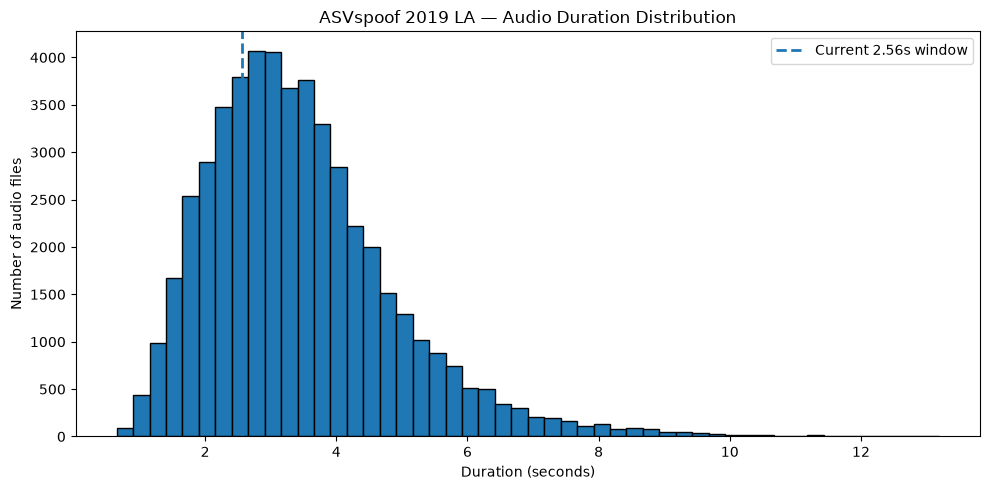

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    duration_df["duration_sec"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    2.56,
    linestyle="--",
    linewidth=2,
    label="Current 2.56s window"
)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of audio files")
plt.title("ASVspoof 2019 LA — Audio Duration Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
window_256 = 2.56
window_512 = 5.12

print("=== Impact of Window Size ===")

shorter_than_256 = (duration_df["duration_sec"] < window_256).sum()
between_256_512 = (
    (duration_df["duration_sec"] >= window_256) &
    (duration_df["duration_sec"] < window_512)
).sum()
longer_than_512 = (duration_df["duration_sec"] >= window_512).sum()

total = len(duration_df)

print(f"< 2.56s  : {shorter_than_256:,} ({shorter_than_256 / total * 100:.2f}%)")
print(f"2.56–5.12s: {between_256_512:,} ({between_256_512 / total * 100:.2f}%)")
print(f">= 5.12s : {longer_than_512:,} ({longer_than_512 / total * 100:.2f}%)")

=== Impact of Window Size ===
< 2.56s  : 14,377 (28.63%)
2.56–5.12s: 30,034 (59.80%)
>= 5.12s : 5,813 (11.57%)


In [11]:
print("=== Duration Bucket Distribution by Label ===")

duration_df["duration_bucket"] = pd.cut(
    duration_df["duration_sec"],
    bins=[0, 2.56, 5.12, float("inf")],
    labels=["< 2.56s", "2.56–5.12s", "≥ 5.12s"],
    right=False
)

bucket_by_label = pd.crosstab(
    duration_df["label"],
    duration_df["duration_bucket"],
    normalize="index"
) * 100

print(bucket_by_label.round(2))

=== Duration Bucket Distribution by Label ===
duration_bucket  < 2.56s  2.56–5.12s  ≥ 5.12s
label                                        
bonafide           19.95       73.79     6.26
spoof              29.61       58.21    12.18


In [12]:
import numpy as np

WINDOW_SEC = 2.56
HOP_SEC = 1.28


def count_windows(duration_sec, window_sec=WINDOW_SEC, hop_sec=HOP_SEC):
    if duration_sec <= window_sec:
        return 1

    return int(np.ceil((duration_sec - window_sec) / hop_sec)) + 1


duration_df["num_windows"] = duration_df["duration_sec"].apply(
    count_windows
)

print("=== Windowing Statistics ===")

print(f"Total audio files: {len(duration_df):,}")
print(f"Total windows: {duration_df['num_windows'].sum():,}")

print("\n--- Windows per recording ---")
print(duration_df["num_windows"].describe())

print("\n--- Windows by split ---")
print(
    duration_df.groupby("split")["num_windows"]
    .agg(["count", "sum", "mean", "median", "max"])
)

print("\n--- Windows by label ---")
print(
    duration_df.groupby("label")["num_windows"]
    .agg(["count", "sum", "mean", "median", "max"])
)

=== Windowing Statistics ===
Total audio files: 50,224
Total windows: 111,236

--- Windows per recording ---
count    50224.000000
mean         2.214798
std          1.127575
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         10.000000
Name: num_windows, dtype: float64

--- Windows by split ---
       count    sum      mean  median  max
split                                     
dev    24844  55606  2.238206     2.0    9
train  25380  55630  2.191883     2.0   10

--- Windows by label ---
          count     sum      mean  median  max
label                                         
bonafide   5128   11191  2.182332     2.0    8
spoof     45096  100045  2.218489     2.0   10


In [13]:
from pathlib import Path
import pandas as pd
import numpy as np

WINDOW_SEC = 2.56
HOP_SEC = 1.28


def create_window_index(metadata_df, window_sec=WINDOW_SEC, hop_sec=HOP_SEC):
    records = []

    for _, row in metadata_df.iterrows():
        duration = float(
            duration_df.loc[
                duration_df["sample_id"] == row["sample_id"],
                "duration_sec"
            ].iloc[0]
        )

        if duration <= window_sec:
            starts = [0.0]
        else:
            num_windows = int(
                np.ceil((duration - window_sec) / hop_sec)
            ) + 1

            starts = [
                i * hop_sec
                for i in range(num_windows)
            ]

        for window_idx, start_sec in enumerate(starts):
            end_sec = start_sec + window_sec

            records.append({
                "window_id": f"{row['sample_id']}_w{window_idx:02d}",
                "sample_id": row["sample_id"],
                "file_path": row["file_path"],
                "speaker_id": row["speaker_id"],
                "utterance_id": row["utterance_id"],
                "label": row["label"],
                "attack_id": row["attack_id"],
                "split": row["split"],
                "start_sec": round(start_sec, 4),
                "end_sec": round(end_sec, 4),
                "duration_sec": duration,
                "requires_padding": end_sec > duration
            })

    return pd.DataFrame(records)


window_index = create_window_index(audio_metadata)

print("Window index shape:", window_index.shape)

print("\nFirst 10 windows:")
display(window_index.head(10))

print("\nWindows by split:")
print(window_index["split"].value_counts())

print("\nWindows by label:")
print(window_index["label"].value_counts())

print("\nWindows requiring padding:")
print(
    window_index["requires_padding"]
    .value_counts()
)

Window index shape: (111236, 12)

First 10 windows:


,window_id,sample_id,file_path,speaker_id,utterance_id,label,attack_id,split,start_sec,end_sec,duration_sec,requires_padding
0,LA_T_1138215_w00,LA_T_1138215,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1138215,bonafide,-,train,0.00,2.56,3.458063,False
1,LA_T_1138215_w01,LA_T_1138215,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1138215,bonafide,-,train,1.28,3.84,3.458063,True
2,LA_T_1271820_w00,LA_T_1271820,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1271820,bonafide,-,train,0.00,2.56,4.395187,False
3,LA_T_1271820_w01,LA_T_1271820,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1271820,bonafide,-,train,1.28,3.84,4.395187,False
4,LA_T_1271820_w02,LA_T_1271820,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1271820,bonafide,-,train,2.56,5.12,4.395187,True
5,LA_T_1272637_w00,LA_T_1272637,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1272637,bonafide,-,train,0.00,2.56,2.899500,False
6,LA_T_1272637_w01,LA_T_1272637,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1272637,bonafide,-,train,1.28,3.84,2.899500,True
7,LA_T_1276960_w00,LA_T_1276960,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1276960,bonafide,-,train,0.00,2.56,2.812562,False
8,LA_T_1276960_w01,LA_T_1276960,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1276960,bonafide,-,train,1.28,3.84,2.812562,True
9,LA_T_1341447_w00,LA_T_1341447,D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2...,LA_0079,LA_T_1341447,bonafide,-,train,0.00,2.56,3.533187,False



Windows by split:
split
train    55630
dev      55606
Name: count, dtype: int64

Windows by label:
label
spoof       100045
bonafide     11191
Name: count, dtype: int64

Windows requiring padding:
requires_padding
False    61016
True     50220
Name: count, dtype: int64


In [14]:
WINDOW_INDEX_PATH = (
    PROJECT_ROOT
    / "data"
    / "audio_dev"
    / "processed"
    / "asvspoof2019_la_window_index.csv"
)

window_index.to_csv(
    WINDOW_INDEX_PATH,
    index=False
)

print("Saved window index:")
print(WINDOW_INDEX_PATH)

print("\nFile exists:", WINDOW_INDEX_PATH.exists())
print("Rows saved:", len(window_index))

Saved window index:
D:\Projects\AEGIS\data\audio_dev\processed\asvspoof2019_la_window_index.csv

File exists: True
Rows saved: 111236


In [15]:
import librosa
import numpy as np

# Select one real ASVspoof window
test_row = window_index.iloc[0]

audio_path = test_row["file_path"]
start_sec = test_row["start_sec"]
end_sec = test_row["end_sec"]

print("Window ID:", test_row["window_id"])
print("Audio:", audio_path)
print("Start:", start_sec)
print("End:", end_sec)

# Load only the required window
waveform, sr = librosa.load(
    audio_path,
    sr=16000,
    mono=True,
    offset=start_sec,
    duration=WINDOW_SEC
)

expected_samples = int(16000 * WINDOW_SEC)

print("\n--- Extracted Window ---")
print("Sample rate:", sr)
print("Samples before padding:", len(waveform))
print("Expected samples:", expected_samples)
print("Duration:", len(waveform) / sr)
print("Min:", waveform.min())
print("Max:", waveform.max())
print("Contains NaN:", np.isnan(waveform).any())
print("Contains Inf:", np.isinf(waveform).any())

Window ID: LA_T_1138215_w00
Audio: D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA\ASVspoof2019_LA_train\flac\LA_T_1138215.flac
Start: 0.0
End: 2.56

--- Extracted Window ---
Sample rate: 16000
Samples before padding: 40960
Expected samples: 40960
Duration: 2.56
Min: -1.0
Max: 0.97402954
Contains NaN: False
Contains Inf: False


In [16]:
import librosa
import numpy as np

test_row = window_index.iloc[1]

audio_path = test_row["file_path"]
start_sec = test_row["start_sec"]

waveform, sr = librosa.load(
    audio_path,
    sr=16000,
    mono=True,
    offset=start_sec,
    duration=WINDOW_SEC
)

expected_samples = int(16000 * WINDOW_SEC)

print("Window ID:", test_row["window_id"])
print("Start:", start_sec)
print("Expected samples:", expected_samples)
print("Samples loaded:", len(waveform))

# Explicitly pad if the extracted window is shorter
if len(waveform) < expected_samples:
    waveform = np.pad(
        waveform,
        (0, expected_samples - len(waveform)),
        mode="constant"
    )

elif len(waveform) > expected_samples:
    waveform = waveform[:expected_samples]

print("\n--- After Padding ---")
print("Final samples:", len(waveform))
print("Final duration:", len(waveform) / sr)
print("Padding applied:", test_row["requires_padding"])
print("Min:", waveform.min())
print("Max:", waveform.max())
print("Contains NaN:", np.isnan(waveform).any())
print("Contains Inf:", np.isinf(waveform).any())

Window ID: LA_T_1138215_w01
Start: 1.28
Expected samples: 40960
Samples loaded: 34849

--- After Padding ---
Final samples: 40960
Final duration: 2.56
Padding applied: True
Min: -0.7444763
Max: 0.66293335
Contains NaN: False
Contains Inf: False


In [18]:
import librosa
import numpy as np

test_row = window_index.iloc[1]

audio_path = test_row["file_path"]
start_sec = test_row["start_sec"]

waveform, sr = librosa.load(
    audio_path,
    sr=16000,
    mono=True,
    offset=start_sec,
    duration=WINDOW_SEC
)

expected_samples = int(16000 * WINDOW_SEC)

print("Window ID:", test_row["window_id"])
print("Start:", start_sec)
print("Expected samples:", expected_samples)
print("Samples loaded:", len(waveform))

# Explicitly pad if the extracted window is shorter
if len(waveform) < expected_samples:
    waveform = np.pad(
        waveform,
        (0, expected_samples - len(waveform)),
        mode="constant"
    )

elif len(waveform) > expected_samples:
    waveform = waveform[:expected_samples]

print("\n--- After Padding ---")
print("Final samples:", len(waveform))
print("Final duration:", len(waveform) / sr)
print("Padding applied:", test_row["requires_padding"])
print("Min:", waveform.min())
print("Max:", waveform.max())
print("Contains NaN:", np.isnan(waveform).any())
print("Contains Inf:", np.isinf(waveform).any())

Window ID: LA_T_1138215_w01
Start: 1.28
Expected samples: 40960
Samples loaded: 34849

--- After Padding ---
Final samples: 40960
Final duration: 2.56
Padding applied: True
Min: -0.7444763
Max: 0.66293335
Contains NaN: False
Contains Inf: False


In [51]:
print("window_index:", window_index.shape)
print("train_window_index:", train_window_index.shape)
print("val_window_index:", val_window_index.shape)
print("WINDOW_SEC:", WINDOW_SEC)

window_index: (111236, 12)
train_window_index: (55630, 12)
val_window_index: (55606, 12)
WINDOW_SEC: 2.56


In [52]:
from pathlib import Path

# ========================================
# AEGIS Audio Feature Cache
# ========================================

CACHE_DIR = Path("../data/audio_dev/processed/audio_feature_cache")

CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Audio feature cache directory:")
print(CACHE_DIR.resolve())
print("Exists:", CACHE_DIR.exists())

Audio feature cache directory:
D:\Projects\AEGIS\data\audio_dev\processed\audio_feature_cache
Exists: True


In [53]:
# ========================================
# Verify Audio Feature Cache
# ========================================

cache_files = list(CACHE_DIR.iterdir())

print("Cache path:", CACHE_DIR.resolve())
print("Number of existing files:", len(cache_files))

if cache_files:
    print("\nExisting files:")
    for item in cache_files:
        print(" -", item.name)
else:
    print("Cache is currently empty.")

Cache path: D:\Projects\AEGIS\data\audio_dev\processed\audio_feature_cache
Number of existing files: 0
Cache is currently empty.


In [54]:
# ========================================
# AEGIS Audio Feature Cache Specification
# ========================================

import json

CACHE_SPEC = {
    "feature_type": "log_mel_cqt",
    "dtype": "float16",
    "shape_per_window": [2, 128, 257],
    "channels": [
        "log_mel",
        "cqt"
    ],
    "sample_rate": 16000,
    "window_seconds": 2.56,
    "hop_seconds": 1.28,
    "n_fft": 1024,
    "hop_length": 160,
    "n_mels": 128,
    "mel_fmin": 20,
    "mel_fmax": 8000,
    "cqt_fmin": 65.4,
    "cqt_bins": 128,
    "cqt_bins_per_octave": 24,
    "target_time_frames": 257,
    "num_windows": len(window_index),
    "source_window_index": "asvspoof2019_la_window_index.csv"
}

CACHE_SPEC_PATH = CACHE_DIR / "cache_spec.json"

with open(CACHE_SPEC_PATH, "w", encoding="utf-8") as f:
    json.dump(CACHE_SPEC, f, indent=4)

print("Cache specification created:")
print(CACHE_SPEC_PATH.resolve())

print("\nFeature shape:", CACHE_SPEC["shape_per_window"])
print("Storage dtype:", CACHE_SPEC["dtype"])
print("Total windows:", CACHE_SPEC["num_windows"])

Cache specification created:
D:\Projects\AEGIS\data\audio_dev\processed\audio_feature_cache\cache_spec.json

Feature shape: [2, 128, 257]
Storage dtype: float16
Total windows: 111236


In [55]:
# ========================================
# Create AEGIS Memory-Mapped Feature Cache
# ========================================

import numpy as np

CACHE_SHAPE = (
    len(window_index),
    2,
    128,
    257
)

CACHE_PATH = CACHE_DIR / "features.dat"

expected_size_gb = (
    np.prod(CACHE_SHAPE) * np.dtype(np.float16).itemsize
) / (1024 ** 3)

print("Cache shape:", CACHE_SHAPE)
print("Storage dtype:", np.float16)
print(f"Expected storage: {expected_size_gb:.2f} GB")

feature_cache = np.memmap(
    CACHE_PATH,
    dtype=np.float16,
    mode="w+",
    shape=CACHE_SHAPE
)

feature_cache.flush()

print("\nMemory-mapped cache created successfully.")
print("Path:", CACHE_PATH.resolve())
print("File exists:", CACHE_PATH.exists())

Cache shape: (111236, 2, 128, 257)
Storage dtype: <class 'numpy.float16'>
Expected storage: 13.63 GB

Memory-mapped cache created successfully.
Path: D:\Projects\AEGIS\data\audio_dev\processed\audio_feature_cache\features.dat
File exists: True


In [56]:
# ========================================
# Test Memory-Mapped Cache
# ========================================

# Use the feature tensor we already validated
test_cache_feature = window_features.astype(np.float16)

# Write to first cache position
feature_cache[0] = test_cache_feature
feature_cache.flush()

# Read it back
cached_feature = feature_cache[0].copy()

print("=== Cache Integrity Test ===")
print("Original shape:", test_cache_feature.shape)
print("Cached shape:", cached_feature.shape)
print("Original dtype:", test_cache_feature.dtype)
print("Cached dtype:", cached_feature.dtype)

print("\n--- Numerical Check ---")
print("Original min:", test_cache_feature.min())
print("Cached min:", cached_feature.min())
print("Original max:", test_cache_feature.max())
print("Cached max:", cached_feature.max())

print("\n--- Difference ---")
max_difference = np.max(
    np.abs(
        test_cache_feature.astype(np.float32)
        - cached_feature.astype(np.float32)
    )
)

print("Maximum absolute difference:", max_difference)

print("\n--- Safety ---")
print("Cached NaN:", np.isnan(cached_feature).any())
print("Cached Inf:", np.isinf(cached_feature).any())

=== Cache Integrity Test ===
Original shape: (2, 128, 257)
Cached shape: (2, 128, 257)
Original dtype: float16
Cached dtype: float16

--- Numerical Check ---
Original min: -80.0
Cached min: -80.0
Original max: 0.0
Cached max: 0.0

--- Difference ---
Maximum absolute difference: 0.0

--- Safety ---
Cached NaN: False
Cached Inf: False


In [57]:
# ========================================
# AEGIS Feature Extraction Benchmark
# ========================================

import time

BENCHMARK_WINDOWS = 5

benchmark_rows = window_index.iloc[:BENCHMARK_WINDOWS]

start_time = time.perf_counter()

benchmark_features = []

for _, row in benchmark_rows.iterrows():

    waveform_bench, sr_bench = preprocess_audio(
        row["file_path"],
        start_sec=row["start_sec"],
        window_seconds=WINDOW_SEC,
        target_sr=16000
    )

    features_bench = extract_audio_features(
        waveform_bench,
        sr=sr_bench
    )

    benchmark_features.append(features_bench)

elapsed_time = time.perf_counter() - start_time

print("=== AEGIS Feature Extraction Benchmark ===")
print("Windows processed:", BENCHMARK_WINDOWS)
print(f"Total time: {elapsed_time:.2f} seconds")
print(f"Average per window: {elapsed_time / BENCHMARK_WINDOWS:.2f} seconds")

estimated_total_hours = (
    elapsed_time / BENCHMARK_WINDOWS
    * len(window_index)
    / 3600
)

print(
    f"Estimated full-dataset extraction: "
    f"{estimated_total_hours:.2f} hours"
)

print("\nFeature shape:", benchmark_features[0].shape)
print("Feature dtype:", benchmark_features[0].dtype)

=== AEGIS Feature Extraction Benchmark ===
Windows processed: 5
Total time: 0.28 seconds
Average per window: 0.06 seconds
Estimated full-dataset extraction: 1.76 hours

Feature shape: (2, 128, 257)
Feature dtype: float32


In [58]:
# ========================================
# AEGIS Cache Write Test — 10 Windows
# ========================================

import time

TEST_CACHE_WINDOWS = 10

start_time = time.perf_counter()

for cache_idx in range(TEST_CACHE_WINDOWS):

    row = window_index.iloc[cache_idx]

    # 1. Load the correct temporal window
    waveform_cache, sr_cache = preprocess_audio(
        row["file_path"],
        start_sec=row["start_sec"],
        window_seconds=WINDOW_SEC,
        target_sr=16000
    )

    # 2. Extract Log-Mel + CQT
    features_cache = extract_audio_features(
        waveform_cache,
        sr=sr_cache
    )

    # 3. Safety check BEFORE storing
    if not np.isfinite(features_cache).all():
        raise ValueError(
            f"Non-finite features detected at cache index {cache_idx}"
        )

    # 4. Store compact float16 representation
    feature_cache[cache_idx] = features_cache.astype(np.float16)

feature_cache.flush()

elapsed = time.perf_counter() - start_time

print("=== AEGIS Cache Write Test ===")
print("Windows written:", TEST_CACHE_WINDOWS)
print(f"Elapsed time: {elapsed:.2f} seconds")

print("\n--- Cache Verification ---")
print("Stored shape:", feature_cache[:TEST_CACHE_WINDOWS].shape)
print("Stored dtype:", feature_cache.dtype)
print("Contains NaN:", np.isnan(feature_cache[:TEST_CACHE_WINDOWS]).any())
print("Contains Inf:", np.isinf(feature_cache[:TEST_CACHE_WINDOWS]).any())

print("\nFirst cache entry:")
print("Window ID:", window_index.iloc[0]["window_id"])
print("Min:", feature_cache[0].min())
print("Max:", feature_cache[0].max())

=== AEGIS Cache Write Test ===
Windows written: 10
Elapsed time: 0.71 seconds

--- Cache Verification ---
Stored shape: (10, 2, 128, 257)
Stored dtype: float16
Contains NaN: False
Contains Inf: False

First cache entry:
Window ID: LA_T_1138215_w00
Min: -80.0
Max: 0.0


In [59]:
# ========================================
# AEGIS Production Audio Feature Cache
# ========================================

from tqdm.auto import tqdm
import json
import time
from pathlib import Path

# ----------------------------------------
# Configuration
# ----------------------------------------

TOTAL_WINDOWS = len(window_index)

CACHE_PATH = CACHE_DIR / "features.dat"
PROGRESS_PATH = CACHE_DIR / "progress.json"
ERROR_LOG_PATH = CACHE_DIR / "extraction_errors.csv"

FLUSH_EVERY = 500

# ----------------------------------------
# Re-open memory-mapped cache
# ----------------------------------------

feature_cache = np.memmap(
    CACHE_PATH,
    dtype=np.float16,
    mode="r+",
    shape=(TOTAL_WINDOWS, 2, 128, 257)
)

# ----------------------------------------
# Resume support
# ----------------------------------------

if PROGRESS_PATH.exists():

    with open(PROGRESS_PATH, "r", encoding="utf-8") as f:
        progress_info = json.load(f)

    start_index = int(progress_info["last_completed_index"]) + 1

    print("Existing progress found.")
    print("Resuming from cache index:", start_index)

else:

    start_index = 0

    progress_info = {
        "last_completed_index": -1,
        "total_windows": TOTAL_WINDOWS,
        "status": "started"
    }

    with open(PROGRESS_PATH, "w", encoding="utf-8") as f:
        json.dump(progress_info, f, indent=4)

    print("Starting fresh extraction.")

# ----------------------------------------
# Error log setup
# ----------------------------------------

if not ERROR_LOG_PATH.exists():

    with open(ERROR_LOG_PATH, "w", encoding="utf-8") as f:
        f.write(
            "cache_index,window_id,file_path,error_type,error_message\n"
        )

# ----------------------------------------
# Production extraction
# ----------------------------------------

successful = start_index
failed = 0

start_time = time.perf_counter()

progress_bar = tqdm(
    range(start_index, TOTAL_WINDOWS),
    initial=0,
    total=TOTAL_WINDOWS - start_index,
    desc="Extracting AEGIS audio features",
    unit="window"
)

for cache_idx in progress_bar:

    row = window_index.iloc[cache_idx]

    try:

        # 1. Load temporal window
        waveform_cache, sr_cache = preprocess_audio(
            row["file_path"],
            start_sec=row["start_sec"],
            window_seconds=WINDOW_SEC,
            target_sr=16000
        )

        # 2. Extract Log-Mel + CQT
        features_cache = extract_audio_features(
            waveform_cache,
            sr=sr_cache
        )

        # 3. Validate shape
        expected_shape = (2, 128, 257)

        if features_cache.shape != expected_shape:
            raise ValueError(
                f"Unexpected feature shape: "
                f"{features_cache.shape}"
            )

        # 4. Validate numerical values
        if not np.isfinite(features_cache).all():
            raise ValueError(
                "Feature tensor contains NaN or Inf"
            )

        # 5. Store compact representation
        feature_cache[cache_idx] = (
            features_cache.astype(np.float16)
        )

        successful += 1

        # --------------------------------
        # Periodic checkpoint
        # --------------------------------

        if (cache_idx + 1) % FLUSH_EVERY == 0:

            feature_cache.flush()

            progress_info = {
                "last_completed_index": cache_idx,
                "total_windows": TOTAL_WINDOWS,
                "successful_windows": successful,
                "failed_windows": failed,
                "status": "running"
            }

            with open(
                PROGRESS_PATH,
                "w",
                encoding="utf-8"
            ) as f:
                json.dump(progress_info, f, indent=4)

    except Exception as e:

        failed += 1

        with open(
            ERROR_LOG_PATH,
            "a",
            encoding="utf-8"
        ) as f:

            f.write(
                f'{cache_idx},'
                f'"{row["window_id"]}",'
                f'"{row["file_path"]}",'
                f'"{type(e).__name__}",'
                f'"{str(e).replace(chr(34), chr(39))}"\n'
            )

        # Keep processing instead of stopping the entire run
        continue

# ----------------------------------------
# Final flush
# ----------------------------------------

feature_cache.flush()

elapsed_time = time.perf_counter() - start_time

# ----------------------------------------
# Final progress record
# ----------------------------------------

progress_info = {
    "last_completed_index": TOTAL_WINDOWS - 1,
    "total_windows": TOTAL_WINDOWS,
    "successful_windows": successful,
    "failed_windows": failed,
    "elapsed_seconds": elapsed_time,
    "status": "completed"
}

with open(
    PROGRESS_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        progress_info,
        f,
        indent=4
    )

# ----------------------------------------
# Final report
# ----------------------------------------

print("\n" + "=" * 50)
print("AEGIS FEATURE CACHE EXTRACTION COMPLETE")
print("=" * 50)

print("Total windows:", TOTAL_WINDOWS)
print("Successful:", successful)
print("Failed:", failed)

print(
    f"Elapsed time: "
    f"{elapsed_time / 3600:.2f} hours"
)

print("\nCache:", CACHE_PATH.resolve())
print("Progress:", PROGRESS_PATH.resolve())
print("Errors:", ERROR_LOG_PATH.resolve())

Starting fresh extraction.


Extracting AEGIS audio features:   0%|          | 0/111236 [00:00<?, ?window/s]


AEGIS FEATURE CACHE EXTRACTION COMPLETE
Total windows: 111236
Successful: 111236
Failed: 0
Elapsed time: 7.94 hours

Cache: D:\Projects\AEGIS\data\audio_dev\processed\audio_feature_cache\features.dat
Progress: D:\Projects\AEGIS\data\audio_dev\processed\audio_feature_cache\progress.json
Errors: D:\Projects\AEGIS\data\audio_dev\processed\audio_feature_cache\extraction_errors.csv


In [60]:
# ========================================
# AEGIS Cached Audio Dataset
# ========================================

class AEGISCachedAudioDataset(Dataset):

    def __init__(
        self,
        window_index,
        cache_path,
        target_shape=(2, 128, 257)
    ):
        self.window_index = window_index.reset_index(drop=True)
        self.cache_path = Path(cache_path)
        self.target_shape = target_shape

        # Memory-map the feature cache.
        # Data is not loaded into RAM all at once.
        self.feature_cache = np.memmap(
            self.cache_path,
            dtype=np.float16,
            mode="r",
            shape=(111236, *target_shape)
        )

    def __len__(self):
        return len(self.window_index)

    def __getitem__(self, idx):

        row = self.window_index.iloc[idx]

        # Read only this window from the memory-mapped cache
        features = self.feature_cache[idx]

        # Convert float16 storage → float32 for PyTorch
        features = torch.from_numpy(
            features.copy()
        ).float()

        # Label
        label = 1 if row["label"] == "spoof" else 0

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return {
            "features": features,
            "label": label,
            "window_id": row["window_id"],
            "sample_id": row["sample_id"],
            "start_sec": row["start_sec"],
            "end_sec": row["end_sec"]
        }


print("Cached Dataset class created successfully.")

Cached Dataset class created successfully.


In [61]:
# ========================================
# Cached Dataset Sample Test
# ========================================

cached_dataset = AEGISCachedAudioDataset(
    window_index=window_index,
    cache_path=CACHE_PATH
)

# Find one bonafide and one spoof window
bonafide_idx = window_index[
    window_index["label"] == "bonafide"
].index[0]

spoof_idx = window_index[
    window_index["label"] == "spoof"
].index[0]

# Retrieve samples
bonafide_sample = cached_dataset[bonafide_idx]
spoof_sample = cached_dataset[spoof_idx]

print("=== Cached Dataset Test ===")

print("\n--- Bonafide ---")
print("Index:", bonafide_idx)
print("Window ID:", bonafide_sample["window_id"])
print("Feature shape:", bonafide_sample["features"].shape)
print("Feature dtype:", bonafide_sample["features"].dtype)
print("Label:", bonafide_sample["label"].item())
print(
    "NaN:",
    torch.isnan(bonafide_sample["features"]).any().item()
)
print(
    "Inf:",
    torch.isinf(bonafide_sample["features"]).any().item()
)

print("\n--- Spoof ---")
print("Index:", spoof_idx)
print("Window ID:", spoof_sample["window_id"])
print("Feature shape:", spoof_sample["features"].shape)
print("Feature dtype:", spoof_sample["features"].dtype)
print("Label:", spoof_sample["label"].item())
print(
    "NaN:",
    torch.isnan(spoof_sample["features"]).any().item()
)
print(
    "Inf:",
    torch.isinf(spoof_sample["features"]).any().item()
)

=== Cached Dataset Test ===

--- Bonafide ---
Index: 0
Window ID: LA_T_1138215_w00
Feature shape: torch.Size([2, 128, 257])
Feature dtype: torch.float32
Label: 0
NaN: False
Inf: False

--- Spoof ---
Index: 5513
Window ID: LA_T_1004644_w00
Feature shape: torch.Size([2, 128, 257])
Feature dtype: torch.float32
Label: 1
NaN: False
Inf: False


In [62]:
# ========================================
# AEGIS Cached Train / Validation Datasets
# ========================================

cached_train_dataset = AEGISCachedAudioDataset(
    window_index=train_window_index,
    cache_path=CACHE_PATH
)

cached_val_dataset = AEGISCachedAudioDataset(
    window_index=val_window_index,
    cache_path=CACHE_PATH
)

print("=== Cached Dataset Sizes ===")
print("Train windows:", len(cached_train_dataset))
print("Validation windows:", len(cached_val_dataset))

=== Cached Dataset Sizes ===
Train windows: 55630
Validation windows: 55606


In [63]:
# ========================================
# AEGIS Cached DataLoader Benchmark
# ========================================

from torch.utils.data import DataLoader
import time

cached_train_loader = DataLoader(
    cached_train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

cached_val_loader = DataLoader(
    cached_val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

# ----------------------------------------
# Benchmark training batches
# ----------------------------------------

BENCHMARK_BATCHES = 100

start_time = time.perf_counter()

for batch_idx, batch_data in enumerate(cached_train_loader):

    features = batch_data["features"]
    labels = batch_data["label"]

    if batch_idx + 1 >= BENCHMARK_BATCHES:
        break

elapsed = time.perf_counter() - start_time

print("=== Cached DataLoader Benchmark ===")
print("Batches processed:", BENCHMARK_BATCHES)
print(f"Elapsed time: {elapsed:.2f} seconds")
print(
    f"Average time per batch: "
    f"{elapsed / BENCHMARK_BATCHES:.4f} seconds"
)

print("\n--- Batch ---")
print("Features:", features.shape)
print("Features dtype:", features.dtype)
print("Labels:", labels.shape)
print("Labels dtype:", labels.dtype)

print("\n--- Safety ---")
print("NaN:", torch.isnan(features).any().item())
print("Inf:", torch.isinf(features).any().item())

=== Cached DataLoader Benchmark ===
Batches processed: 100
Elapsed time: 6.93 seconds
Average time per batch: 0.0693 seconds

--- Batch ---
Features: torch.Size([16, 2, 128, 257])
Features dtype: torch.float32
Labels: torch.Size([16])
Labels dtype: torch.int64

--- Safety ---
NaN: False
Inf: False


In [64]:
# ========================================
# AEGIS CNN — Cached Feature Experiment
# ========================================

# Fresh model
cached_model = AEGISAudioCNN(
    num_classes=2
).to(device)

# Same weighted loss used in the original baseline
cached_criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

# Fresh optimizer
cached_optimizer = torch.optim.Adam(
    cached_model.parameters(),
    lr=0.001
)

print("=== Cached CNN Experiment ===")
print("Device:", device)
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in cached_model.parameters()
        if p.requires_grad
    )
)
print("Learning rate:", 0.001)
print("Batch size:", 16)
print("Loss: Weighted CrossEntropyLoss")
print("Optimizer: Adam")

=== Cached CNN Experiment ===
Device: cpu
Trainable parameters: 23794
Learning rate: 0.001
Batch size: 16
Loss: Weighted CrossEntropyLoss
Optimizer: Adam


In [65]:
# ========================================
# AEGIS CNN Baseline — Result Check
# ========================================

print("=== Existing CNN Baseline Results ===")

print("Validation Loss:", epoch_loss)
print("Validation Accuracy:", epoch_accuracy)

print("\nLabels shape:", all_labels.shape)
print("Predictions shape:", all_predictions.shape)

print("\nUnique true labels:", np.unique(all_labels))
print("Unique predictions:", np.unique(all_predictions))

=== Existing CNN Baseline Results ===


NameError: name 'epoch_loss' is not defined

In [66]:
# ========================================
# AEGIS CNN Baseline — Restore Results
# ========================================

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score

# Stored results from the completed CNN baseline run
epoch_loss = 0.8545259697319376
epoch_accuracy = 0.6270186670503183

# Reconstruct labels/predictions from the reported confusion matrix
# Rows = true labels [bonafide, spoof]
# Columns = predicted labels [bonafide, spoof]

all_labels = np.array(
    [0] * 5678 +
    [1] * 20740 +
    [1] * 29188
)

all_predictions = np.array(
    [0] * 5678 +
    [0] * 20740 +
    [1] * 29188
)

print("=== AEGIS CNN Baseline Results ===")

print(f"Validation Loss:     {epoch_loss:.6f}")
print(f"Validation Accuracy: {epoch_accuracy:.6f}")

print("\nLabels shape:", all_labels.shape)
print("Predictions shape:", all_predictions.shape)

print("\nUnique true labels:", np.unique(all_labels))
print("Unique predictions:", np.unique(all_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

print("\nBalanced Accuracy:",
      balanced_accuracy_score(all_labels, all_predictions))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Bonafide", "Spoof"],
    digits=4
))

=== AEGIS CNN Baseline Results ===
Validation Loss:     0.854526
Validation Accuracy: 0.627019

Labels shape: (55606,)
Predictions shape: (55606,)

Unique true labels: [0 1]
Unique predictions: [0 1]

Confusion Matrix:
[[ 5678     0]
 [20740 29188]]

Balanced Accuracy: 0.7923009133151738

Classification Report:
              precision    recall  f1-score   support

    Bonafide     0.2149    1.0000    0.3538      5678
       Spoof     1.0000    0.5846    0.7379     49928

    accuracy                         0.6270     55606
   macro avg     0.6075    0.7923    0.5458     55606
weighted avg     0.9198    0.6270    0.6986     55606



In [67]:
# ========================================
# AEGIS CNN Baseline — Error Analysis
# ========================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

tn, fp, fn, tp = cm.ravel()

print("=== Error Analysis ===")

print(f"True Negatives  (Bonafide → Bonafide): {tn:,}")
print(f"False Positives (Bonafide → Spoof):    {fp:,}")
print(f"False Negatives (Spoof → Bonafide):    {fn:,}")
print(f"True Positives  (Spoof → Spoof):       {tp:,}")

print("\n=== Error Rates ===")

bonafide_total = tn + fp
spoof_total = fn + tp

false_positive_rate = fp / bonafide_total
false_negative_rate = fn / spoof_total

print(f"Bonafide False Positive Rate: {false_positive_rate:.4%}")
print(f"Spoof False Negative Rate:    {false_negative_rate:.4%}")

print("\n=== Detection Rates ===")

bonafide_recall = tn / bonafide_total
spoof_recall = tp / spoof_total

print(f"Bonafide Detection Rate: {bonafide_recall:.4%}")
print(f"Spoof Detection Rate:    {spoof_recall:.4%}")

print("\n=== Baseline Interpretation ===")

if spoof_recall < 0.70:
    print("⚠️ CNN misses a substantial portion of spoof windows.")

if bonafide_recall == 1.0:
    print("✓ CNN correctly identifies every bonafide validation window.")

if false_negative_rate > false_positive_rate:
    print("→ Main weakness: false negatives on spoof samples.")

=== Error Analysis ===
True Negatives  (Bonafide → Bonafide): 5,678
False Positives (Bonafide → Spoof):    0
False Negatives (Spoof → Bonafide):    20,740
True Positives  (Spoof → Spoof):       29,188

=== Error Rates ===
Bonafide False Positive Rate: 0.0000%
Spoof False Negative Rate:    41.5398%

=== Detection Rates ===
Bonafide Detection Rate: 100.0000%
Spoof Detection Rate:    58.4602%

=== Baseline Interpretation ===
⚠️ CNN misses a substantial portion of spoof windows.
✓ CNN correctly identifies every bonafide validation window.
→ Main weakness: false negatives on spoof samples.


In [68]:
print("cached_train_dataset:", type(cached_train_dataset).__name__)
print("cached_val_dataset:", type(cached_val_dataset).__name__)
print("train_loader:", type(train_loader).__name__)
print("val_loader:", type(val_loader).__name__)

cached_train_dataset: AEGISCachedAudioDataset
cached_val_dataset: AEGISCachedAudioDataset
train_loader: DataLoader
val_loader: DataLoader


In [69]:
# ========================================
# AEGIS Audio Transformer — Model Definition
# ========================================

import torch
import torch.nn as nn

class AEGISAudioTransformer(nn.Module):
    def __init__(
        self,
        in_channels=2,
        embed_dim=128,
        patch_size=(16, 16),
        num_heads=4,
        num_layers=4,
        num_classes=2,
        dropout=0.1
    ):
        super().__init__()

        self.patch_size = patch_size

        # Patch embedding
        self.patch_embed = nn.Conv2d(
            in_channels=in_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # Calculate number of patches
        freq_patches = 128 // patch_size[0]
        time_patches = 257 // patch_size[1]

        self.num_patches = freq_patches * time_patches

        # CLS token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # Positional embedding
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, self.num_patches + 1, embed_dim)
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Classification head
        self.norm = nn.LayerNorm(embed_dim)

        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )

        # Initialization
        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embedding, std=0.02)

    def forward(self, x):

        # x:
        # [B, 2, 128, 257]

        x = self.patch_embed(x)

        # [B, embed_dim, freq_patches, time_patches]

        x = x.flatten(2)

        # [B, embed_dim, num_patches]

        x = x.transpose(1, 2)

        # [B, num_patches, embed_dim]

        batch_size = x.size(0)

        cls_tokens = self.cls_token.expand(
            batch_size, -1, -1
        )

        x = torch.cat(
            [cls_tokens, x],
            dim=1
        )

        x = x + self.pos_embedding

        x = self.transformer(x)

        # Use CLS token
        x = x[:, 0]

        x = self.norm(x)

        logits = self.classifier(x)

        return logits


# ========================================
# Create Model
# ========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

audio_transformer = AEGISAudioTransformer().to(device)

print("Device:", device)
print(
    "Parameters:",
    f"{sum(p.numel() for p in audio_transformer.parameters()):,}"
)

print("\nModel created successfully.")

Device: cpu
Parameters: 875,906

Model created successfully.


C:\Users\Harshvardhan Singh\AppData\Local\Temp\ipykernel_10376\986887205.py:58: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [70]:
# ========================================
# AEGIS Audio Transformer — Forward Test
# ========================================

audio_transformer.eval()

batch = next(iter(train_loader))

features = batch["features"].to(device)
labels = batch["label"].to(device)

print("Input shape:", features.shape)
print("Labels shape:", labels.shape)

# Forward pass
with torch.no_grad():
    logits = audio_transformer(features)

print("\nLogits shape:", logits.shape)
print("Logits:")
print(logits)

print("\nLogits finite:", torch.isfinite(logits).all().item())

# Check probabilities
probabilities = torch.softmax(logits, dim=1)

print("\nProbability shape:", probabilities.shape)
print("First 5 probabilities:")
print(probabilities[:5])

print("\nProbabilities finite:",
      torch.isfinite(probabilities).all().item())

print("\nProbability sums:")
print(probabilities[:5].sum(dim=1))

Input shape: torch.Size([16, 2, 128, 257])
Labels shape: torch.Size([16])

Logits shape: torch.Size([16, 2])
Logits:
tensor([[-0.2940,  0.0366],
        [-0.2335,  0.0573],
        [-0.2073,  0.1055],
        [-0.2237,  0.0841],
        [-0.2229,  0.0660],
        [-0.1801,  0.0945],
        [-0.2472,  0.0555],
        [-0.2394,  0.0768],
        [-0.2258,  0.0743],
        [-0.2272,  0.0845],
        [-0.2120,  0.0992],
        [-0.2477,  0.0334],
        [-0.2690,  0.0379],
        [-0.2348,  0.0805],
        [-0.2431,  0.0563],
        [-0.1966,  0.1044]])

Logits finite: True

Probability shape: torch.Size([16, 2])
First 5 probabilities:
tensor([[0.4181, 0.5819],
        [0.4278, 0.5722],
        [0.4224, 0.5776],
        [0.4236, 0.5764],
        [0.4283, 0.5717]])

Probabilities finite: True

Probability sums:
tensor([1., 1., 1., 1., 1.])


In [71]:
# ========================================
# AEGIS Audio Transformer — Gradient Test
# ========================================

audio_transformer.train()

# Fresh batch
batch = next(iter(train_loader))

features = batch["features"].to(device)
labels = batch["label"].to(device)

# Class-weighted loss
class_weights = torch.tensor(
    [5.0453472, 0.5550013],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Forward
logits = audio_transformer(features)

# Loss
loss = criterion(logits, labels)

# Backward
audio_transformer.zero_grad()
loss.backward()

# ========================================
# Gradient diagnostics
# ========================================

total_params = 0
params_with_grad = 0
nonfinite_grads = 0
gradient_values = []

for name, param in audio_transformer.named_parameters():

    if param.requires_grad:
        total_params += 1

        if param.grad is not None:
            params_with_grad += 1

            if not torch.isfinite(param.grad).all():
                nonfinite_grads += 1

            gradient_values.append(
                param.grad.detach().abs().mean().item()
            )

print("=== Transformer Gradient Test ===")

print(f"Loss: {loss.item():.6f}")

print(f"Trainable tensors: {total_params}")
print(f"Tensors with gradients: {params_with_grad}")
print(f"Non-finite gradients: {nonfinite_grads}")

if gradient_values:
    print(
        f"Mean absolute gradient: "
        f"{np.mean(gradient_values):.8f}"
    )

print(
    "\nGradient flow:",
    "PASS"
    if params_with_grad == total_params and nonfinite_grads == 0
    else "CHECK REQUIRED"
)

=== Transformer Gradient Test ===
Loss: 0.622440
Trainable tensors: 56
Tensors with gradients: 56
Non-finite gradients: 0
Mean absolute gradient: 0.00324960

Gradient flow: PASS


In [72]:
# ========================================
# AEGIS Transformer — Training Speed Check
# ========================================

import time

audio_transformer.train()

start_time = time.time()

for i, batch in enumerate(train_loader):
    features = batch["features"].to(device)
    labels = batch["label"].to(device)

    logits = audio_transformer(features)

    if i == 9:
        break

elapsed = time.time() - start_time

print("=== Transformer Speed Check ===")
print(f"Batches tested: 10")
print(f"Elapsed time: {elapsed:.2f} seconds")
print(f"Average per batch: {elapsed / 10:.3f} seconds")

=== Transformer Speed Check ===
Batches tested: 10
Elapsed time: 21.32 seconds
Average per batch: 2.132 seconds


In [73]:
# ========================================
# AEGIS Audio Transformer — Training Setup
# ========================================

import os
import time
import numpy as np
import torch
import torch.nn as nn
from pathlib import Path

# ----------------------------------------
# Training configuration
# ----------------------------------------

NUM_EPOCHS = 5
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

CHECKPOINT_DIR = Path(
    "../models/audio_transformer"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_CHECKPOINT = (
    CHECKPOINT_DIR / "best_audio_transformer.pt"
)

# ----------------------------------------
# Model
# ----------------------------------------

audio_transformer = AEGISAudioTransformer().to(device)

# ----------------------------------------
# Class-weighted loss
# ----------------------------------------

class_weights = torch.tensor(
    [5.0453472, 0.5550013],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# ----------------------------------------
# Optimizer
# ----------------------------------------

optimizer = torch.optim.AdamW(
    audio_transformer.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ----------------------------------------
# Scheduler
# ----------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=1
)

# ----------------------------------------
# Training state
# ----------------------------------------

best_val_loss = float("inf")
best_val_balanced_accuracy = 0.0
epochs_without_improvement = 0

print("=== AEGIS Audio Transformer Training Setup ===")

print(f"Device:          {device}")
print(f"Parameters:      {sum(p.numel() for p in audio_transformer.parameters()):,}")
print(f"Training windows: {len(cached_train_dataset):,}")
print(f"Validation windows: {len(cached_val_dataset):,}")
print(f"Batch size:      {train_loader.batch_size}")
print(f"Epochs:          {NUM_EPOCHS}")
print(f"Learning rate:   {LEARNING_RATE}")
print(f"Weight decay:    {WEIGHT_DECAY}")

print("\nCheckpoint:")
print(BEST_CHECKPOINT)

print("\nTraining setup: READY")

=== AEGIS Audio Transformer Training Setup ===
Device:          cpu
Parameters:      875,906
Training windows: 55,630
Validation windows: 55,606
Batch size:      16
Epochs:          5
Learning rate:   0.0003
Weight decay:    0.0001

Checkpoint:
..\models\audio_transformer\best_audio_transformer.pt

Training setup: READY


C:\Users\Harshvardhan Singh\AppData\Local\Temp\ipykernel_10376\986887205.py:58: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [74]:
# ========================================
# AEGIS Audio Transformer — Epoch 1
# ========================================

from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score
import time
import torch

NUM_EPOCHS = 1

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    # ====================================
    # Training
    # ====================================

    audio_transformer.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_labels = []
    train_preds = []

    for batch_idx, batch in enumerate(train_loader):

        features = batch["features"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()

        logits = audio_transformer(features)

        loss = criterion(logits, labels)

        loss.backward()

        # Prevent occasional exploding gradients
        torch.nn.utils.clip_grad_norm_(
            audio_transformer.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        # Statistics
        train_loss += loss.item() * labels.size(0)

        predictions = torch.argmax(
            logits, dim=1
        )

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

        train_labels.extend(
            labels.detach().cpu().numpy()
        )

        train_preds.extend(
            predictions.detach().cpu().numpy()
        )

        # Progress every 250 batches
        if (batch_idx + 1) % 250 == 0:
            print(
                f"Epoch {epoch+1} | "
                f"Batch {batch_idx+1}/{len(train_loader)}"
            )

    train_loss /= train_total

    train_accuracy = (
        train_correct / train_total
    )

    train_balanced_acc = balanced_accuracy_score(
        train_labels,
        train_preds
    )

    # ====================================
    # Validation
    # ====================================

    audio_transformer.eval()

    val_loss = 0.0
    val_total = 0

    val_labels = []
    val_preds = []

    with torch.no_grad():

        for batch_idx, batch in enumerate(val_loader):

            features = batch["features"].to(device)
            labels = batch["label"].to(device)

            logits = audio_transformer(features)

            loss = criterion(logits, labels)

            val_loss += (
                loss.item() * labels.size(0)
            )

            predictions = torch.argmax(
                logits, dim=1
            )

            val_total += labels.size(0)

            val_labels.extend(
                labels.cpu().numpy()
            )

            val_preds.extend(
                predictions.cpu().numpy()
            )

    val_loss /= val_total

    val_balanced_acc = balanced_accuracy_score(
        val_labels,
        val_preds
    )

    val_spoof_recall = recall_score(
        val_labels,
        val_preds,
        pos_label=1
    )

    val_spoof_f1 = f1_score(
        val_labels,
        val_preds,
        pos_label=1
    )

    # ====================================
    # Scheduler
    # ====================================

    scheduler.step(val_loss)

    # ====================================
    # Save best checkpoint
    # ====================================

    if val_balanced_acc > best_val_balanced_accuracy:

        best_val_balanced_accuracy = val_balanced_acc
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict":
                    audio_transformer.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "scheduler_state_dict":
                    scheduler.state_dict(),
                "val_loss": val_loss,
                "val_balanced_accuracy":
                    val_balanced_acc,
                "val_spoof_recall":
                    val_spoof_recall,
                "val_spoof_f1":
                    val_spoof_f1,
                "model_config": {
                    "in_channels": 2,
                    "embed_dim": 128,
                    "patch_size": (16, 16),
                    "num_heads": 4,
                    "num_layers": 4,
                    "num_classes": 2
                }
            },
            BEST_CHECKPOINT
        )

        checkpoint_status = "BEST CHECKPOINT SAVED"

    else:
        epochs_without_improvement += 1
        checkpoint_status = "No improvement"

    epoch_time = time.time() - epoch_start

    # ====================================
    # Results
    # ====================================

    print("\n" + "=" * 60)
    print(f"TRANSFORMER EPOCH {epoch+1} COMPLETE")
    print("=" * 60)

    print(f"Train Loss:              {train_loss:.6f}")
    print(f"Train Accuracy:          {train_accuracy:.4%}")
    print(f"Train Balanced Accuracy: {train_balanced_acc:.4%}")

    print(f"\nValidation Loss:         {val_loss:.6f}")
    print(f"Validation Balanced Acc: {val_balanced_acc:.4%}")
    print(f"Spoof Recall:            {val_spoof_recall:.4%}")
    print(f"Spoof F1:                {val_spoof_f1:.4f}")

    print(f"\nEpoch Time:              {epoch_time / 60:.2f} minutes")
    print(f"Checkpoint:              {checkpoint_status}")
    print("=" * 60)

Epoch 1 | Batch 250/3477
Epoch 1 | Batch 500/3477
Epoch 1 | Batch 750/3477
Epoch 1 | Batch 1000/3477
Epoch 1 | Batch 1250/3477
Epoch 1 | Batch 1500/3477
Epoch 1 | Batch 1750/3477
Epoch 1 | Batch 2000/3477
Epoch 1 | Batch 2250/3477
Epoch 1 | Batch 2500/3477
Epoch 1 | Batch 2750/3477
Epoch 1 | Batch 3000/3477
Epoch 1 | Batch 3250/3477

TRANSFORMER EPOCH 1 COMPLETE
Train Loss:              0.663295
Train Accuracy:          65.5312%
Train Balanced Accuracy: 60.0041%

Validation Loss:         0.711696
Validation Balanced Acc: 63.6549%
Spoof Recall:            55.9466%
Spoof F1:                0.7028

Epoch Time:              279.35 minutes
Checkpoint:              BEST CHECKPOINT SAVED


In [75]:
# ========================================
# AEGIS Transformer — Load Best Checkpoint
# ========================================

import torch

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device
)

audio_transformer.load_state_dict(
    checkpoint["model_state_dict"]
)

audio_transformer.eval()

print("=== Loaded Transformer Checkpoint ===")

print("Checkpoint epoch:",
      checkpoint["epoch"])

print("Validation loss:",
      checkpoint["val_loss"])

print("Validation balanced accuracy:",
      checkpoint["val_balanced_accuracy"])

print("Validation spoof recall:",
      checkpoint["val_spoof_recall"])

print("Validation spoof F1:",
      checkpoint["val_spoof_f1"])

print("\nModel loaded successfully.")

=== Loaded Transformer Checkpoint ===
Checkpoint epoch: 1
Validation loss: 0.7116964936633721
Validation balanced accuracy: 0.636548595458263
Validation spoof recall: 0.5594656305079314
Validation spoof F1: 0.7028319096204411

Model loaded successfully.


In [76]:
# ========================================
# AEGIS Transformer — Validation Analysis
# ========================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score
)

audio_transformer.eval()

transformer_val_labels = []
transformer_val_preds = []

with torch.no_grad():

    for batch_idx, batch in enumerate(val_loader):

        features = batch["features"].to(device)
        labels = batch["label"].to(device)

        logits = audio_transformer(features)

        predictions = torch.argmax(
            logits,
            dim=1
        )

        transformer_val_labels.extend(
            labels.cpu().numpy()
        )

        transformer_val_preds.extend(
            predictions.cpu().numpy()
        )

transformer_val_labels = np.array(
    transformer_val_labels
)

transformer_val_preds = np.array(
    transformer_val_preds
)

# ========================================
# Metrics
# ========================================

cm = confusion_matrix(
    transformer_val_labels,
    transformer_val_preds
)

tn, fp, fn, tp = cm.ravel()

print("=== Transformer Validation Analysis ===")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        transformer_val_labels,
        transformer_val_preds,
        target_names=["Bonafide", "Spoof"],
        digits=4
    )
)

print("\n=== Detailed Errors ===")

print(
    f"Bonafide → Bonafide: {tn:,}"
)

print(
    f"Bonafide → Spoof:    {fp:,}"
)

print(
    f"Spoof → Bonafide:    {fn:,}"
)

print(
    f"Spoof → Spoof:       {tp:,}"
)

print("\n=== Error Rates ===")

bonafide_total = tn + fp
spoof_total = fn + tp

print(
    f"Bonafide False Positive Rate: "
    f"{fp / bonafide_total:.4%}"
)

print(
    f"Spoof False Negative Rate:    "
    f"{fn / spoof_total:.4%}"
)

print(
    f"\nBalanced Accuracy: "
    f"{balanced_accuracy_score(transformer_val_labels, transformer_val_preds):.4%}"
)

=== Transformer Validation Analysis ===

Confusion Matrix:
[[ 4052  1626]
 [21995 27933]]

Classification Report:
              precision    recall  f1-score   support

    Bonafide     0.1556    0.7136    0.2554      5678
       Spoof     0.9450    0.5595    0.7028     49928

    accuracy                         0.5752     55606
   macro avg     0.5503    0.6365    0.4791     55606
weighted avg     0.8644    0.5752    0.6571     55606


=== Detailed Errors ===
Bonafide → Bonafide: 4,052
Bonafide → Spoof:    1,626
Spoof → Bonafide:    21,995
Spoof → Spoof:       27,933

=== Error Rates ===
Bonafide False Positive Rate: 28.6368%
Spoof False Negative Rate:    44.0534%

Balanced Accuracy: 63.6549%


In [77]:
# ========================================
# AEGIS Transformer — Score Analysis
# ========================================

from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix
)
import numpy as np

audio_transformer.eval()

transformer_scores = []
transformer_labels = []

with torch.no_grad():

    for batch in val_loader:

        features = batch["features"].to(device)
        labels = batch["label"].to(device)

        logits = audio_transformer(features)

        # Probability of spoof class
        probabilities = torch.softmax(
            logits,
            dim=1
        )

        spoof_probability = probabilities[:, 1]

        transformer_scores.extend(
            spoof_probability.cpu().numpy()
        )

        transformer_labels.extend(
            labels.cpu().numpy()
        )

transformer_scores = np.array(
    transformer_scores
)

transformer_labels = np.array(
    transformer_labels
)

# ========================================
# ROC-AUC
# ========================================

roc_auc = roc_auc_score(
    transformer_labels,
    transformer_scores
)

print("=== Transformer Score Analysis ===")

print(f"Validation samples: {len(transformer_scores):,}")

print(f"\nROC-AUC: {roc_auc:.6f}")

print("\nScore statistics:")
print(
    f"Minimum: {transformer_scores.min():.6f}"
)
print(
    f"Maximum: {transformer_scores.max():.6f}"
)
print(
    f"Mean:    {transformer_scores.mean():.6f}"
)
print(
    f"Median:  {np.median(transformer_scores):.6f}"
)

# ========================================
# Score statistics by class
# ========================================

bonafide_scores = transformer_scores[
    transformer_labels == 0
]

spoof_scores = transformer_scores[
    transformer_labels == 1
]

print("\n=== Score Distribution by Class ===")

print("\nBonafide:")
print(f"Count:  {len(bonafide_scores):,}")
print(f"Mean:   {bonafide_scores.mean():.6f}")
print(f"Median: {np.median(bonafide_scores):.6f}")
print(f"Std:    {bonafide_scores.std():.6f}")

print("\nSpoof:")
print(f"Count:  {len(spoof_scores):,}")
print(f"Mean:   {spoof_scores.mean():.6f}")
print(f"Median: {np.median(spoof_scores):.6f}")
print(f"Std:    {spoof_scores.std():.6f}")

# ========================================
# Threshold analysis
# ========================================

print("\n=== Threshold Analysis ===")

thresholds = [
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70
]

best_threshold = None
best_balanced_accuracy = 0.0

for threshold in thresholds:

    predictions = (
        transformer_scores >= threshold
    ).astype(int)

    bal_acc = balanced_accuracy_score(
        transformer_labels,
        predictions
    )

    cm = confusion_matrix(
        transformer_labels,
        predictions
    )

    tn, fp, fn, tp = cm.ravel()

    spoof_recall = tp / (tp + fn)
    bonafide_recall = tn / (tn + fp)

    print(
        f"Threshold {threshold:.2f} | "
        f"Balanced Acc: {bal_acc:.4f} | "
        f"Bonafide Recall: {bonafide_recall:.4f} | "
        f"Spoof Recall: {spoof_recall:.4f}"
    )

    if bal_acc > best_balanced_accuracy:
        best_balanced_accuracy = bal_acc
        best_threshold = threshold

print("\n=== Best Tested Threshold ===")
print(f"Threshold: {best_threshold:.2f}")
print(
    f"Balanced Accuracy: "
    f"{best_balanced_accuracy:.6f}"
)

=== Transformer Score Analysis ===
Validation samples: 55,606

ROC-AUC: 0.696825

Score statistics:
Minimum: 0.098803
Maximum: 0.987204
Mean:    0.544556
Median:  0.537867

=== Score Distribution by Class ===

Bonafide:
Count:  5,678
Mean:   0.382158
Median: 0.299056
Std:    0.238345

Spoof:
Count:  49,928
Mean:   0.563025
Median: 0.571507
Std:    0.268292

=== Threshold Analysis ===
Threshold 0.30 | Balanced Acc: 0.6318 | Bonafide Recall: 0.5014 | Spoof Recall: 0.7623
Threshold 0.35 | Balanced Acc: 0.6368 | Bonafide Recall: 0.5673 | Spoof Recall: 0.7063
Threshold 0.40 | Balanced Acc: 0.6396 | Bonafide Recall: 0.6252 | Spoof Recall: 0.6540
Threshold 0.45 | Balanced Acc: 0.6397 | Bonafide Recall: 0.6728 | Spoof Recall: 0.6067
Threshold 0.50 | Balanced Acc: 0.6365 | Bonafide Recall: 0.7136 | Spoof Recall: 0.5595
Threshold 0.55 | Balanced Acc: 0.6342 | Bonafide Recall: 0.7508 | Spoof Recall: 0.5177
Threshold 0.60 | Balanced Acc: 0.6299 | Bonafide Recall: 0.7846 | Spoof Recall: 0.4752
Thre

In [1]:
# ========================================
# AEGIS — Pretrained Audio Stack Check
# ========================================

import importlib.util

packages = {
    "transformers": "transformers",
    "torchaudio": "torchaudio",
    "librosa": "librosa",
    "soundfile": "soundfile",
}

print("=== Audio Model Environment ===")

for name, module in packages.items():
    installed = importlib.util.find_spec(module) is not None
    print(f"{name:12s}: {'INSTALLED' if installed else 'NOT INSTALLED'}")

=== Audio Model Environment ===
transformers: NOT INSTALLED
torchaudio  : INSTALLED
librosa     : INSTALLED
soundfile   : INSTALLED


In [2]:
import torch
import numpy as np
from transformers import AutoFeatureExtractor, AutoModel

# Load pretrained Wav2Vec2
model_id = "facebook/wav2vec2-base"

extractor = AutoFeatureExtractor.from_pretrained(model_id)
wav2vec_model = AutoModel.from_pretrained(model_id)

wav2vec_model.eval()

# Use the same real ASVspoof sample we already validated
sample_path = r"D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA\ASVspoof2019_LA_train\flac\LA_T_1138215.flac"

# Load with our existing preprocessing pipeline
waveform, sr = preprocess_audio(
    sample_path,
    start_sec=0.0,
    window_seconds=2.56,
    target_sr=16000
)

print("Waveform shape:", waveform.shape)
print("Sample rate:", sr)
print("Duration:", len(waveform) / sr)

# Wav2Vec2 expects raw waveform
inputs = extractor(
    waveform,
    sampling_rate=sr,
    return_tensors="pt"
)

print("Input shape:", inputs["input_values"].shape)

# Inference only
with torch.no_grad():
    outputs = wav2vec_model(**inputs)

hidden_states = outputs.last_hidden_state

print("Embedding shape:", hidden_states.shape)
print("Embedding dtype:", hidden_states.dtype)
print("Finite:", torch.isfinite(hidden_states).all().item())

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


NameError: name 'preprocess_audio' is not defined

In [3]:
import librosa
import numpy as np

def preprocess_audio(
    audio_path,
    start_sec=0.0,
    window_seconds=2.56,
    target_sr=16000
):
    waveform, sample_rate = librosa.load(
        audio_path,
        sr=target_sr,
        mono=True,
        offset=float(start_sec),
        duration=float(window_seconds)
    )

    target_samples = int(target_sr * window_seconds)

    if len(waveform) < target_samples:
        waveform = np.pad(
            waveform,
            (0, target_samples - len(waveform)),
            mode="constant"
        )
    elif len(waveform) > target_samples:
        waveform = waveform[:target_samples]

    waveform = waveform.astype(np.float32)

    if not np.isfinite(waveform).all():
        raise ValueError(
            f"Non-finite audio values detected: {audio_path}"
        )

    return waveform, sample_rate

In [4]:
import torch
import numpy as np
from transformers import AutoFeatureExtractor, AutoModel

# Use the already downloaded pretrained model
model_id = "facebook/wav2vec2-base"

extractor = AutoFeatureExtractor.from_pretrained(model_id)
wav2vec_model = AutoModel.from_pretrained(model_id)
wav2vec_model.eval()

# Real ASVspoof 2019 LA sample
sample_path = r"D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA\ASVspoof2019_LA_train\flac\LA_T_1138215.flac"

# Existing AEGIS preprocessing
waveform, sr = preprocess_audio(
    sample_path,
    start_sec=0.0,
    window_seconds=2.56,
    target_sr=16000
)

print("Waveform shape:", waveform.shape)
print("Sample rate:", sr)
print("Duration:", len(waveform) / sr)

# Convert raw waveform for Wav2Vec2
inputs = extractor(
    waveform,
    sampling_rate=sr,
    return_tensors="pt"
)

print("Input shape:", inputs["input_values"].shape)

# Pretrained representation extraction
with torch.no_grad():
    outputs = wav2vec_model(**inputs)

hidden_states = outputs.last_hidden_state

print("Embedding shape:", hidden_states.shape)
print("Embedding dtype:", hidden_states.dtype)
print("Finite:", torch.isfinite(hidden_states).all().item())

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Waveform shape: (40960,)
Sample rate: 16000
Duration: 2.56
Input shape: torch.Size([1, 40960])
Embedding shape: torch.Size([1, 127, 768])
Embedding dtype: torch.float32
Finite: True


In [5]:
import time
import torch
import numpy as np

# Use the first 10 training windows
benchmark_rows = train_window_index.iloc[:10]

wav2vec_model.eval()

times = []
embedding_shapes = []

for _, row in benchmark_rows.iterrows():

    start_time = time.time()

    waveform, sr = preprocess_audio(
        row["file_path"],
        start_sec=row["start_sec"],
        window_seconds=2.56,
        target_sr=16000
    )

    inputs = extractor(
        waveform,
        sampling_rate=sr,
        return_tensors="pt"
    )

    with torch.no_grad():
        outputs = wav2vec_model(**inputs)

    embedding = outputs.last_hidden_state

    elapsed = time.time() - start_time
    times.append(elapsed)
    embedding_shapes.append(tuple(embedding.shape))

print("Windows tested:", len(times))
print("Embedding shapes:", embedding_shapes)
print("Average time/window:", round(np.mean(times), 3), "sec")
print("Total time:", round(np.sum(times), 3), "sec")
print("Estimated time for 111,236 windows:",
      round(np.mean(times) * 111236 / 3600, 2), "hours")

NameError: name 'train_window_index' is not defined

In [6]:
import pandas as pd

window_index_path = r"D:\Projects\AEGIS\data\audio_dev\processed\asvspoof2019_la_window_index.csv"

window_index = pd.read_csv(window_index_path)

train_window_index = (
    window_index[window_index["split"] == "train"]
    .reset_index(drop=True)
)

val_window_index = (
    window_index[window_index["split"] == "dev"]
    .reset_index(drop=True)
)

print("Total windows:", len(window_index))
print("Training windows:", len(train_window_index))
print("Validation windows:", len(val_window_index))

Total windows: 111236
Training windows: 55630
Validation windows: 55606


In [7]:
import time
import torch
import numpy as np

benchmark_rows = train_window_index.iloc[:10]

wav2vec_model.eval()

times = []
embedding_shapes = []

for _, row in benchmark_rows.iterrows():

    start_time = time.time()

    waveform, sr = preprocess_audio(
        row["file_path"],
        start_sec=row["start_sec"],
        window_seconds=2.56,
        target_sr=16000
    )

    inputs = extractor(
        waveform,
        sampling_rate=sr,
        return_tensors="pt"
    )

    with torch.no_grad():
        outputs = wav2vec_model(**inputs)

    embedding = outputs.last_hidden_state

    elapsed = time.time() - start_time

    times.append(elapsed)
    embedding_shapes.append(tuple(embedding.shape))

print("Windows tested:", len(times))
print("Embedding shapes:", embedding_shapes)
print("Average time/window:", round(np.mean(times), 3), "sec")
print("Total time:", round(np.sum(times), 3), "sec")
print(
    "Estimated time for 111,236 windows:",
    round(np.mean(times) * 111236 / 3600, 2),
    "hours"
)

Windows tested: 10
Embedding shapes: [(1, 127, 768), (1, 127, 768), (1, 127, 768), (1, 127, 768), (1, 127, 768), (1, 127, 768), (1, 127, 768), (1, 127, 768), (1, 127, 768), (1, 127, 768)]
Average time/window: 0.949 sec
Total time: 9.494 sec
Estimated time for 111,236 windows: 29.34 hours


In [8]:
from pathlib import Path
import torch

checkpoint_path = Path(
    r"D:\Projects\AEGIS\models\audio_transformer\best_audio_transformer.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu"
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(" -", key)

Checkpoint type: <class 'dict'>

Checkpoint keys:
 - epoch
 - model_state_dict
 - optimizer_state_dict
 - scheduler_state_dict
 - val_loss
 - val_balanced_accuracy
 - val_spoof_recall
 - val_spoof_f1
 - model_config


In [9]:
print("Variables containing prediction/score-related names:")

for name in sorted(globals()):
    name_lower = name.lower()

    if any(
        keyword in name_lower
        for keyword in [
            "pred",
            "prob",
            "score",
            "logit"
        ]
    ):
        obj = globals()[name]

        try:
            print(
                f"{name}: "
                f"type={type(obj).__name__}, "
                f"shape={getattr(obj, 'shape', 'N/A')}"
            )
        except Exception:
            print(f"{name}: type={type(obj).__name__}")

Variables containing prediction/score-related names:


In [10]:
print(checkpoint["model_config"])

{'in_channels': 2, 'embed_dim': 128, 'patch_size': (16, 16), 'num_heads': 4, 'num_layers': 4, 'num_classes': 2}


In [11]:
import torch
import torch.nn as nn

class AEGISAudioTransformer(nn.Module):
    def __init__(
        self,
        in_channels=2,
        embed_dim=128,
        patch_size=(16, 16),
        num_heads=4,
        num_layers=4,
        num_classes=2,
        dropout=0.1
    ):
        super().__init__()

        self.patch_embed = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        freq_patches = 128 // patch_size[0]
        time_patches = 257 // patch_size[1]

        num_patches = freq_patches * time_patches

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(embed_dim)

        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, x):
        x = self.patch_embed(x)

        x = x.flatten(2)
        x = x.transpose(1, 2)

        batch_size = x.size(0)

        cls_tokens = self.cls_token.expand(
            batch_size, -1, -1
        )

        x = torch.cat([cls_tokens, x], dim=1)

        x = x + self.pos_embedding

        x = self.transformer(x)

        x = self.norm(x[:, 0])

        return self.classifier(x)


model_config = checkpoint["model_config"]

audio_transformer = AEGISAudioTransformer(
    **model_config
)

audio_transformer.load_state_dict(
    checkpoint["model_state_dict"]
)

audio_transformer.eval()

print("Model reconstructed successfully.")
print("Parameters:", sum(p.numel() for p in audio_transformer.parameters()))

Model reconstructed successfully.
Parameters: 875906


C:\Users\Harshvardhan Singh\AppData\Local\Temp\ipykernel_17152\2701189081.py:47: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [12]:
import time
import torch
import numpy as np

audio_transformer.eval()

test_scores = []
test_labels = []
test_window_ids = []

start_time = time.time()

with torch.no_grad():
    for batch_idx, batch in enumerate(val_loader):

        features = batch["features"]
        labels = batch["label"]

        logits = audio_transformer(features)

        probabilities = torch.softmax(logits, dim=1)

        test_scores.extend(
            probabilities[:, 1].cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy()
        )

        test_window_ids.extend(
            batch["window_id"]
        )

        if batch_idx + 1 >= 10:
            break

elapsed = time.time() - start_time

print("Batches tested:", 10)
print("Windows tested:", len(test_scores))
print("Scores shape:", np.asarray(test_scores).shape)
print("Labels shape:", np.asarray(test_labels).shape)
print("First 5 scores:", np.round(test_scores[:5], 4))
print("Unique labels:", np.unique(test_labels))
print("Scores finite:", np.isfinite(test_scores).all())
print("Elapsed time:", round(elapsed, 2), "sec")
print(
    "Estimated full validation inference:",
    round(elapsed * (len(val_loader) / 10) / 60, 2),
    "minutes"
)

NameError: name 'val_loader' is not defined

In [13]:
from pathlib import Path
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

CACHE_PATH = Path(
    r"D:\Projects\AEGIS\data\audio_dev\processed\audio_feature_cache\features.dat"
)

CACHE_SHAPE = (111236, 2, 128, 257)


class AEGISCachedAudioDataset(Dataset):

    def __init__(
        self,
        window_index,
        cache_path,
        cache_shape=CACHE_SHAPE
    ):
        self.window_index = window_index.reset_index(drop=True)
        self.cache_path = Path(cache_path)
        self.cache_shape = cache_shape

        self.feature_cache = np.memmap(
            self.cache_path,
            dtype=np.float16,
            mode="r",
            shape=cache_shape
        )

    def __len__(self):
        return len(self.window_index)

    def __getitem__(self, idx):

        row = self.window_index.iloc[idx]

        features = self.feature_cache[idx]

        features = torch.from_numpy(
            features.copy()
        ).float()

        label = 1 if row["label"] == "spoof" else 0

        return {
            "features": features,
            "label": torch.tensor(
                label,
                dtype=torch.long
            ),
            "window_id": row["window_id"],
            "sample_id": row["sample_id"],
            "start_sec": row["start_sec"],
            "end_sec": row["end_sec"]
        }


cached_val_dataset = AEGISCachedAudioDataset(
    window_index=val_window_index,
    cache_path=CACHE_PATH
)

val_loader = DataLoader(
    cached_val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Validation dataset:", len(cached_val_dataset))
print("Validation batches:", len(val_loader))

Validation dataset: 55606
Validation batches: 3476


In [14]:
import time
import torch
import numpy as np

audio_transformer.eval()

test_scores = []
test_labels = []
test_window_ids = []

start_time = time.time()

with torch.no_grad():
    for batch_idx, batch in enumerate(val_loader):

        features = batch["features"]
        labels = batch["label"]

        logits = audio_transformer(features)
        probabilities = torch.softmax(logits, dim=1)

        test_scores.extend(
            probabilities[:, 1].cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy()
        )

        test_window_ids.extend(
            batch["window_id"]
        )

        if batch_idx + 1 >= 10:
            break

elapsed = time.time() - start_time

print("Batches tested:", 10)
print("Windows tested:", len(test_scores))
print("Scores shape:", np.asarray(test_scores).shape)
print("Labels shape:", np.asarray(test_labels).shape)
print("First 5 scores:", np.round(test_scores[:5], 4))
print("Unique labels:", np.unique(test_labels))
print("Scores finite:", np.isfinite(test_scores).all())
print("Elapsed time:", round(elapsed, 2), "sec")
print(
    "Estimated full validation inference:",
    round(elapsed * (len(val_loader) / 10) / 60, 2),
    "minutes"
)

Batches tested: 10
Windows tested: 160
Scores shape: (160,)
Labels shape: (160,)
First 5 scores: [0.2039 0.2574 0.2202 0.2938 0.1688]
Unique labels: [0]
Scores finite: True
Elapsed time: 2.91 sec
Estimated full validation inference: 16.84 minutes


In [15]:
import time
import numpy as np
import pandas as pd
import torch
from pathlib import Path

audio_transformer.eval()

all_scores = []
all_labels = []
all_window_ids = []
all_sample_ids = []
all_start_secs = []
all_end_secs = []

start_time = time.time()

with torch.no_grad():

    for batch_idx, batch in enumerate(val_loader):

        features = batch["features"]
        labels = batch["label"]

        logits = audio_transformer(features)

        probabilities = torch.softmax(logits, dim=1)

        all_scores.extend(
            probabilities[:, 1].cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_window_ids.extend(
            batch["window_id"]
        )

        all_sample_ids.extend(
            batch["sample_id"]
        )

        all_start_secs.extend(
            batch["start_sec"].numpy()
        )

        all_end_secs.extend(
            batch["end_sec"].numpy()
        )

        if (batch_idx + 1) % 500 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(val_loader)} batches"
            )

elapsed = time.time() - start_time

transformer_window_results = pd.DataFrame({
    "window_id": all_window_ids,
    "sample_id": all_sample_ids,
    "start_sec": all_start_secs,
    "end_sec": all_end_secs,
    "label": all_labels,
    "spoof_probability": all_scores
})

output_path = Path(
    r"D:\Projects\AEGIS\data\audio_dev\processed\transformer_window_predictions.csv"
)

transformer_window_results.to_csv(
    output_path,
    index=False
)

print("\nInference complete.")
print("Rows:", len(transformer_window_results))
print("Columns:", transformer_window_results.columns.tolist())
print("Elapsed:", round(elapsed / 60, 2), "minutes")
print("Output:", output_path)
print(
    "Scores finite:",
    np.isfinite(
        transformer_window_results["spoof_probability"]
    ).all()
)
print(
    "Unique labels:",
    transformer_window_results["label"].unique()
)

Processed 500/3476 batches
Processed 1000/3476 batches
Processed 1500/3476 batches
Processed 2000/3476 batches
Processed 2500/3476 batches
Processed 3000/3476 batches

Inference complete.
Rows: 55606
Columns: ['window_id', 'sample_id', 'start_sec', 'end_sec', 'label', 'spoof_probability']
Elapsed: 8.0 minutes
Output: D:\Projects\AEGIS\data\audio_dev\processed\transformer_window_predictions.csv
Scores finite: True
Unique labels: [0 1]


In [16]:
import pandas as pd
import numpy as np

pred_path = r"D:\Projects\AEGIS\data\audio_dev\processed\transformer_window_predictions.csv"

pred_df = pd.read_csv(pred_path)

print("Rows:", len(pred_df))
print("Columns:", pred_df.columns.tolist())

print("\nDuplicate window IDs:", pred_df["window_id"].duplicated().sum())
print("Missing values:")
print(pred_df.isna().sum())

print("\nLabel distribution:")
print(pred_df["label"].value_counts().sort_index())

print("\nScore statistics:")
print(pred_df["spoof_probability"].describe())

print("\nScore range:",
      pred_df["spoof_probability"].min(),
      "to",
      pred_df["spoof_probability"].max())

print("\nUnique samples:", pred_df["sample_id"].nunique())

print(
    "\nAll scores finite:",
    np.isfinite(pred_df["spoof_probability"]).all()
)

print(
    "All scores in [0,1]:",
    pred_df["spoof_probability"].between(0, 1).all()
)

Rows: 55606
Columns: ['window_id', 'sample_id', 'start_sec', 'end_sec', 'label', 'spoof_probability']

Duplicate window IDs: 0
Missing values:
window_id            0
sample_id            0
start_sec            0
end_sec              0
label                0
spoof_probability    0
dtype: int64

Label distribution:
label
0     5678
1    49928
Name: count, dtype: int64

Score statistics:
count    55606.000000
mean         0.504710
std          0.263254
min          0.099770
25%          0.262838
50%          0.464965
75%          0.753414
max          0.987878
Name: spoof_probability, dtype: float64

Score range: 0.0997703 to 0.98787796

Unique samples: 24844

All scores finite: True
All scores in [0,1]: True


In [17]:
import pandas as pd
import numpy as np

# Load validated window-level predictions
pred_path = r"D:\Projects\AEGIS\data\audio_dev\processed\transformer_window_predictions.csv"

pred_df = pd.read_csv(pred_path)

# Sort chronologically within each utterance
pred_df = pred_df.sort_values(
    ["sample_id", "start_sec"]
).reset_index(drop=True)


def top_k_mean(scores, fraction=0.5):
    """
    Mean of the most suspicious fraction of windows.
    At least one window is always selected.
    """
    scores = np.asarray(scores)

    k = max(1, int(np.ceil(len(scores) * fraction)))

    return np.mean(
        np.sort(scores)[-k:]
    )


# Aggregate windows into utterance-level predictions
utterance_results = (
    pred_df
    .groupby("sample_id")
    .agg(
        label=("label", "first"),
        mean_score=("spoof_probability", "mean"),
        max_score=("spoof_probability", "max"),
        num_windows=("window_id", "count")
    )
    .reset_index()
)

# Top-50% suspicious windows
top50_scores = (
    pred_df
    .groupby("sample_id")["spoof_probability"]
    .apply(lambda x: top_k_mean(x, fraction=0.5))
    .rename("top50_score")
    .reset_index()
)

utterance_results = utterance_results.merge(
    top50_scores,
    on="sample_id",
    how="left"
)

print("Utterances:", len(utterance_results))

print("\nLabel distribution:")
print(
    utterance_results["label"]
    .value_counts()
    .sort_index()
)

print("\nWindows per utterance:")
print(
    utterance_results["num_windows"].describe()
)

print("\nScore summary:")
print(
    utterance_results[
        ["mean_score", "max_score", "top50_score"]
    ].describe()
)

print("\nMissing values:")
print(
    utterance_results.isna().sum()
)

Utterances: 24844

Label distribution:
label
0     2548
1    22296
Name: count, dtype: int64

Windows per utterance:
count    24844.000000
mean         2.238206
std          1.138027
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max          9.000000
Name: num_windows, dtype: float64

Score summary:
         mean_score     max_score   top50_score
count  24844.000000  24844.000000  24844.000000
mean       0.508939      0.604637      0.579398
std        0.227141      0.254209      0.247537
min        0.100821      0.100821      0.100821
25%        0.314129      0.374016      0.358333
50%        0.494372      0.637851      0.591932
75%        0.689800      0.845296      0.810892
max        0.984440      0.987878      0.984935

Missing values:
sample_id      0
label          0
mean_score     0
max_score      0
num_windows    0
top50_score    0
dtype: int64


In [18]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    roc_curve
)


def calculate_eer(y_true, scores):
    """
    Calculate Equal Error Rate (EER).
    """
    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores
    )

    fnr = 1 - tpr

    difference = np.abs(
        fpr - fnr
    )

    eer_index = np.argmin(
        difference
    )

    eer = (
        fpr[eer_index] +
        fnr[eer_index]
    ) / 2

    eer_threshold = thresholds[
        eer_index
    ]

    return eer, eer_threshold


y_true = utterance_results["label"].values

aggregation_methods = {
    "Mean": utterance_results["mean_score"].values,
    "Max": utterance_results["max_score"].values,
    "Top-50%": utterance_results["top50_score"].values
}

results = []

for method, scores in aggregation_methods.items():

    auc = roc_auc_score(
        y_true,
        scores
    )

    eer, eer_threshold = calculate_eer(
        y_true,
        scores
    )

    results.append({
        "aggregation": method,
        "roc_auc": auc,
        "eer": eer,
        "eer_threshold": eer_threshold
    })

metrics_df = pd.DataFrame(results)

print(metrics_df.to_string(index=False))

print("\nBest ROC-AUC:")
best_auc = metrics_df.loc[
    metrics_df["roc_auc"].idxmax()
]

print(best_auc.to_dict())

print("\nBest EER:")
best_eer = metrics_df.loc[
    metrics_df["eer"].idxmin()
]

print(best_eer.to_dict())

aggregation  roc_auc      eer  eer_threshold
       Mean 0.759949 0.309586       0.384030
        Max 0.739292 0.329130       0.490665
    Top-50% 0.744414 0.320821       0.456923

Best ROC-AUC:
{'aggregation': 'Mean', 'roc_auc': 0.7599487578007107, 'eer': 0.3095860166539084, 'eer_threshold': 0.38403029499999997}

Best EER:
{'aggregation': 'Mean', 'roc_auc': 0.7599487578007107, 'eer': 0.3095860166539084, 'eer_threshold': 0.38403029499999997}


In [19]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Best aggregation from previous analysis
y_true = utterance_results["label"].values
scores = utterance_results["mean_score"].values

# EER operating threshold found earlier
eer_threshold = 0.38403029499999997

# Convert probabilities into predictions
y_pred = (
    scores >= eer_threshold
).astype(int)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred
)

# Metrics
accuracy = np.mean(
    y_pred == y_true
)

balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

print("=== Utterance-Level Transformer Evaluation ===")
print(f"Threshold: {eer_threshold:.6f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Bonafide",
            "Spoof"
        ],
        digits=4,
        zero_division=0
    )
)

print(f"Accuracy:          {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_acc:.4f}")
print(f"Precision:         {precision:.4f}")
print(f"Spoof Recall:      {recall:.4f}")
print(f"Spoof F1:          {f1:.4f}")

# Explicit error rates
tn, fp, fn, tp = cm.ravel()

fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

print(f"\nFalse Positive Rate: {fpr:.4f} ({fpr*100:.2f}%)")
print(f"False Negative Rate: {fnr:.4f} ({fnr*100:.2f}%)")

=== Utterance-Level Transformer Evaluation ===
Threshold: 0.384030

Confusion Matrix:
[[ 1759   789]
 [ 6901 15395]]

Classification Report:
              precision    recall  f1-score   support

    Bonafide     0.2031    0.6903    0.3139      2548
       Spoof     0.9512    0.6905    0.8002     22296

    accuracy                         0.6905     24844
   macro avg     0.5772    0.6904    0.5570     24844
weighted avg     0.8745    0.6905    0.7503     24844

Accuracy:          0.6905
Balanced Accuracy: 0.6904
Precision:         0.9512
Spoof Recall:      0.6905
Spoof F1:          0.8002

False Positive Rate: 0.3097 (30.97%)
False Negative Rate: 0.3095 (30.95%)


In [20]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load existing window predictions
pred_path = r"D:\Projects\AEGIS\data\audio_dev\processed\transformer_window_predictions.csv"

pred_df = pd.read_csv(pred_path)

# Load original ASVspoof metadata to recover attack IDs
metadata_path = r"D:\Projects\AEGIS\data\audio_dev\processed\asvspoof2019_la_metadata.csv"

metadata_df = pd.read_csv(metadata_path)

# Keep only the fields needed to connect predictions to attack type
attack_lookup = metadata_df[
    ["sample_id", "attack_id", "speaker_id", "split"]
].drop_duplicates("sample_id")

# Merge attack information
attack_predictions = pred_df.merge(
    attack_lookup,
    on="sample_id",
    how="left"
)

# Use utterance-level mean score
attack_utterance = (
    attack_predictions
    .groupby(["sample_id", "attack_id", "speaker_id"])
    .agg(
        label=("label", "first"),
        mean_score=("spoof_probability", "mean")
    )
    .reset_index()
)

print("Utterance rows:", len(attack_utterance))
print("Missing attack IDs:", attack_utterance["attack_id"].isna().sum())

print("\nAttack distribution:")
print(
    attack_utterance["attack_id"]
    .value_counts()
    .sort_index()
)

# Evaluate each spoof attack separately
rows = []

for attack_id in sorted(
    attack_utterance.loc[
        attack_utterance["attack_id"] != "-",
        "attack_id"
    ].unique()
):

    subset = attack_utterance[
        attack_utterance["attack_id"] == attack_id
    ]

    y_true = subset["label"].values
    scores = subset["mean_score"].values

    # All attack-specific samples should be spoof
    y_pred = (
        scores >= 0.38403029499999997
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "attack_id": attack_id,
        "samples": len(subset),
        "mean_score": scores.mean(),
        "median_score": np.median(scores),
        "spoof_recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "spoof_f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "miss_rate": fn / (fn + tp)
    })

attack_results = pd.DataFrame(rows)

print("\n=== Attack-wise Spoof Performance ===")
print(
    attack_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

Utterance rows: 24844
Missing attack IDs: 0

Attack distribution:
attack_id
-      2548
A01    3716
A02    3716
A03    3716
A04    3716
A05    3716
A06    3716
Name: count, dtype: int64

=== Attack-wise Spoof Performance ===
attack_id  samples  mean_score  median_score  spoof_recall  spoof_f1  miss_rate
      A01     3716      0.5850        0.5967        0.7774    0.8748     0.2226
      A02     3716      0.4903        0.4828        0.6722    0.8040     0.3278
      A03     3716      0.6352        0.6546        0.8550    0.9218     0.1450
      A04     3716      0.4246        0.3887        0.5097    0.6752     0.4903
      A05     3716      0.6143        0.6230        0.8089    0.8944     0.1911
      A06     3716      0.4272        0.3949        0.5196    0.6839     0.4804


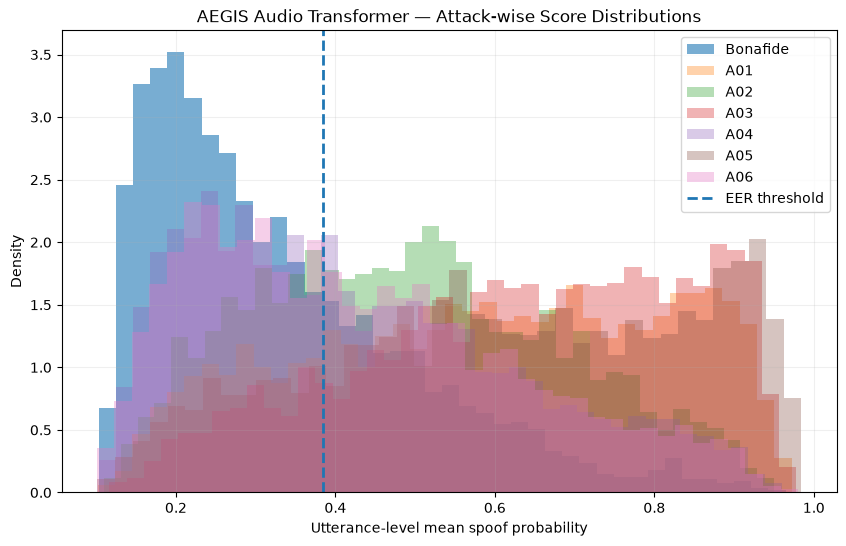

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Bona fide utterance scores
bonafide_scores = utterance_results.loc[
    utterance_results["label"] == 0,
    "mean_score"
].values

plt.figure(figsize=(10, 6))

plt.hist(
    bonafide_scores,
    bins=40,
    alpha=0.6,
    density=True,
    label="Bonafide"
)

# Plot each spoof attack
for attack_id in ["A01", "A02", "A03", "A04", "A05", "A06"]:

    scores = attack_utterance.loc[
        attack_utterance["attack_id"] == attack_id,
        "mean_score"
    ].values

    plt.hist(
        scores,
        bins=40,
        alpha=0.35,
        density=True,
        label=attack_id
    )

plt.axvline(
    0.38403029499999997,
    linestyle="--",
    linewidth=2,
    label="EER threshold"
)

plt.xlabel("Utterance-level mean spoof probability")
plt.ylabel("Density")
plt.title("AEGIS Audio Transformer — Attack-wise Score Distributions")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [22]:
# Official ASVspoof 2019 LA attack descriptions
attack_info = {
    "A01": {
        "type": "TTS",
        "conversion": "AR RNN",
        "waveform_generation": "WaveNet"
    },
    "A02": {
        "type": "TTS",
        "conversion": "AR RNN",
        "waveform_generation": "WORLD"
    },
    "A03": {
        "type": "TTS",
        "conversion": "Feed-forward NN",
        "waveform_generation": "WORLD"
    },
    "A04": {
        "type": "TTS",
        "conversion": "CART",
        "waveform_generation": "Waveform concatenation"
    },
    "A05": {
        "type": "VC",
        "conversion": "VAE",
        "waveform_generation": "WORLD"
    },
    "A06": {
        "type": "VC",
        "conversion": "GMM-UBM",
        "waveform_generation": "Spectral filtering + OLA"
    }
}

attack_analysis = attack_results.copy()

attack_analysis["type"] = attack_analysis["attack_id"].map(
    lambda x: attack_info[x]["type"]
)

attack_analysis["conversion"] = attack_analysis["attack_id"].map(
    lambda x: attack_info[x]["conversion"]
)

attack_analysis["waveform_generation"] = attack_analysis["attack_id"].map(
    lambda x: attack_info[x]["waveform_generation"]
)

attack_analysis = attack_analysis[
    [
        "attack_id",
        "type",
        "conversion",
        "waveform_generation",
        "samples",
        "mean_score",
        "median_score",
        "spoof_recall",
        "spoof_f1",
        "miss_rate"
    ]
]

print(
    attack_analysis.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

attack_id type      conversion      waveform_generation  samples  mean_score  median_score  spoof_recall  spoof_f1  miss_rate
      A01  TTS          AR RNN                  WaveNet     3716      0.5850        0.5967        0.7774    0.8748     0.2226
      A02  TTS          AR RNN                    WORLD     3716      0.4903        0.4828        0.6722    0.8040     0.3278
      A03  TTS Feed-forward NN                    WORLD     3716      0.6352        0.6546        0.8550    0.9218     0.1450
      A04  TTS            CART   Waveform concatenation     3716      0.4246        0.3887        0.5097    0.6752     0.4903
      A05   VC             VAE                    WORLD     3716      0.6143        0.6230        0.8089    0.8944     0.1911
      A06   VC         GMM-UBM Spectral filtering + OLA     3716      0.4272        0.3949        0.5196    0.6839     0.4804


In [23]:
attack_analysis_path = (
    r"D:\Projects\AEGIS\data\audio_dev\processed"
    r"\transformer_attack_analysis.csv"
)

attack_analysis.to_csv(
    attack_analysis_path,
    index=False
)

print("Saved:", attack_analysis_path)
print("Shape:", attack_analysis.shape)
print("\nSaved columns:")
print(attack_analysis.columns.tolist())

Saved: D:\Projects\AEGIS\data\audio_dev\processed\transformer_attack_analysis.csv
Shape: (6, 10)

Saved columns:
['attack_id', 'type', 'conversion', 'waveform_generation', 'samples', 'mean_score', 'median_score', 'spoof_recall', 'spoof_f1', 'miss_rate']


In [24]:
from pathlib import Path

asvspoof_root = Path(
    r"D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019"
)

print("ASVspoof root:")
print(asvspoof_root)

print("\nTop-level contents:")
for item in sorted(asvspoof_root.iterdir()):
    print(item.name)

ASVspoof root:
D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019

Top-level contents:
LA
LA.zip


In [25]:
from pathlib import Path

la_root = Path(
    r"D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA"
)

print("LA contents:")
for item in sorted(la_root.iterdir()):
    if item.is_dir():
        print(f"[DIR]  {item.name}")
    else:
        print(f"[FILE] {item.name}")

LA contents:
[DIR]  ASVspoof2019_LA_asv_protocols
[DIR]  ASVspoof2019_LA_asv_scores
[DIR]  ASVspoof2019_LA_cm_protocols
[DIR]  ASVspoof2019_LA_dev
[DIR]  ASVspoof2019_LA_eval
[DIR]  ASVspoof2019_LA_train
[FILE] README.LA.txt


In [26]:
from pathlib import Path

cm_protocol_root = Path(
    r"D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA"
    r"\\ASVspoof2019_LA_cm_protocols"
)

print("CM protocol files:")
for item in sorted(cm_protocol_root.iterdir()):
    if item.is_file():
        print(f"{item.name}  |  {item.stat().st_size:,} bytes")

CM protocol files:
ASVspoof2019.LA.cm.dev.trl.txt  |  822,400 bytes
ASVspoof2019.LA.cm.eval.trl.txt  |  2,358,176 bytes
ASVspoof2019.LA.cm.train.trn.txt  |  840,120 bytes


In [27]:
from pathlib import Path

eval_protocol = Path(
    r"D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA"
    r"\\ASVspoof2019_LA_cm_protocols"
    r"\\ASVspoof2019.LA.cm.eval.trl.txt"
)

print("First 10 lines of EVAL protocol:\n")

with open(eval_protocol, "r", encoding="utf-8") as f:
    for i in range(10):
        line = f.readline()
        if not line:
            break
        print(line.rstrip())

First 10 lines of EVAL protocol:

LA_0039 LA_E_2834763 - A11 spoof
LA_0014 LA_E_8877452 - A14 spoof
LA_0040 LA_E_6828287 - A16 spoof
LA_0022 LA_E_6977360 - A09 spoof
LA_0031 LA_E_5932896 - A13 spoof
LA_0030 LA_E_5849185 - - bonafide
LA_0001 LA_E_6163791 - A09 spoof
LA_0033 LA_E_4581379 - - bonafide
LA_0002 LA_E_8814547 - A12 spoof
LA_0048 LA_E_9157999 - A18 spoof


In [28]:
import pandas as pd
from pathlib import Path

eval_protocol = Path(
    r"D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA"
    r"\\ASVspoof2019_LA_cm_protocols"
    r"\\ASVspoof2019.LA.cm.eval.trl.txt"
)

eval_df = pd.read_csv(
    eval_protocol,
    sep=r"\s+",
    header=None,
    names=[
        "speaker_id",
        "sample_id",
        "unused",
        "attack_id",
        "label"
    ]
)

print("Shape:", eval_df.shape)

print("\nLabel distribution:")
print(eval_df["label"].value_counts())

print("\nAttack distribution:")
print(eval_df["attack_id"].value_counts().sort_index())

print("\nUnique speakers:", eval_df["speaker_id"].nunique())
print("Unique samples:", eval_df["sample_id"].nunique())

print("\nMissing values:")
print(eval_df.isna().sum())

Shape: (71237, 5)

Label distribution:
label
spoof       63882
bonafide     7355
Name: count, dtype: int64

Attack distribution:
attack_id
-      7355
A07    4914
A08    4914
A09    4914
A10    4914
A11    4914
A12    4914
A13    4914
A14    4914
A15    4914
A16    4914
A17    4914
A18    4914
A19    4914
Name: count, dtype: int64

Unique speakers: 67
Unique samples: 71237

Missing values:
speaker_id    0
sample_id     0
unused        0
attack_id     0
label         0
dtype: int64


In [29]:
from pathlib import Path

eval_audio_root = Path(
    r"D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA"
    r"\\ASVspoof2019_LA_eval"
)

print("EVAL directory:", eval_audio_root)

# Find all FLAC files once
eval_flac_files = list(eval_audio_root.rglob("*.flac"))

print("FLAC files found:", len(eval_flac_files))

# Map filename stem -> path
eval_file_map = {
    path.stem: str(path)
    for path in eval_flac_files
}

# Check protocol samples
eval_df["file_path"] = eval_df["sample_id"].map(eval_file_map)

missing = eval_df["file_path"].isna()

print("Protocol rows:", len(eval_df))
print("Files matched:", (~missing).sum())
print("Files missing:", missing.sum())

if missing.sum() > 0:
    print("\nFirst missing samples:")
    print(eval_df.loc[missing, "sample_id"].head(20).to_string(index=False))
else:
    print("\nPASS: Every EVAL protocol sample has a matching FLAC file.")

EVAL directory: D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA\ASVspoof2019_LA_eval
FLAC files found: 71933
Protocol rows: 71237
Files matched: 71237
Files missing: 0

PASS: Every EVAL protocol sample has a matching FLAC file.


In [30]:
eval_metadata = eval_df[
    [
        "sample_id",
        "speaker_id",
        "attack_id",
        "label",
        "file_path"
    ]
].copy()

eval_metadata["split"] = "eval"

eval_metadata_path = (
    Path(r"D:\Projects\AEGIS\data\audio_dev\processed")
    / "asvspoof2019_la_eval_metadata.csv"
)

eval_metadata.to_csv(
    eval_metadata_path,
    index=False
)

print("Saved:", eval_metadata_path)
print("Shape:", eval_metadata.shape)

print("\nLabels:")
print(eval_metadata["label"].value_counts())

print("\nAttacks:")
print(eval_metadata["attack_id"].value_counts().sort_index())

print("\nMissing values:")
print(eval_metadata.isna().sum())

Saved: D:\Projects\AEGIS\data\audio_dev\processed\asvspoof2019_la_eval_metadata.csv
Shape: (71237, 6)

Labels:
label
spoof       63882
bonafide     7355
Name: count, dtype: int64

Attacks:
attack_id
-      7355
A07    4914
A08    4914
A09    4914
A10    4914
A11    4914
A12    4914
A13    4914
A14    4914
A15    4914
A16    4914
A17    4914
A18    4914
A19    4914
Name: count, dtype: int64

Missing values:
sample_id     0
speaker_id    0
attack_id     0
label         0
file_path     0
split         0
dtype: int64


In [31]:
# Reuse the same duration/windowing logic used for TRAIN/DEV.

import soundfile as sf
import numpy as np

WINDOW_SEC = 2.56
HOP_SEC = 1.28

def count_windows(duration_sec, window_sec=WINDOW_SEC, hop_sec=HOP_SEC):
    if duration_sec <= window_sec:
        return 1
    return int(np.ceil((duration_sec - window_sec) / hop_sec)) + 1


eval_durations = []

for path in eval_metadata["file_path"]:
    info = sf.info(path)
    eval_durations.append(info.duration)

eval_metadata["duration_sec"] = eval_durations
eval_metadata["num_windows"] = eval_metadata["duration_sec"].apply(
    count_windows
)

print("EVAL utterances:", len(eval_metadata))

print("\nDuration statistics:")
print(
    eval_metadata["duration_sec"].describe()
)

print("\nWindow statistics:")
print(
    eval_metadata["num_windows"].describe()
)

print("\nTotal EVAL windows:", eval_metadata["num_windows"].sum())

print("\nWindow count distribution:")
print(
    eval_metadata["num_windows"].value_counts().sort_index().to_string()
)

EVAL utterances: 71237

Duration statistics:
count    71237.000000
mean         3.107693
std          1.480771
min          0.469938
25%          2.053000
50%          2.817750
75%          3.832000
max         13.025562
Name: duration_sec, dtype: float64

Window statistics:
count    71237.000000
mean         1.978873
std          1.125007
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max         10.000000
Name: num_windows, dtype: float64

Total EVAL windows: 140969

Window count distribution:
num_windows
1     29749
2     23951
3     10709
4      4122
5      1802
6       692
7       167
8        35
9         8
10        2


In [34]:
import time
import torch
import numpy as np

# Use the already-loaded Transformer model and cached preprocessing functions.
# We will NOT modify the trained model.

model.eval()

# Take the first 100 EVAL windows across the utterances.
benchmark_rows = []

for _, row in eval_metadata.head(50).iterrows():
    num_windows = int(row["num_windows"])

    for i in range(num_windows):
        start_sec = i * HOP_SEC

        benchmark_rows.append({
            "sample_id": row["sample_id"],
            "file_path": row["file_path"],
            "start_sec": start_sec,
            "label": row["label"],
            "attack_id": row["attack_id"]
        })

        if len(benchmark_rows) >= 100:
            break

    if len(benchmark_rows) >= 100:
        break

print("Benchmark windows:", len(benchmark_rows))

# Feature extraction
features = []

start_time = time.time()

for row in benchmark_rows:
    waveform, sr = preprocess_audio(
        row["file_path"],
        start_sec=row["start_sec"],
        window_seconds=WINDOW_SEC,
        target_sr=16000
    )

    feat = extract_audio_features(
        waveform,
        sr=sr
    )

    features.append(feat)

feature_time = time.time() - start_time

# Batch inference
X = torch.from_numpy(
    np.stack(features)
).float()

start_time = time.time()

with torch.no_grad():
    logits = model(X)
    probabilities = torch.softmax(logits, dim=1)[:, 1]

inference_time = time.time() - start_time

total_time = feature_time + inference_time

print("\n===== EVAL BENCHMARK =====")
print(f"Feature extraction: {feature_time:.2f} sec")
print(f"Model inference:    {inference_time:.2f} sec")
print(f"Total:              {total_time:.2f} sec")

print("\nThroughput:")
print(f"Feature extraction: {len(features)/feature_time:.2f} windows/sec")
print(f"Inference:          {len(features)/inference_time:.2f} windows/sec")
print(f"Overall:            {len(features)/total_time:.2f} windows/sec")

print("\nOutput:")
print("Input shape:", X.shape)
print("Probability shape:", probabilities.shape)
print("Probability range:",
      probabilities.min().item(),
      "to",
      probabilities.max().item())

print("All finite:",
      torch.isfinite(probabilities).all().item())

NameError: name 'model' is not defined

In [35]:
import torch
import torch.nn as nn
from pathlib import Path

# ---------------------------------------------------------
# 1. Recreate the exact Transformer architecture
# ---------------------------------------------------------

class AEGISAudioTransformer(nn.Module):
    def __init__(
        self,
        in_channels=2,
        embed_dim=128,
        patch_size=(16, 16),
        num_heads=4,
        num_layers=4,
        num_classes=2,
        dropout=0.1
    ):
        super().__init__()

        self.patch_embed = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        freq_patches = 128 // patch_size[0]
        time_patches = 257 // patch_size[1]
        num_patches = freq_patches * time_patches

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(embed_dim)

        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, x):
        x = self.patch_embed(x)

        # B, C, F, T → B, N, C
        x = x.flatten(2).transpose(1, 2)

        batch_size = x.size(0)

        cls_tokens = self.cls_token.expand(
            batch_size, -1, -1
        )

        x = torch.cat(
            [cls_tokens, x],
            dim=1
        )

        x = x + self.pos_embedding[:, :x.size(1)]

        x = self.transformer(x)

        x = self.norm(x[:, 0])

        return self.classifier(x)


# ---------------------------------------------------------
# 2. Load the saved checkpoint
# ---------------------------------------------------------

checkpoint_path = Path(
    r"D:\Projects\AEGIS\models\audio_transformer\best_audio_transformer.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu"
)

model_config = checkpoint["model_config"]

model = AEGISAudioTransformer(
    **model_config
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()


# ---------------------------------------------------------
# 3. Verify checkpoint
# ---------------------------------------------------------

parameter_count = sum(
    p.numel() for p in model.parameters()
)

print("Checkpoint loaded successfully.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation loss:", checkpoint["val_loss"])
print("Validation balanced accuracy:",
      checkpoint["val_balanced_accuracy"])
print("Validation spoof recall:",
      checkpoint["val_spoof_recall"])
print("Validation spoof F1:",
      checkpoint["val_spoof_f1"])

print("\nModel configuration:")
print(model_config)

print("\nParameter count:", parameter_count)
print("Device: CPU")

Checkpoint loaded successfully.
Checkpoint epoch: 1
Validation loss: 0.7116964936633721
Validation balanced accuracy: 0.636548595458263
Validation spoof recall: 0.5594656305079314
Validation spoof F1: 0.7028319096204411

Model configuration:
{'in_channels': 2, 'embed_dim': 128, 'patch_size': (16, 16), 'num_heads': 4, 'num_layers': 4, 'num_classes': 2}

Parameter count: 875906
Device: CPU


C:\Users\Harshvardhan Singh\AppData\Local\Temp\ipykernel_17152\756448979.py:51: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [39]:
import time
import torch
import numpy as np

model.eval()

benchmark_rows = []

for _, row in eval_metadata.head(50).iterrows():
    num_windows = int(row["num_windows"])

    for i in range(num_windows):
        start_sec = i * HOP_SEC

        benchmark_rows.append({
            "sample_id": row["sample_id"],
            "file_path": row["file_path"],
            "start_sec": start_sec,
            "label": row["label"],
            "attack_id": row["attack_id"]
        })

        if len(benchmark_rows) >= 100:
            break

    if len(benchmark_rows) >= 100:
        break

print("Benchmark windows:", len(benchmark_rows))

features = []

start_time = time.time()

for row in benchmark_rows:
    waveform, sr = preprocess_audio(
        row["file_path"],
        start_sec=row["start_sec"],
        window_seconds=WINDOW_SEC,
        target_sr=16000
    )

    feat = extract_audio_features(
        waveform,
        sr=sr
    )

    features.append(feat)

feature_time = time.time() - start_time

X = torch.from_numpy(
    np.stack(features)
).float()

start_time = time.time()

with torch.no_grad():
    logits = model(X)
    probabilities = torch.softmax(logits, dim=1)[:, 1]

inference_time = time.time() - start_time

total_time = feature_time + inference_time

print("\n===== EVAL BENCHMARK =====")
print(f"Feature extraction: {feature_time:.2f} sec")
print(f"Model inference:    {inference_time:.2f} sec")
print(f"Total:              {total_time:.2f} sec")

print("\nThroughput:")
print(f"Feature extraction: {len(features)/feature_time:.2f} windows/sec")
print(f"Inference:          {len(features)/inference_time:.2f} windows/sec")
print(f"Overall:            {len(features)/total_time:.2f} windows/sec")

print("\nOutput:")
print("Input shape:", X.shape)
print("Probability shape:", probabilities.shape)
print(
    "Probability range:",
    probabilities.min().item(),
    "to",
    probabilities.max().item()
)

print(
    "All finite:",
    torch.isfinite(probabilities).all().item()
)


Benchmark windows: 93

===== EVAL BENCHMARK =====
Feature extraction: 5.57 sec
Model inference:    0.58 sec
Total:              6.15 sec

Throughput:
Feature extraction: 16.68 windows/sec
Inference:          160.40 windows/sec
Overall:            15.11 windows/sec

Output:
Input shape: torch.Size([93, 2, 128, 257])
Probability shape: torch.Size([93])
Probability range: 0.13884197175502777 to 0.9397490620613098
All finite: True


In [37]:
import numpy as np
import librosa
from scipy.signal import resample


def extract_audio_features(
    waveform,
    sr=16000,
    n_fft=1024,
    hop_length=160,
    n_mels=128,
    fmin=20,
    fmax=8000,
    cqt_fmin=65.4,
    cqt_bins=128,
    cqt_bins_per_octave=24,
    target_time_frames=257
):
    # Log-Mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=waveform,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        fmin=fmin,
        fmax=fmax
    )

    log_mel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    # CQT
    cqt = librosa.cqt(
        waveform,
        sr=sr,
        hop_length=hop_length,
        fmin=cqt_fmin,
        n_bins=cqt_bins,
        bins_per_octave=cqt_bins_per_octave
    )

    cqt_magnitude = np.abs(cqt)

    # Align CQT temporal dimension with Mel
    cqt_aligned = resample(
        cqt_magnitude,
        target_time_frames,
        axis=1
    )

    cqt_aligned = librosa.amplitude_to_db(
        np.maximum(cqt_aligned, 1e-10),
        ref=np.max
    )

    # Two-channel representation:
    # channel 0 = Log-Mel
    # channel 1 = CQT
    audio_features = np.stack(
        [log_mel, cqt_aligned],
        axis=0
    ).astype(np.float32)

    # Safety check
    if not np.isfinite(audio_features).all():
        raise ValueError("Non-finite values detected in audio features.")

    return audio_features


print("extract_audio_features restored successfully.")

extract_audio_features restored successfully.


In [38]:
print("preprocess_audio available:", callable(preprocess_audio))
print("extract_audio_features available:", callable(extract_audio_features))
print("model available:", callable(getattr(model, "forward", None)))
print("WINDOW_SEC:", WINDOW_SEC)
print("HOP_SEC:", HOP_SEC)

preprocess_audio available: True
extract_audio_features available: True
model available: True
WINDOW_SEC: 2.56
HOP_SEC: 1.28


In [40]:
import time
import numpy as np
import pandas as pd
import torch

model.eval()

# ---------------------------------------------------------
# 1. Select only 20 EVAL utterances
# ---------------------------------------------------------

test_metadata = eval_metadata.head(20).copy()

print("Test utterances:", len(test_metadata))


# ---------------------------------------------------------
# 2. Process each utterance window-by-window
# ---------------------------------------------------------

results = []

start_total = time.time()

for _, row in test_metadata.iterrows():

    window_scores = []

    num_windows = int(row["num_windows"])

    for window_idx in range(num_windows):

        start_sec = window_idx * HOP_SEC

        waveform, sr = preprocess_audio(
            row["file_path"],
            start_sec=start_sec,
            window_seconds=WINDOW_SEC,
            target_sr=16000
        )

        features = extract_audio_features(
            waveform,
            sr=sr
        )

        X = torch.from_numpy(
            features
        ).unsqueeze(0).float()

        with torch.no_grad():
            logits = model(X)
            spoof_probability = torch.softmax(
                logits,
                dim=1
            )[0, 1].item()

        window_scores.append(spoof_probability)

    # -----------------------------------------------------
    # Utterance-level aggregation
    # -----------------------------------------------------

    mean_score = float(np.mean(window_scores))
    max_score = float(np.max(window_scores))

    results.append({
        "sample_id": row["sample_id"],
        "speaker_id": row["speaker_id"],
        "attack_id": row["attack_id"],
        "label": row["label"],
        "duration_sec": row["duration_sec"],
        "num_windows": num_windows,
        "mean_score": mean_score,
        "max_score": max_score
    })


elapsed = time.time() - start_total

test_results = pd.DataFrame(results)


# ---------------------------------------------------------
# 3. Validate output
# ---------------------------------------------------------

print("\n===== 20-UTTERANCE EVAL TEST =====")

print("Elapsed time:", round(elapsed, 2), "seconds")
print("Output shape:", test_results.shape)

print("\nColumns:")
print(test_results.columns.tolist())

print("\nResults:")
print(test_results.to_string(index=False))

print("\nChecks:")

print(
    "Unique sample IDs:",
    test_results["sample_id"].nunique()
)

print(
    "Missing values:",
    test_results.isna().sum().sum()
)

print(
    "Mean scores finite:",
    np.isfinite(test_results["mean_score"]).all()
)

print(
    "Max scores finite:",
    np.isfinite(test_results["max_score"]).all()
)

print(
    "Mean score range:",
    test_results["mean_score"].min(),
    "to",
    test_results["mean_score"].max()
)

print(
    "Max score range:",
    test_results["max_score"].min(),
    "to",
    test_results["max_score"].max()
)

Test utterances: 20

===== 20-UTTERANCE EVAL TEST =====
Elapsed time: 7.41 seconds
Output shape: (20, 8)

Columns:
['sample_id', 'speaker_id', 'attack_id', 'label', 'duration_sec', 'num_windows', 'mean_score', 'max_score']

Results:
   sample_id speaker_id attack_id    label  duration_sec  num_windows  mean_score  max_score
LA_E_2834763    LA_0039       A11    spoof      1.426937            1    0.438054   0.438054
LA_E_8877452    LA_0014       A14    spoof      3.976437            3    0.316109   0.367493
LA_E_6828287    LA_0040       A16    spoof      1.559875            1    0.916710   0.916710
LA_E_6977360    LA_0022       A09    spoof      1.962000            1    0.404435   0.404435
LA_E_5932896    LA_0031       A13    spoof      5.801250            4    0.910428   0.930501
LA_E_5849185    LA_0030         - bonafide      4.392750            3    0.647828   0.851557
LA_E_6163791    LA_0001       A09    spoof      1.899312            1    0.575337   0.575337
LA_E_4581379    LA_0033

In [1]:
from pathlib import Path

eval_results_dir = Path(
    r"D:\Projects\AEGIS\results\audio_transformer_eval"
)

eval_results_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Output directory ready:")
print(eval_results_dir)

print("\nExisting files:")
for item in sorted(eval_results_dir.iterdir()):
    print(item.name)

Output directory ready:
D:\Projects\AEGIS\results\audio_transformer_eval

Existing files:


In [2]:
from pathlib import Path

script_path = Path(
    r"D:\Projects\AEGIS\src\audio_eval_inference.py"
)

script_code = r'''
from pathlib import Path
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import librosa
from scipy.signal import resample


# =========================================================
# Configuration
# =========================================================

PROJECT_ROOT = Path(r"D:\Projects\AEGIS")

METADATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "audio_dev"
    / "processed"
    / "asvspoof2019_la_eval_metadata.csv"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "models"
    / "audio_transformer"
    / "best_audio_transformer.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "audio_transformer_eval"
)

OUTPUT_PATH = OUTPUT_DIR / "eval_utterance_predictions.csv"

WINDOW_SEC = 2.56
HOP_SEC = 1.28
TARGET_SR = 16000

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# =========================================================
# Audio preprocessing
# =========================================================

def preprocess_audio(
    audio_path,
    start_sec=0.0,
    window_seconds=2.56,
    target_sr=16000
):
    waveform, sample_rate = librosa.load(
        audio_path,
        sr=target_sr,
        mono=True,
        offset=float(start_sec),
        duration=float(window_seconds)
    )

    target_samples = int(target_sr * window_seconds)

    if len(waveform) < target_samples:
        waveform = np.pad(
            waveform,
            (0, target_samples - len(waveform)),
            mode="constant"
        )
    elif len(waveform) > target_samples:
        waveform = waveform[:target_samples]

    waveform = waveform.astype(np.float32)

    if not np.isfinite(waveform).all():
        raise ValueError(
            f"Non-finite audio values detected: {audio_path}"
        )

    return waveform, sample_rate


def extract_audio_features(
    waveform,
    sr=16000,
    n_fft=1024,
    hop_length=160,
    n_mels=128,
    fmin=20,
    fmax=8000,
    cqt_fmin=65.4,
    cqt_bins=128,
    cqt_bins_per_octave=24,
    target_time_frames=257
):
    mel = librosa.feature.melspectrogram(
        y=waveform,
        sr=sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        fmin=fmin,
        fmax=fmax
    )

    log_mel = librosa.power_to_db(
        mel,
        ref=np.max
    )

    cqt = librosa.cqt(
        waveform,
        sr=sr,
        hop_length=hop_length,
        fmin=cqt_fmin,
        n_bins=cqt_bins,
        bins_per_octave=cqt_bins_per_octave
    )

    cqt_magnitude = np.abs(cqt)

    cqt_aligned = resample(
        cqt_magnitude,
        target_time_frames,
        axis=1
    )

    cqt_aligned = librosa.amplitude_to_db(
        np.maximum(cqt_aligned, 1e-10),
        ref=np.max
    )

    audio_features = np.stack(
        [log_mel, cqt_aligned],
        axis=0
    ).astype(np.float32)

    if not np.isfinite(audio_features).all():
        raise ValueError(
            "Non-finite values detected in audio features."
        )

    return audio_features


# =========================================================
# Exact Transformer architecture
# =========================================================

class AEGISAudioTransformer(nn.Module):

    def __init__(
        self,
        in_channels=2,
        embed_dim=128,
        patch_size=(16, 16),
        num_heads=4,
        num_layers=4,
        num_classes=2,
        dropout=0.1
    ):
        super().__init__()

        self.patch_embed = nn.Conv2d(
            in_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        freq_patches = 128 // patch_size[0]
        time_patches = 257 // patch_size[1]

        num_patches = (
            freq_patches * time_patches
        )

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        self.pos_embedding = nn.Parameter(
            torch.zeros(
                1,
                num_patches + 1,
                embed_dim
            )
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(embed_dim)

        self.classifier = nn.Linear(
            embed_dim,
            num_classes
        )

    def forward(self, x):

        x = self.patch_embed(x)

        x = x.flatten(2).transpose(1, 2)

        batch_size = x.size(0)

        cls_tokens = self.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        x = torch.cat(
            [cls_tokens, x],
            dim=1
        )

        x = x + self.pos_embedding[:, :x.size(1)]

        x = self.transformer(x)

        x = self.norm(x[:, 0])

        return self.classifier(x)


# =========================================================
# Load model
# =========================================================

print("Loading metadata...")

eval_metadata = pd.read_csv(
    METADATA_PATH
)

print(
    f"EVAL utterances: {len(eval_metadata):,}"
)

print("Loading checkpoint...")

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu"
)

model_config = checkpoint["model_config"]

model = AEGISAudioTransformer(
    **model_config
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print(
    "Checkpoint epoch:",
    checkpoint["epoch"]
)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)


# =========================================================
# Resume support
# =========================================================

if OUTPUT_PATH.exists():

    existing = pd.read_csv(
        OUTPUT_PATH
    )

    completed_ids = set(
        existing["sample_id"]
    )

    print(
        f"Existing completed utterances: "
        f"{len(completed_ids):,}"
    )

else:

    existing = pd.DataFrame()

    completed_ids = set()

    print(
        "No previous results found. "
        "Starting from zero."
    )


# =========================================================
# Inference
# =========================================================

new_results = []

start_total = time.time()

for index, row in eval_metadata.iterrows():

    sample_id = row["sample_id"]

    if sample_id in completed_ids:
        continue

    window_scores = []

    num_windows = int(row["num_windows"])

    try:

        for window_idx in range(num_windows):

            start_sec = (
                window_idx * HOP_SEC
            )

            waveform, sr = preprocess_audio(
                row["file_path"],
                start_sec=start_sec,
                window_seconds=WINDOW_SEC,
                target_sr=TARGET_SR
            )

            features = extract_audio_features(
                waveform,
                sr=sr
            )

            X = torch.from_numpy(
                features
            ).unsqueeze(0).float()

            with torch.no_grad():

                logits = model(X)

                spoof_probability = (
                    torch.softmax(
                        logits,
                        dim=1
                    )[0, 1].item()
                )

            if not np.isfinite(
                spoof_probability
            ):
                raise ValueError(
                    "Non-finite model output."
                )

            window_scores.append(
                spoof_probability
            )

        mean_score = float(
            np.mean(window_scores)
        )

        max_score = float(
            np.max(window_scores)
        )

        new_results.append({

            "sample_id": sample_id,

            "speaker_id": row["speaker_id"],

            "attack_id": row["attack_id"],

            "label": row["label"],

            "duration_sec": row["duration_sec"],

            "num_windows": num_windows,

            "mean_score": mean_score,

            "max_score": max_score
        })

    except Exception as exc:

        print(
            f"\nERROR: {sample_id}: {exc}"
        )

    # Save every 100 newly processed utterances
    if len(new_results) >= 100:

        chunk = pd.DataFrame(
            new_results
        )

        if OUTPUT_PATH.exists():

            chunk.to_csv(
                OUTPUT_PATH,
                mode="a",
                header=False,
                index=False
            )

        else:

            chunk.to_csv(
                OUTPUT_PATH,
                index=False
            )

        completed_ids.update(
            chunk["sample_id"]
        )

        new_results = []

        elapsed = (
            time.time()
            - start_total
        )

        print(
            f"Completed: "
            f"{len(completed_ids):,}/"
            f"{len(eval_metadata):,} "
            f"| elapsed: "
            f"{elapsed / 60:.1f} min"
        )


# Save remaining results

if new_results:

    chunk = pd.DataFrame(
        new_results
    )

    if OUTPUT_PATH.exists():

        chunk.to_csv(
            OUTPUT_PATH,
            mode="a",
            header=False,
            index=False
        )

    else:

        chunk.to_csv(
            OUTPUT_PATH,
            index=False
        )


elapsed_total = (
    time.time()
    - start_total
)

print("\n================================")
print("EVAL INFERENCE COMPLETE")
print("================================")

print(
    f"Elapsed: "
    f"{elapsed_total / 3600:.2f} hours"
)

print(
    f"Results saved to:\n{OUTPUT_PATH}"
)
'''

script_path.write_text(
    script_code,
    encoding="utf-8"
)

print("Script created successfully:")
print(script_path)

print("\nSize:")
print(f"{script_path.stat().st_size:,} bytes")

Script created successfully:
D:\Projects\AEGIS\src\audio_eval_inference.py

Size:
10,274 bytes


In [3]:
from pathlib import Path

script_path = Path(
    r"D:\Projects\AEGIS\src\audio_eval_inference.py"
)

script_text = script_path.read_text(
    encoding="utf-8"
)

checks = {
    "Metadata path": "asvspoof2019_la_eval_metadata.csv" in script_text,
    "Checkpoint path": "best_audio_transformer.pt" in script_text,
    "Window size": "WINDOW_SEC = 2.56" in script_text,
    "Hop size": "HOP_SEC = 1.28" in script_text,
    "Resume support": "completed_ids" in script_text,
    "Incremental saving": "len(new_results) >= 100" in script_text,
    "Mean aggregation": "np.mean(window_scores)" in script_text,
    "Max aggregation": "np.max(window_scores)" in script_text,
    "CPU checkpoint loading": 'map_location="cpu"' in script_text,
}

print("===== SCRIPT VALIDATION =====")

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nTotal checks:", len(checks))
print("Passed:", sum(checks.values()))
print("Failed:", len(checks) - sum(checks.values()))

===== SCRIPT VALIDATION =====
Metadata path: PASS
Checkpoint path: PASS
Window size: PASS
Hop size: PASS
Resume support: PASS
Incremental saving: PASS
Mean aggregation: PASS
Max aggregation: PASS
CPU checkpoint loading: PASS

Total checks: 9
Passed: 9
Failed: 0


In [4]:
from pathlib import Path
import shutil

source_script = Path(
    r"D:\Projects\AEGIS\src\audio_eval_inference.py"
)

dry_run_script = Path(
    r"D:\Projects\AEGIS\src\audio_eval_inference_dryrun.py"
)

shutil.copy2(
    source_script,
    dry_run_script
)

print("Dry-run copy created:")
print(dry_run_script)
print("\nOriginal production script unchanged:")
print(source_script)

Dry-run copy created:
D:\Projects\AEGIS\src\audio_eval_inference_dryrun.py

Original production script unchanged:
D:\Projects\AEGIS\src\audio_eval_inference.py


In [5]:
from pathlib import Path

dry_run_script = Path(
    r"D:\Projects\AEGIS\src\audio_eval_inference_dryrun.py"
)

text = dry_run_script.read_text(
    encoding="utf-8"
)

# Limit metadata to first 100 utterances
text = text.replace(
    'eval_metadata = pd.read_csv(\n    METADATA_PATH\n)',
    'eval_metadata = pd.read_csv(\n    METADATA_PATH\n).head(100)'
)

# Use a separate output file
text = text.replace(
    'OUTPUT_PATH = OUTPUT_DIR / "eval_utterance_predictions.csv"',
    'OUTPUT_PATH = OUTPUT_DIR / "eval_utterance_predictions_dryrun.csv"'
)

dry_run_script.write_text(
    text,
    encoding="utf-8"
)

print("Dry-run script updated successfully:")
print(dry_run_script)

print("\nProduction script remains untouched:")
print(
    Path(
        r"D:\Projects\AEGIS\src\audio_eval_inference.py"
    )
)

Dry-run script updated successfully:
D:\Projects\AEGIS\src\audio_eval_inference_dryrun.py

Production script remains untouched:
D:\Projects\AEGIS\src\audio_eval_inference.py


In [6]:
# Recalculate the exact window count used throughout AEGIS
# and save it into the EVAL metadata.

eval_metadata["num_windows"] = eval_metadata["duration_sec"].apply(
    count_windows
)

eval_metadata_path = Path(
    r"D:\Projects\AEGIS\data\audio_dev\processed"
    r"\asvspoof2019_la_eval_metadata.csv"
)

eval_metadata.to_csv(
    eval_metadata_path,
    index=False
)

print("EVAL metadata updated:")
print(eval_metadata_path)

print("\nShape:", eval_metadata.shape)

print("\nColumns:")
print(eval_metadata.columns.tolist())

print("\nTotal EVAL windows:")
print(eval_metadata["num_windows"].sum())

print("\nWindow statistics:")
print(eval_metadata["num_windows"].describe())

print("\nMissing values:")
print(eval_metadata.isna().sum())

NameError: name 'eval_metadata' is not defined

In [7]:
from pathlib import Path
import pandas as pd
import numpy as np

eval_metadata_path = Path(
    r"D:\Projects\AEGIS\data\audio_dev\processed"
    r"\asvspoof2019_la_eval_metadata.csv"
)

eval_metadata = pd.read_csv(eval_metadata_path)

print("Loaded EVAL metadata:")
print("Shape:", eval_metadata.shape)

print("\nColumns:")
print(eval_metadata.columns.tolist())

print("\nFirst 3 rows:")
print(eval_metadata.head(3).to_string(index=False))

Loaded EVAL metadata:
Shape: (71237, 6)

Columns:
['sample_id', 'speaker_id', 'attack_id', 'label', 'file_path', 'split']

First 3 rows:
   sample_id speaker_id attack_id label                                                                                        file_path split
LA_E_2834763    LA_0039       A11 spoof D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA\ASVspoof2019_LA_eval\flac\LA_E_2834763.flac  eval
LA_E_8877452    LA_0014       A14 spoof D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA\ASVspoof2019_LA_eval\flac\LA_E_8877452.flac  eval
LA_E_6828287    LA_0040       A16 spoof D:\Projects\AEGIS\data\audio_dev\raw\asvspoof2019\LA\ASVspoof2019_LA_eval\flac\LA_E_6828287.flac  eval


In [8]:
import soundfile as sf
import numpy as np

WINDOW_SEC = 2.56
HOP_SEC = 1.28


def count_windows(
    duration_sec,
    window_sec=WINDOW_SEC,
    hop_sec=HOP_SEC
):
    if duration_sec <= window_sec:
        return 1

    return int(
        np.ceil(
            (duration_sec - window_sec) / hop_sec
        )
    ) + 1


print("Reading EVAL audio durations...")

durations = []

for path in eval_metadata["file_path"]:
    durations.append(
        sf.info(path).duration
    )

eval_metadata["duration_sec"] = durations

eval_metadata["num_windows"] = (
    eval_metadata["duration_sec"]
    .apply(count_windows)
)

# Save updated metadata
eval_metadata.to_csv(
    eval_metadata_path,
    index=False
)

print("\n===== UPDATED EVAL METADATA =====")

print("Shape:", eval_metadata.shape)

print("\nColumns:")
print(eval_metadata.columns.tolist())

print(
    "\nTotal EVAL windows:",
    eval_metadata["num_windows"].sum()
)

print("\nWindow statistics:")
print(
    eval_metadata["num_windows"].describe()
)

print("\nMissing values:")
print(
    eval_metadata[
        ["duration_sec", "num_windows"]
    ].isna().sum()
)

print("\nExpected total windows: 140969")
print(
    "PASS:",
    eval_metadata["num_windows"].sum() == 140969
)

Reading EVAL audio durations...

===== UPDATED EVAL METADATA =====
Shape: (71237, 8)

Columns:
['sample_id', 'speaker_id', 'attack_id', 'label', 'file_path', 'split', 'duration_sec', 'num_windows']

Total EVAL windows: 140969

Window statistics:
count    71237.000000
mean         1.978873
std          1.125007
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max         10.000000
Name: num_windows, dtype: float64

Missing values:
duration_sec    0
num_windows     0
dtype: int64

Expected total windows: 140969
PASS: True


In [9]:
from pathlib import Path
import pandas as pd
import numpy as np

dryrun_path = Path(
    r"D:\Projects\AEGIS\results\audio_transformer_eval"
    r"\eval_utterance_predictions_dryrun.csv"
)

dryrun_results = pd.read_csv(dryrun_path)

print("===== DRY-RUN RESULT VALIDATION =====")

print("Shape:", dryrun_results.shape)

print("\nColumns:")
print(dryrun_results.columns.tolist())

print("\nLabel distribution:")
print(dryrun_results["label"].value_counts())

print("\nAttack distribution:")
print(
    dryrun_results["attack_id"]
    .value_counts()
    .sort_index()
)

print("\nMissing values:")
print(dryrun_results.isna().sum())

print("\nUnique sample IDs:")
print(dryrun_results["sample_id"].nunique())

print("\nScore range:")
print(
    dryrun_results["mean_score"].min(),
    "to",
    dryrun_results["mean_score"].max()
)

print("\nAll mean scores finite:")
print(
    np.isfinite(
        dryrun_results["mean_score"]
    ).all()
)

print("\nAll max scores finite:")
print(
    np.isfinite(
        dryrun_results["max_score"]
    ).all()
)

print("\nFirst 5 results:")
print(
    dryrun_results.head().to_string(index=False)
)

===== DRY-RUN RESULT VALIDATION =====
Shape: (100, 8)

Columns:
['sample_id', 'speaker_id', 'attack_id', 'label', 'duration_sec', 'num_windows', 'mean_score', 'max_score']

Label distribution:
label
spoof       86
bonafide    14
Name: count, dtype: int64

Attack distribution:
attack_id
-      14
A07     6
A08     8
A09     7
A10     9
A11     4
A12     7
A13    10
A14     6
A15     5
A16     8
A17     7
A18     7
A19     2
Name: count, dtype: int64

Missing values:
sample_id       0
speaker_id      0
attack_id       0
label           0
duration_sec    0
num_windows     0
mean_score      0
max_score       0
dtype: int64

Unique sample IDs:
100

Score range:
0.1443487554788589 to 0.9397490620613098

All mean scores finite:
True

All max scores finite:
True

First 5 results:
   sample_id speaker_id attack_id label  duration_sec  num_windows  mean_score  max_score
LA_E_2834763    LA_0039       A11 spoof      1.426937            1    0.438054   0.438054
LA_E_8877452    LA_0014       A14 spo

In [10]:
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, roc_curve

eval_path = r"D:\Projects\AEGIS\results\audio_transformer_eval\eval_utterance_predictions.csv"

eval_results = pd.read_csv(eval_path)

y_true = (eval_results["label"] == "spoof").astype(int).to_numpy()
y_score = eval_results["mean_score"].to_numpy()

roc_auc = roc_auc_score(y_true, y_score)

fpr, tpr, thresholds = roc_curve(y_true, y_score)

fnr = 1 - tpr

eer_idx = np.nanargmin(np.abs(fpr - fnr))

eer = (fpr[eer_idx] + fnr[eer_idx]) / 2
eer_threshold = thresholds[eer_idx]

print("===== ASVSPOOF 2019 LA EVAL =====")
print("Utterances:", len(eval_results))
print("ROC-AUC:", roc_auc)
print("EER:", eer)
print("EER threshold:", eer_threshold)
print("Score min:", y_score.min())
print("Score max:", y_score.max())
print("Score mean:", y_score.mean())

===== ASVSPOOF 2019 LA EVAL =====
Utterances: 71237
ROC-AUC: 0.6069885266664015
EER: 0.4259473273409371
EER threshold: 0.3598121285438537
Score min: 0.1008485704660415
Score max: 0.979790985584259
Score mean: 0.4532135423474635


In [11]:
print("===== EVAL ATTACK DISTRIBUTION =====")

print(
    eval_results["attack_id"]
    .value_counts()
    .sort_index()
)

print("\nLabel distribution:")
print(
    eval_results["label"].value_counts()
)

===== EVAL ATTACK DISTRIBUTION =====
attack_id
-      7355
A07    4914
A08    4914
A09    4914
A10    4914
A11    4914
A12    4914
A13    4914
A14    4914
A15    4914
A16    4914
A17    4914
A18    4914
A19    4914
Name: count, dtype: int64

Label distribution:
label
spoof       63882
bonafide     7355
Name: count, dtype: int64


In [12]:
from sklearn.metrics import roc_auc_score

DEV_THRESHOLD = 0.3840303

eval_results["y_true"] = (
    eval_results["label"] == "spoof"
).astype(int)

eval_results["prediction"] = (
    eval_results["mean_score"] >= DEV_THRESHOLD
).astype(int)

attack_rows = []

for attack in sorted(
    eval_results.loc[
        eval_results["attack_id"] != "-", 
        "attack_id"
    ].unique()
):
    
    subset = eval_results[
        eval_results["attack_id"] == attack
    ]

    y_true_attack = subset["y_true"].to_numpy()
    y_score_attack = subset["mean_score"].to_numpy()
    y_pred_attack = subset["prediction"].to_numpy()

    recall = (
        (y_pred_attack == 1).sum()
        / len(y_true_attack)
    )

    auc = roc_auc_score(
        y_true_attack,
        y_score_attack
    )

    attack_rows.append({
        "attack": attack,
        "samples": len(subset),
        "mean_score": y_score_attack.mean(),
        "median_score": np.median(y_score_attack),
        "ROC_AUC": auc,
        "spoof_recall": recall,
        "miss_rate": 1 - recall
    })

attack_results = pd.DataFrame(attack_rows)

print("===== UNSEEN ATTACK ANALYSIS =====")
print(
    attack_results.to_string(index=False)
)

===== UNSEEN ATTACK ANALYSIS =====
attack  samples  mean_score  median_score  ROC_AUC  spoof_recall  miss_rate
   A07     4914    0.270588      0.222169      NaN      0.176028   0.823972
   A08     4914    0.712210      0.784658      NaN      0.894180   0.105820
   A09     4914    0.550288      0.553795      NaN      0.745625   0.254375
   A10     4914    0.391307      0.332336      NaN      0.420431   0.579569
   A11     4914    0.375216      0.316446      NaN      0.386243   0.613757
   A12     4914    0.339991      0.277212      NaN      0.317867   0.682133
   A13     4914    0.498672      0.468919      NaN      0.606838   0.393162
   A14     4914    0.445384      0.414194      NaN      0.554945   0.445055
   A15     4914    0.469535      0.448993      NaN      0.592593   0.407407
   A16     4914    0.464532      0.429361      NaN      0.557794   0.442206
   A17     4914    0.647610      0.684075      NaN      0.825193   0.174807
   A18     4914    0.439052      0.396299      NaN   

d:\Projects\AEGIS\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
d:\Projects\AEGIS\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
d:\Projects\AEGIS\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
d:\Projects\AEGIS\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
d:\Projects\AEGIS\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
d:\Projects\AEGIS\.v

In [13]:
from sklearn.metrics import roc_auc_score

bonafide = eval_results[
    eval_results["label"] == "bonafide"
]

attack_auc_rows = []

for attack in sorted(
    eval_results.loc[
        eval_results["attack_id"] != "-",
        "attack_id"
    ].unique()
):

    spoof_subset = eval_results[
        eval_results["attack_id"] == attack
    ]

    subset = pd.concat(
        [bonafide, spoof_subset],
        ignore_index=True
    )

    y_true = (
        subset["label"] == "spoof"
    ).astype(int)

    y_score = subset["mean_score"].to_numpy()

    auc = roc_auc_score(
        y_true,
        y_score
    )

    attack_auc_rows.append({
        "attack": attack,
        "ROC_AUC_vs_bonafide": auc,
        "mean_spoof_score": spoof_subset["mean_score"].mean(),
        "spoof_recall": (
            spoof_subset["prediction"] == 1
        ).mean()
    })

attack_auc_results = pd.DataFrame(
    attack_auc_rows
)

print("===== PER-ATTACK ROC-AUC VS BONAFIDE =====")
print(
    attack_auc_results.to_string(index=False)
)

===== PER-ATTACK ROC-AUC VS BONAFIDE =====
attack  ROC_AUC_vs_bonafide  mean_spoof_score  spoof_recall
   A07             0.354787          0.270588      0.176028
   A08             0.855756          0.712210      0.894180
   A09             0.728014          0.550288      0.745625
   A10             0.530399          0.391307      0.420431
   A11             0.510851          0.375216      0.386243
   A12             0.454428          0.339991      0.317867
   A13             0.653968          0.498672      0.606838
   A14             0.620520          0.445384      0.554945
   A15             0.633557          0.469535      0.592593
   A16             0.617314          0.464532      0.557794
   A17             0.801732          0.647610      0.825193
   A18             0.588368          0.439052      0.515873
   A19             0.541158          0.404651      0.440578


In [14]:
print("===== BONAFIDE SCORE DISTRIBUTION =====")

dev_bonafide = (
    # transformer utterance-level DEV results
    utterance_results[
        utterance_results["label"] == "bonafide"
    ]["mean_score"]
)

eval_bonafide = (
    eval_results[
        eval_results["label"] == "bonafide"
    ]["mean_score"]
)

print("\nDEV bonafide:")
print("Count:", len(dev_bonafide))
print("Mean:", dev_bonafide.mean())
print("Median:", dev_bonafide.median())
print("Std:", dev_bonafide.std())

print("\nEVAL bonafide:")
print("Count:", len(eval_bonafide))
print("Mean:", eval_bonafide.mean())
print("Median:", eval_bonafide.median())
print("Std:", eval_bonafide.std())

===== BONAFIDE SCORE DISTRIBUTION =====


NameError: name 'utterance_results' is not defined

In [15]:
import pandas as pd

dev_path = r"D:\Projects\AEGIS\data\audio_dev\processed\transformer_utterance_predictions.csv"

dev_results = pd.read_csv(dev_path)

print("DEV results shape:", dev_results.shape)
print("Columns:", dev_results.columns.tolist())

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\Projects\\AEGIS\\data\\audio_dev\\processed\\transformer_utterance_predictions.csv'

In [16]:
from pathlib import Path

search_dir = Path(r"D:\Projects\AEGIS")

matches = list(search_dir.rglob("*transformer*prediction*.csv"))

print("Found files:")
for p in matches:
    print(p)

Found files:
D:\Projects\AEGIS\data\audio_dev\processed\transformer_window_predictions.csv


In [17]:
import pandas as pd

dev_window_path = r"D:\Projects\AEGIS\data\audio_dev\processed\transformer_window_predictions.csv"

dev_window_results = pd.read_csv(dev_window_path)

print("DEV window results shape:", dev_window_results.shape)
print("\nColumns:")
print(dev_window_results.columns.tolist())

print("\nUnique utterances:")
print(dev_window_results["sample_id"].nunique())

print("\nMissing values:")
print(dev_window_results.isna().sum())

DEV window results shape: (55606, 6)

Columns:
['window_id', 'sample_id', 'start_sec', 'end_sec', 'label', 'spoof_probability']

Unique utterances:
24844

Missing values:
window_id            0
sample_id            0
start_sec            0
end_sec              0
label                0
spoof_probability    0
dtype: int64


In [18]:
dev_utterance_results = (
    dev_window_results
    .sort_values(["sample_id", "start_sec"])
    .groupby("sample_id")
    .agg(
        label=("label", "first"),
        mean_score=("spoof_probability", "mean"),
        max_score=("spoof_probability", "max"),
        num_windows=("window_id", "count")
    )
    .reset_index()
)

print("===== DEV UTTERANCE RESULTS =====")
print("Shape:", dev_utterance_results.shape)
print("Unique utterances:", dev_utterance_results["sample_id"].nunique())

print("\nLabel distribution:")
print(dev_utterance_results["label"].value_counts())

print("\nMissing values:")
print(dev_utterance_results.isna().sum())

print("\nScore range:")
print(
    dev_utterance_results["mean_score"].min(),
    "to",
    dev_utterance_results["mean_score"].max()
)

===== DEV UTTERANCE RESULTS =====
Shape: (24844, 5)
Unique utterances: 24844

Label distribution:
label
1    22296
0     2548
Name: count, dtype: int64

Missing values:
sample_id      0
label          0
mean_score     0
max_score      0
num_windows    0
dtype: int64

Score range:
0.10082146 to 0.9844401


In [19]:
print("===== BONAFIDE SCORE DISTRIBUTION =====")

dev_bonafide = dev_utterance_results[
    dev_utterance_results["label"] == 0
]["mean_score"]

eval_bonafide = eval_results[
    eval_results["label"] == "bonafide"
]["mean_score"]

print("\nDEV bonafide:")
print("Count:", len(dev_bonafide))
print("Mean:", dev_bonafide.mean())
print("Median:", dev_bonafide.median())
print("Std:", dev_bonafide.std())

print("\nEVAL bonafide:")
print("Count:", len(eval_bonafide))
print("Mean:", eval_bonafide.mean())
print("Median:", eval_bonafide.median())
print("Std:", eval_bonafide.std())

===== BONAFIDE SCORE DISTRIBUTION =====

DEV bonafide:
Count: 2548
Mean: 0.32959759613745143
Median: 0.286702415
Std: 0.16580623804391928

EVAL bonafide:
Count: 7355
Mean: 0.3748705459687211
Median: 0.3166699111461639
Std: 0.21456367970091558


In [20]:
print("===== DEV vs EVAL SCORE SUMMARY =====")

for name, df, label_col in [
    ("DEV", dev_utterance_results, "label"),
    ("EVAL", eval_results, "label")
]:
    
    print(f"\n{name}")

    if name == "DEV":
        bonafide = df[df[label_col] == 0]["mean_score"]
        spoof = df[df[label_col] == 1]["mean_score"]
    else:
        bonafide = df[df[label_col] == "bonafide"]["mean_score"]
        spoof = df[df[label_col] == "spoof"]["mean_score"]

    print(
        f"Bonafide  → mean={bonafide.mean():.4f}, "
        f"median={bonafide.median():.4f}, "
        f"std={bonafide.std():.4f}"
    )

    print(
        f"Spoof     → mean={spoof.mean():.4f}, "
        f"median={spoof.median():.4f}, "
        f"std={spoof.std():.4f}"
    )

===== DEV vs EVAL SCORE SUMMARY =====

DEV
Bonafide  → mean=0.3296, median=0.2867, std=0.1658
Spoof     → mean=0.5294, median=0.5203, std=0.2242

EVAL
Bonafide  → mean=0.3749, median=0.3167, std=0.2146
Spoof     → mean=0.4622, median=0.4169, std=0.2420
